## PLUTO – Full Analysis

In this notebook, we perform a quantitative analysis on our final simulation runs.

### 0. Definitions

#### 0.1. Preamble

In [1]:
%%capture

%config InlineBackend.figure_formats = ['retina']

import os
import re
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=ResourceWarning)

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import pyPLUTO as pp

from matplotlib.colors import LogNorm, SymLogNorm, TwoSlopeNorm, Normalize
from matplotlib.ticker import ScalarFormatter, FixedLocator, FuncFormatter, NullFormatter
from matplotlib.lines import Line2D
from matplotlib.text import Text
from matplotlib.legend_handler import HandlerBase
from mpl_toolkits.axes_grid1 import ImageGrid

from scipy import signal
from scipy.ndimage import uniform_filter1d
from scipy.interpolate import CubicSpline

import statsmodels.api as sm

plt.rcParams['axes.prop_cycle'] = plt.cycler(color=["steelblue", "olivedrab", "goldenrod", "firebrick", "rebeccapurple"])
plt.rcParams['figure.figsize'] = [8,5]
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['legend.frameon'] = False
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams['text.usetex'] = False

def plain_log(ax, axis='x', mantissas=(1, 2, 3, 4, 6)):
    a = ax.xaxis if axis == 'x' else ax.yaxis
    lo, hi = sorted(ax.get_xlim() if axis == 'x' else ax.get_ylim())
    ticks = [m * 10.0**k for k in range(int(np.floor(np.log10(lo))) - 1, int(np.ceil(np.log10(hi))) + 1) for m in mantissas]
    a.set_major_locator(FixedLocator([t for t in ticks if lo <= t <= hi]))
    a.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:g}"))
    a.set_minor_formatter(NullFormatter())

plt.plot()
plt.close()

#### 0.2. Configuration

In [2]:
MAIN_PATH = 'BH_VISC_RAD_HD_TRC_COMP_FIX/'
MAIN_LABEL = 'HR'
MAIN_CACHE = os.path.join(MAIN_PATH, 'analysis_cache.npz')
MAIN_FORCE_REDUCE = False
MAIN_T_STEADY = None
MAIN_T_MIN, MAIN_T_MAX = None, None
MAIN_DT_LONG = None
MAIN_T_DENSE = None

REF_PATH = 'BH_VISC_RAD_HD_TRC_COMP/'
REF_LABEL = 'LR'
REF_CACHE = os.path.join(REF_PATH, 'analysis_cache.npz') if REF_PATH is not None else None
REF_FORCE_REDUCE = False
REF_T_STEADY = None
REF_T_MIN, REF_T_MAX = None, None
REF_DT_LONG = None
REF_T_DENSE = None

FULL_AVG_SPAN = 1.0e4
T_EARLY = [100, 200, 300, 400, 500, 600]

W_WINDOW = 2500.0
BLOCK = 1000.0
REF_FRAC = 0.2
Z_CRIT = 2.0
TOL_EQ = 0.2

R_WAVE = (4.0, 25.0)
WELCH_SEG = 6
WELCH_TSEG = 2500.0
R_PHASE_REF = 7.0
FIT_FRAC = 0.15
P_FUND_MIN = 0.3

R_PROFILES = [8.0, 12.0, 16.0]
R_ANG = (2.5, 3.0, 4.0, 6.0, 10.0, 20.0)
PROFILE_STRIDE = 4

R_BUDGET = (2.5, 25.0)
R_MIN_HC = 4.0

HEMI = 2.0

#### 0.3. Setting

The system reproduces a toy model Active Galactic Nucleus (AGN) with a central supermassive black hole (SMBH) where its event horizon is realized as a diode modified outflow boundary, where a Paczyński–Wiita potential mimics the Schwarzschild radius. Surrounding the SMBH is a viscous and radiative accretion disk, initially seeded and continuously injected as the Kluźniak-Kita solution to the Shakura-Sunyaev prescription. Both viscosity and opacity are pinned to the disk and disabled in the corona via a custom classifier that reconstructs a Lagrangian tracer, which fails with radiation enabled in the Eulerian PLUTO code.

#### 0.4. Units

Our implementation uses $GM = c = 1$ conventions, where $M = M_\mathrm{SMBH} = 10^8 M_\odot \simeq 2.0\times10^{41}\,\mathrm{g}$ and

$$r_g = \frac{GM}{c^2} \simeq 1.5\times 10^{13}\,\mathrm{cm} \simeq 1.0\,\mathrm{AU} \qquad v_0 = \sqrt{\frac{GM}{r_g}} = c \simeq 3.0\times 10^{10}\,\mathrm{cm}\,\mathrm{s}^{-1} \qquad t_g = \frac{r_g}{c} = \frac{GM}{c^3} \simeq 490\,\mathrm{s} \qquad \rho_0 \simeq 5.8\times 10^{-10}\,\mathrm{g}\,\mathrm{cm}^{-3}$$

are set as units, from which we derive

$$p_0 = \epsilon_0 = \rho_0 c^2 \simeq 5.2\times10^{11}\,\mathrm{dyn}\,\mathrm{cm}^{-2}\qquad \dot M_0 = \rho_0 c r_g^2 \simeq 3.8\times10^{27}\,\mathrm{g}\,\mathrm{s}^{-1} \simeq 60\,M_\odot\,\mathrm{yr}^{-1}\qquad L_0 = \rho_0 c^3 r_g^2 \simeq 3.4\times 10^{48}\,\mathrm{erg}\,\mathrm{s}^{-1} \simeq 8.8\times 10^{14}\,L_\odot$$

for pressure or energy density, mass flux, and luminosity. This means that distances are given in gravitational radii $r_g$ and times in $t_g$ timescales throughout.

#### 0.5. Constants

The gas temperature follows from an ideal fully ionized gas

$$T_g = \frac{\mu m_u c^2}{k_B}\,\frac{p}{\rho} \qquad \mu = \bigl( 2X + \tfrac{3}{4} Y + \tfrac{1}{2} Z \bigr)^{-1}$$

where abundances are set as

$$X = 0.70 \qquad Z = 0.02 \qquad Y = 1 - X - Z = 0.28$$

for the mean molecular weight. On the other hand, the radiation temperature follows from its energy density as

$$T_r = \left( \frac{E_r}{a} \right)^{\!1/4} \qquad a = \frac{4\sigma_\mathrm{SB}}{c\,p_0}$$

with the Stefan-Boltzmann constant. Radiation pressure is $p_r = E_r / 3$ in the optically thick limit, and PLUTO stores its flux $F$ in units of energy density, meaning $cF$ gives the physical flux.

#### 0.6. Model

The computational grid uses spherical $(r, \theta)$ coordinates, where $R = r\sin\theta$ and $z = r\cos\theta$ are cylindrical quantities, as well as axisymmetry and equatorial symmetry, so that $\theta = [0, \pi / 2]$ gives the angular domain. Mechanics are Newtonian with a Paczyński–Wiita potential

$$\Phi(r) = -\frac{GM}{r - r_\mathrm{S}} = -\frac{1}{r - 2}$$

with $r_\mathrm{S} = 2r_g$ the Schwarzschild radius. Circular orbits in the midplane have

$$\Omega^2 = \frac{1}{R}\frac{\mathrm{d}\Phi}{\mathrm{d}R} = \frac{1}{R\,(R-2)^2}\qquad \ell = R^2\,\Omega\qquad \kappa^2 = \frac{1}{R^3}\frac{\mathrm{d}\left(R^4\Omega^2\right)}{\mathrm{d}R} = \Omega^2\,\frac{R - 6}{R - 2}$$

as angular velocity, specific angular momentum and epicyclic frequency. From this follows an innermost stable orbit (ISCO) defined by $\kappa^2 = 0$ at $R_\mathrm{isco} = 6r_g$ from the singularity. The Newtonian Keplerian angular velocity $\Omega = R^{-3/2}$ is still used for the initial disk seeding as well as the disk versus corona classifier.

An adiabatic atmosphere in hydrostatic equilibrium with the Newtonian potential $\Phi(r) = -1/r$ and for $\gamma = C_p / C_v = 5/3$ adiabatic index

$$\rho_c(r) = \rho_c^{(0)}\, r^{-3/2} \qquad p_c(r) = \frac{2}{5}\,\rho_c^{(0)}\, r^{-5/2} \qquad \frac{p_c}{\rho_c} = \frac{\gamma-1}{\gamma}\,\frac{1}{r}$$

defines the corona and ensures numerical stability. The Kluźniak & Kita polytropic disk with aspect ratio $\epsilon = H/R$ follows from

$$C(r,\theta) = \frac{2}{5\epsilon^2}\left[\frac{1}{r} - \left(1 - \frac{5}{2}\epsilon^2\right)\frac{1}{R}\right] \qquad \rho_d = C^{3/2} \qquad p_d = \epsilon^2\, C^{5/2}$$

and occupies all cells where $p_d \geq p_c$ and $R > R_d$ hold. Its velocities include the viscous inflow of the $\alpha$ disk

$$v_\phi = \frac{1}{\sqrt{R}}\left[\sqrt{1 - \frac{5}{2}\epsilon^2} + \frac{2}{3}\epsilon^2\alpha^2\lambda\left(1 - \frac{6}{5\,\epsilon^2\tan^2\theta}\right)\right]\qquad v_r = -\frac{\alpha\,\epsilon^2}{\sin\theta\,\sqrt{R}}\left[10 - \frac{32}{3}\lambda\alpha^2 - \lambda\left(5 - \frac{1}{\epsilon^2\tan^2\theta}\right)\right]$$

with $\lambda = \dfrac{11}{5}\left(1 + \dfrac{64}{25}\alpha^2\right)^{-1}$ and $v_\theta = 0$ while in the corona all velocities vanish.

Radiation is initially seeded to share the analytic disk pressure with the gas at a common temperature

$$\frac{\rho\,T}{K_T} + \frac{a\,T^4}{3} = p_d \qquad p_g = \frac{\rho\,T}{K_T} \qquad E_r = a\,T^4 \qquad \boldsymbol{F} = 0$$

where $K_T = \mu m_u c^2/k_B$ is used, and the corona gets assigned an initial $E_r = 10^{-16}$ corresponding to the minimum radiation energy.

Only the shear viscosity $\nu_1$ of an $\alpha$ prescription with the initial analytic sound speed acts

$$\nu_1 = \frac{2}{3}\,\rho\,\alpha\, c_s^2\, R^{3/2}\, f \qquad c_s^2 = \epsilon^2 \max(C, 0)$$

while the bulk viscosity $\nu_2$ is neglected

$$\nu_2 = 0$$

where $f$ is the tracer replacement classifier. In the midplane $C = 1/R$ so the kinematic viscosity is

$$\nu(R) = \frac{\nu_1}{\rho} = \frac{2}{3}\,\alpha\,\epsilon^2\, R^{1/2}$$

and the viscous heating rate per volume is $q^+ = \nu_1 \left(R\,\partial\Omega/\partial R\right)^2$ from the dominant $r\phi$ stress. Since the analytic sound speed is fixed, viscous heating does not respond to the thermal state of the disk, which suppresses the thermal and viscous instability of radiation pressure dominated disks. A self consistent $\alpha$ prescription uses the local total pressure for

$$\nu_1 = \frac{2}{3}\,\rho\,\alpha\,c_s^2\,R^{3/2} f \qquad c_s^2 = \frac{p + E_r/3}{\rho}$$

capped in hot and thin gas.

A continuous classifier $f \in [0,1]$ multiplies a density and a rotation criterion

$$f = \sigma\!\left(\frac{s - 1/6}{0.3}\right)\,\sigma\!\left(\frac{|v_\phi|\sqrt{R} - 0.5}{0.1}\right) \qquad
s = \frac{\log\rho - \log\bar\rho_c(r)}{\max\left[\log(\bar\rho_d/\bar\rho_c),\ 0.5\right]} \qquad \sigma(x) = \frac{1}{1 + e^{-x}}$$

with reference profiles $\bar\rho(r)$ of the corona and the disk in logarithmic radial bins. They are volume averages weighted by $f$ of each bin or, optionally, the bin maximum density and the geometric mean density above $z/R = 0.5$ to remove the self referential feature of the method. New estimates $\hat\rho$ enter through an exponential moving average with time constant $\tau = 6\,t_g$ via

$$\bar\rho^{\,n+1} = \alpha\,\hat\rho^{\,n+1} + (1 - \alpha)\,\bar\rho^{\,n} \qquad \alpha = 1 - e^{-\Delta t_u/\tau}$$

with $\Delta t_u$ the time between updates. An estimate therefore decays as $e^{-(t - t')/\tau}$ independent of resolution and update
cadence. Bins whose span falls below $0.5\,\mathrm{dex}$ take the references of the nearest bin with a sufficient span. Previous runs used a fixed $\alpha = 0.05$ per step without these guards.

With $\rho$ and $T$ in CGS as well as a $T \geq 10^4\,\mathrm{K}$ clamped gas temperature, we get

$$\kappa_\mathrm{es} = 0.20\,(1+X)\,\mathrm{cm^2\,g^{-1}}$$

for electron scattering and

$$\kappa_\mathrm{ff+bf} = \left(K_\mathrm{ff} + K_\mathrm{bf}\right) \rho\, T^{-7/2} \qquad K_\mathrm{ff} = 3.68 \times 10^{22}\,(1-Z)(1+X) \qquad K_\mathrm{bf} = 4.34 \times 10^{25}\, \frac{Z(1+X)}{10}$$

following Kramers law. Compton energy exchange enters as an effective absorption opacity

$$\kappa_C = \kappa_\mathrm{es}\, \frac{4 k_B T_r^4}{m_e c^2\,(T_g + T_r)(T_g^2 + T_r^2)} \;\; (T_g \leq T_\mathrm{max}) \qquad
\kappa_C = \kappa_\mathrm{es}\, \frac{4 k_B T_r^4\,(T_\mathrm{max} - T_r)}{m_e c^2\,(T_g^4 - T_r^4)} \;\; (T_g > T_\mathrm{max})$$

that with $T_\mathrm{max} = 10^9\,\mathrm{K}$ reproduces the nonrelativistic rate $\rho\,\kappa_\mathrm{es} c\, E_r\, 4k_B (T_g - T_r)/(m_e c^2)$ exactly. We define

$$\kappa_a = g_v\, f_d \left(\kappa_\mathrm{ff+bf} + \kappa_C\right) \qquad \kappa_s = g_v \left(\kappa_\mathrm{es} - f_d\, \kappa_C\right) \qquad f_d = \max\!\left(0, \frac{f - 0.05}{0.95}\right) \qquad g_v = \sigma\!\left(-\frac{|\boldsymbol{v}|/c - 0.9}{0.03}\right)$$

such that absorption and Compton act only in the disk, while Thomson scattering applies everywhere, and $g_v$ decouples matter and radiation in the plunging region, where the gas moves faster than the nonrelativistic radiation module can handle. Opacities are per unit mass and converted with $\rho_0 r_g$ to code units.

The Eddington luminosity and accretion rate are given as

$$L_\mathrm{E} = \frac{4\pi G M c}{\kappa_\mathrm{es}} \qquad\dot M_\mathrm{E} = \frac{L_\mathrm{E}}{\eta\, c^2}$$

where $\eta = 1/16$ derives from the binding energy at the ISCO of the Paczyński–Wiita potential.

In this PLUTO build radiation is not advected with the gas, does no work on it and exerts no drag. Only the comoving source terms
$\rho\kappa_a c\,(aT_g^4 - E_r)$ and $\rho(\kappa_a+\kappa_s)\boldsymbol{F}$ couple the two. Compression of the gas does not heat the
radiation, which matters for the wave diagnostics.

At the inner domain boundary, all variables are copied from the first active cell, a diode enforces $v_r \leq 0$ and also floors $\rho \geq \rho_\mathrm{fl}$ and $p \geq 10^{-3}\rho_\mathrm{fl}$ while radiation $E_r$ is copied and $F_r \leq 0$ is set. Beyond the outer edge, density is extrapolated as $\rho_i = \rho_{i-1}\,(r_i/r_{i-1})^{a}$ with a Van Leer limited, negative slope $a$ and a pressure adiabatic $p = p_N\,(\rho/\rho_N)^\gamma$ while $v_r$ and $v_\theta$ are copied, and $v_\phi$ is extrapolated. Within $|\theta - \pi/2| \leq \arctan(1.25\,\epsilon)$ the analytic disk density and velocities are reinjected. Within $|\theta - \pi/2| \geq \arctan(3\,\epsilon)$ coronal inflow is blocked by setting velocities to zero where $v_r < 0$ is fulfilled. Radiation $E_r$ gets copied and $F_r \geq 0$ is used again. The grid at $\theta = 0$ is axisymmetric and takes on at $\theta = \pi/2$ equatorial symmetry. Inside the domain, density is $\rho \geq \rho_\mathrm{fl} = 5\times10^{-7}$ which thereby raises $\rho$ at fixed sound speed and momentum, and $T_g \geq 10^4\,\mathrm{K}$ is set. Both floors add mass or energy, which can be quantified.

#### 0.7. Characteristics

For a thin disk with $H = \epsilon R$ and midplane sound speed $c_s^{(0)} = \epsilon\,R^{-1/2}$ the relevant timescales are

$$
t_\mathrm{orb} = \frac{2\pi}{\Omega} \qquad
t_\mathrm{th} = \frac{1}{\alpha\,\Omega_N} \qquad
t_\nu = \frac{R^2}{\nu} = \frac{3}{2}\,\frac{R^{3/2}}{\alpha\,\epsilon^2} \qquad
t_{c_s} = \frac{R}{c_s^{(0)}} \qquad
t_\mathrm{diff} \simeq \frac{\tau\, H}{c}
$$

where $$\tau = \frac{\kappa\,\Sigma}{2}$$ 

defines the optical depth from the midplane to the disk surface. The viscous time sets how far out the disk can reach inflow equilibrium within a given run time as $R_\nu(t)$ with $t_\nu(R_\nu) = t$ while the diffusion time needs the measured surface density.

In [3]:
CONST_G     = 6.6726e-8
CONST_c     = 2.99792458e10
CONST_amu   = 1.66053886e-24
CONST_kB    = 1.3806505e-16
CONST_sigma = 5.67051e-5
CONST_me    = 9.1093826e-28
CONST_Msun  = 1.989e33
YEAR        = 3.15576e7
DAY         = 86400.0

def read_definitions(path):
    with open(os.path.join(path, 'definitions.h')) as fh:
        txt = fh.read()
    rho0 = re.search(r'#define\s+UNIT_DENSITY\s+([0-9.eE+-]+)', txt)
    mbh = re.search(r'#define\s+BH_MASS\s+\(\s*([0-9.eE+-]+)\s*\*\s*([0-9.eE+-]+)\s*\)', txt)
    rho0 = float(rho0.group(1)) if rho0 else 5.8e-10
    mbh = float(mbh.group(1)) * float(mbh.group(2)) if mbh else 1.0e8 * CONST_Msun
    return rho0, mbh

def read_parameters(path):
    params, inside = {}, False
    with open(os.path.join(path, 'pluto.ini')) as fh:
        for line in fh:
            s = line.strip()
            if s.startswith('['):
                inside = (s == '[Parameters]')
                continue
            if inside and s and not s.startswith('#'):
                key, val = s.split()[:2]
                params[key] = float(val)
    return params

RHO0, M_BH = read_definitions(MAIN_PATH)
PAR = read_parameters(MAIN_PATH)

if REF_PATH is not None:
    same = (read_definitions(REF_PATH) == (RHO0, M_BH)) and (read_parameters(REF_PATH) == PAR)
    print(f"reference run {REF_PATH}: " + ("same units and parameters\n" if same else "units or parameters differ\n"))

GAMMA = 5.0 / 3.0
X_H, Z_M = 0.70, 0.02
Y_HE = 1.0 - X_H - Z_M
MU = 1.0 / (2.0 * X_H + 0.75 * Y_HE + 0.5 * Z_M)

ALPHA = PAR['BETAV']
EPS = PAR['EPS']
RHOC = PAR['RHOC']
RD = PAR['RD']
DFLOOR = PAR['DFLOOR']

R_G = CONST_G * M_BH / CONST_c**2
T_G = R_G / CONST_c
P0 = RHO0 * CONST_c**2
MDOT0 = RHO0 * CONST_c * R_G**2
L0 = RHO0 * CONST_c**3 * R_G**2

K_T = MU * CONST_amu * CONST_c**2 / CONST_kB
A_RAD = 4.0 * CONST_sigma / CONST_c / P0

KAPPA_ES = 0.2 * (1.0 + X_H)
ETA = 1.0 / 16.0
L_EDD = 4.0 * np.pi * CONST_G * M_BH * CONST_c / KAPPA_ES
MDOT_EDD = L_EDD / (ETA * CONST_c**2)

KAPPA_CODE = RHO0 * R_G
K_FFBF = 4.34e25 * Z_M * (1.0 + X_H) / 10.0 + 3.68e22 * (1.0 - Z_M) * (1.0 + X_H)
T_COMPTON_MAX = 1.0e9

print(f"r_g = {R_G:.4e} cm,   t_g = {T_G:.1f} s,   rho_0 = {RHO0:.2e} g/cm^3,   p_0 = {P0:.3e} erg/cm^3")
print(f"Mdot_0 = {MDOT0:.3e} g/s = {MDOT0 * YEAR / CONST_Msun:.3e} Msun/yr,   L_0 = {L0:.3e} erg/s")
print(f"L_Edd = {L_EDD:.3e} erg/s = {L_EDD / L0:.3e} L_0,   Mdot_Edd = {MDOT_EDD * YEAR / CONST_Msun:.3f} Msun/yr = {MDOT_EDD / MDOT0:.3e} Mdot_0")
print(f"mu = {MU:.4f},   K_T = {K_T:.4e} K,   a = {A_RAD:.4e} (code)")
print(f"alpha = {ALPHA},   eps = {EPS},   rho_c = {RHOC},   R_d = {RD},   floor = {DFLOOR}")

reference run BH_VISC_RAD_HD_TRC_COMP/: same units and parameters

r_g = 1.4767e+13 cm,   t_g = 492.6 s,   rho_0 = 5.80e-10 g/cm^3,   p_0 = 5.213e+11 erg/cm^3
Mdot_0 = 3.792e+27 g/s = 6.016e+01 Msun/yr,   L_0 = 3.408e+48 erg/s
L_Edd = 1.471e+46 erg/s = 4.315e-03 L_0,   Mdot_Edd = 4.154 Msun/yr = 6.905e-02 Mdot_0
mu = 0.6173,   K_T = 6.6725e+12 K,   a = 1.4514e-26 (code)
alpha = 0.5,   eps = 0.1,   rho_c = 0.01,   R_d = 6.0,   floor = 5e-07


In [4]:
def omega_pw(R):
    return 1.0 / ((R - 2.0) * np.sqrt(R))

def omega_newton(R):
    return R**-1.5

def nu_kin(R):
    return 2.0 / 3.0 * ALPHA * EPS**2 * np.sqrt(R)

def cs0(R):
    return EPS / np.sqrt(R)

def t_orbit(R):    return 2.0 * np.pi / omega_pw(R)
def t_thermal(R):  return 1.0 / (ALPHA * omega_newton(R))
def t_viscous(R):  return R**2 / nu_kin(R)
def t_sound(R):    return R / cs0(R)

def r_viscous(t):
    return (2.0 * ALPHA * EPS**2 * np.asarray(t, dtype=float) / 3.0)**(2.0 / 3.0)

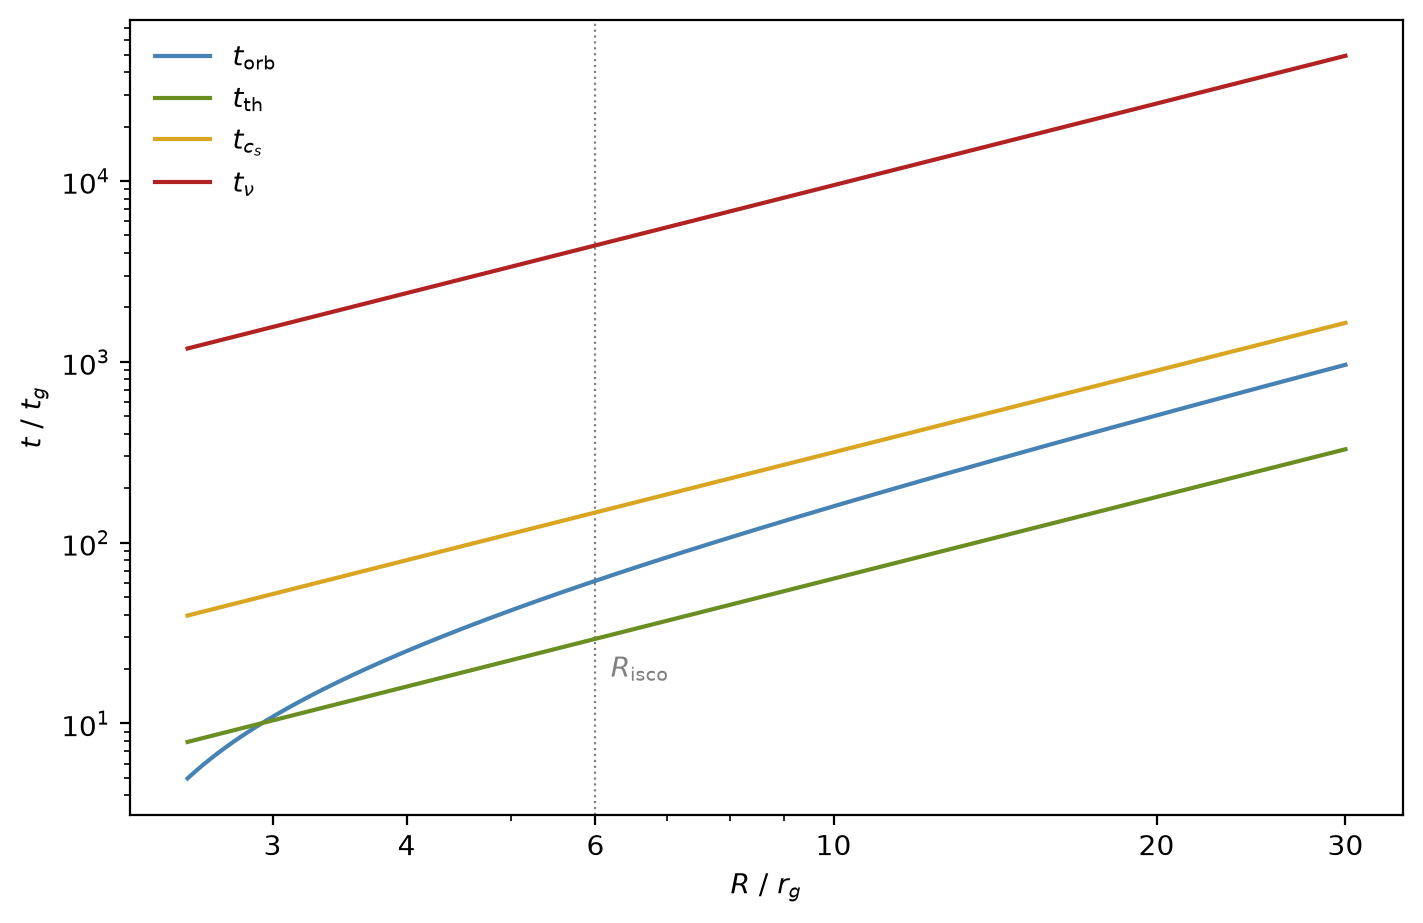

R =  6:  t_orb =     61.6   t_th =    29.4   t_cs =   147.0   t_nu =    4409.1   [t_g]
R = 10:  t_orb =    159.0   t_th =    63.2   t_cs =   316.2   t_nu =    9486.8   [t_g]
R = 15:  t_orb =    316.4   t_th =   116.2   t_cs =   580.9   t_nu =   17428.4   [t_g]
R = 20:  t_orb =    505.8   t_th =   178.9   t_cs =   894.4   t_nu =   26832.8   [t_g]
R = 30:  t_orb =    963.6   t_th =   328.6   t_cs =  1643.2   t_nu =   49295.0   [t_g]


In [5]:
R_plot = np.geomspace(2.5, 30, 300)

fig, ax = plt.subplots(figsize=[7, 4.5])

ax.axvline(6.0, color='gray', lw=0.8, ls=':')

ax.plot(R_plot, t_orbit(R_plot), label=r'$t_\mathrm{orb}$')
ax.plot(R_plot, t_thermal(R_plot), label=r'$t_\mathrm{th}$')
ax.plot(R_plot, t_sound(R_plot), label=r'$t_{c_s}$')
ax.plot(R_plot, t_viscous(R_plot), label=r'$t_\nu$')

ax.text(6.2, 18, r'$R_\mathrm{isco}$', color='gray')

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xticks([3, 4, 6, 10, 20, 30])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())

ax.set_xlabel(r'$R\ /\ r_g$')
ax.set_ylabel(r'$t\ /\ t_g$')

ax.legend()

plt.show()

for R in [6, 10, 15, 20, 30]:
    print(f"R = {R:2d}:  t_orb = {t_orbit(R):8.1f}   t_th = {t_thermal(R):7.1f}   t_cs = {t_sound(R):7.1f}   t_nu = {t_viscous(R):9.1f}   [t_g]")

#### 0.8. Helpers

Regarding geometry, all edges come from the grid output, so all integrals use

$$\Delta\Omega_j = 2\pi\left(\cos\theta_{j-1/2} - \cos\theta_{j+1/2}\right)\qquad
\Delta V_{ij} = \frac{r_{i+1/2}^3 - r_{i-1/2}^3}{3}\,\Delta\Omega_j$$

for the exact cell volumes and solid angles.

Every frame is reduced to radial profiles and global scalars. Sums run over the simulated hemisphere and are doubled to the full sphere

$$\Sigma(r) = 2\sum_j \rho_{ij}\, r_i\, \Delta\theta_j \qquad
\dot M(r) = 2\, r^2 \sum_j \rho_{ij}\, v_{r,ij}\, \Delta\Omega_j \qquad
\dot M_\mathrm{acc} = -\dot M$$

with disk and corona parts weighted by $f$ and $1 - f$ respectively, and inflow and outflow parts split by the $v_r$ sign. Then $\Sigma$ is the column along $\theta$ at fixed $r$ which equals the vertical column $\int\rho\,\mathrm{d}z$ of a thin disk. The disk aspect ratio
is the $f\rho$ weighted root mean square height

$$
\frac{H}{R}(r) = \left[\frac{\sum_j f\rho\, \cot^2\theta_j\, \Delta\theta_j}{\sum_j f\rho\, \Delta\theta_j}\right]^{1/2}
$$

and

$$
M = 2\sum \rho\,\Delta V \qquad M_d = 2\sum f\rho\,\Delta V \qquad E_\mathrm{rad} = 2\sum E_r\,\Delta V \qquad
E_\mathrm{th} = 2\sum \frac{p}{\gamma - 1}\,\Delta V \qquad E_\mathrm{kin} = 2\sum \tfrac{1}{2}\rho v^2\,\Delta V \qquad
L(r) = 2\, r^2 \sum_j F_{r,ij}\, \Delta\Omega_j
$$

are the global scalars.

The mass of every radial shell is stored in two halves, inside and outside the $r_i$ cell centre, so that the mass between any two
cell centres follows exactly, useful for the control volume of the mass budget.

The optical depth from the pole along $\theta$ at fixed $r$ is $\tau(r,\theta) = \int_0^\theta \rho\,(\kappa_a +
\kappa_s)\, r\, \mathrm{d}\theta'$ and $\tau = 1$ marks the photosphere seen from above.

In [6]:
def read_grid(path):
    with open(os.path.join(path, 'grid.out')) as fh:
        lines = [l for l in fh if not l.startswith('#')]

    edges, k = [], 0
    while k < len(lines) and lines[k].strip():
        n = int(lines[k].split()[0])
        k += 1
        block = np.array([[float(v) for v in lines[k + m].split()[1:3]] for m in range(n)])
        edges.append(np.append(block[:, 0], block[-1, 1]))
        k += n

    return edges

def read_outputs(path):
    entries = {}
    with open(os.path.join(path, 'dbl.out')) as fh:
        for line in fh:
            s = line.split()
            if len(s) > 1:
                entries[int(s[0])] = float(s[1])

    outs = np.array(sorted(entries))
    return outs, np.array([entries[n] for n in outs])

def make_geometry(path):
    R_E, TH_E = read_grid(path)[:2]
    R_C = 0.5 * (R_E[1:] + R_E[:-1])
    TH_C = 0.5 * (TH_E[1:] + TH_E[:-1])
    DOM = 2.0 * np.pi * (np.cos(TH_E[:-1]) - np.cos(TH_E[1:]))

    return dict(
        R_E=R_E, TH_E=TH_E, R_C=R_C, TH_C=TH_C, NR=R_C.size, NTH=TH_C.size,
        DTH=np.diff(TH_E), DOM=DOM,
        DV=((R_E[1:]**3 - R_E[:-1]**3) / 3.0)[:, None] * DOM[None, :],
        COT=np.cos(TH_C) / np.sin(TH_C),
        DV_LO=((R_C**3 - R_E[:-1]**3) / 3.0)[:, None] * DOM[None, :],
        DV_HI=((R_E[1:]**3 - R_C**3) / 3.0)[:, None] * DOM[None, :],
    )

MAIN_GEO = make_geometry(MAIN_PATH)
REF_GEO = make_geometry(REF_PATH) if REF_PATH is not None else None

R_E, TH_E, R_C, TH_C = (MAIN_GEO[k] for k in ['R_E', 'TH_E', 'R_C', 'TH_C'])
NR, NTH = MAIN_GEO['NR'], MAIN_GEO['NTH']
DTH, DOM, DV, COT = (MAIN_GEO[k] for k in ['DTH', 'DOM', 'DV', 'COT'])
DV_LO, DV_HI = MAIN_GEO['DV_LO'], MAIN_GEO['DV_HI']

for path, geo in [(MAIN_PATH, MAIN_GEO), (REF_PATH, REF_GEO)]:
    if geo is None:
        continue
    outs, times = read_outputs(path)
    print(f"{path}: grid {geo['NR']} x {geo['NTH']},  r in [{geo['R_E'][0]}, {geo['R_E'][-1]}],"
          f"  theta in [{geo['TH_E'][0]:.4f}, {geo['TH_E'][-1]:.4f}],  {outs.size} outputs,  t in [{times[0]:.1f}, {times[-1]:.1f}]")

VARS = ['rho', 'vx1', 'vx2', 'vx3', 'prs', 'enr', 'fr1', 'fr2', 'diskfrac', 'nu', 'kappa_abs', 'kappa_scat']

def load(n, path=MAIN_PATH, geo=MAIN_GEO):
    D = pp.Load(nout=int(n), path=path)
    shape = (geo['NR'], geo['NTH'])

    out = {}
    for v in VARS:
        a = np.asarray(getattr(D, v), dtype=float)
        assert a.shape == shape, f"{v} has shape {a.shape}, expected {shape}"
        out[v] = a

    return out

def gas_temperature(F):
    return K_T * F['prs'] / F['rho']

def rad_temperature(F):
    return (np.clip(F['enr'], 0.0, None) / A_RAD)**0.25

def optical_depth_from_pole(F, g=MAIN_GEO):
    dtau = F['rho'] * (F['kappa_abs'] + F['kappa_scat']) * g['R_C'][:, None] * g['DTH'][None, :]
    return np.cumsum(dtau, axis=1)

BH_VISC_RAD_HD_TRC_COMP_FIX/: grid 120 x 90,  r in [2.1, 30.0],  theta in [0.0000, 1.5708],  2601 outputs,  t in [0.0, 40000.0]
BH_VISC_RAD_HD_TRC_COMP/: grid 90 x 45,  r in [2.1, 30.0],  theta in [0.0000, 1.5708],  1001 outputs,  t in [0.0, 50000.0]


In [7]:
def reduce_frame(F, g):
    R_C, DTH, DOM, COT, DV = g['R_C'], g['DTH'], g['DOM'], g['COT'], g['DV']
    DV_LO, DV_HI = g['DV_LO'], g['DV_HI']

    rho, vr, f = F['rho'], F['vx1'], F['diskfrac']
    col = R_C[:, None] * DTH[None, :]
    flux = rho * vr * R_C[:, None]**2 * DOM[None, :]
    w = f * rho * DTH[None, :]
    v2 = F['vx1']**2 + F['vx2']**2 + F['vx3']**2
    i20 = int(np.argmin(np.abs(R_C - 20.0)))

    return dict(
        sigma      = HEMI * np.sum(rho * col, axis=1),
        mdot       = HEMI * np.sum(flux, axis=1),
        mdot_d     = HEMI * np.sum(f * flux, axis=1),
        mdot_c     = HEMI * np.sum((1.0 - f) * flux, axis=1),
        mdot_out   = HEMI * np.sum(np.where(vr > 0, flux, 0.0), axis=1),
        mdot_in    = HEMI * np.sum(np.where(vr < 0, flux, 0.0), axis=1),
        hr         = np.sqrt(np.sum(w * COT[None, :]**2, axis=1) / np.maximum(np.sum(w, axis=1), 1e-300)),
        rho_mid    = rho[:, -1],
        prs_mid    = F['prs'][:, -1],
        enr_mid    = F['enr'][:, -1],
        vr_mid     = vr[:, -1],
        vphi_mid   = F['vx3'][:, -1],
        nu_mid     = F['nu'][:, -1],
        f_mid      = F['diskfrac'][:, -1],
        m_lo       = HEMI * np.sum(rho * DV_LO, axis=1),
        m_hi       = HEMI * np.sum(rho * DV_HI, axis=1),
        M          = HEMI * np.sum(rho * DV),
        M_d        = HEMI * np.sum(f * rho * DV),
        M_c        = HEMI * np.sum((1.0 - f) * rho * DV),
        E_rad      = HEMI * np.sum(F['enr'] * DV),
        E_th       = HEMI * np.sum(F['prs'] / (GAMMA - 1.0) * DV),
        E_kin      = HEMI * np.sum(0.5 * rho * v2 * DV),
        L_out      = HEMI * R_C[-1]**2 * np.sum(F['fr1'][-1, :] * DOM),
        L_20       = HEMI * R_C[i20]**2 * np.sum(F['fr1'][i20, :] * DOM),
    )

CACHE_KEYS = set(reduce_frame({v: np.ones((MAIN_GEO['NR'], MAIN_GEO['NTH'])) for v in VARS}, MAIN_GEO))

def read_cache(cache, force, nr):
    if force or not os.path.exists(cache):
        return None
    with np.load(cache) as Z:
        old = {key: Z[key] for key in Z.files}

    if not CACHE_KEYS <= set(old) or old['r'].size != nr:
        print(f"cache {cache} incomplete for this notebook version, rebuilding it from all outputs")
        return None
    return old

def update_cache(path, geo, cache, force):
    outs_all, times_all = read_outputs(path)
    old = read_cache(cache, force, geo['NR'])

    index = {}
    if old is not None:
        index = {int(n): k for k, n in enumerate(old['outs'])}

    rows, n_new = [], 0
    for n, t in zip(outs_all, times_all):
        k = index.get(int(n))
        if k is not None and np.isclose(old['t'][k], t, rtol=1e-9, atol=1e-6):
            rows.append({key: old[key][k] for key in CACHE_KEYS})
        else:
            rows.append(reduce_frame(load(n, path, geo), geo))
            n_new += 1
            if n_new % 100 == 0:
                print(f"{path}: reduced {n_new} new outputs, now at {n} (t = {t:.0f})")

    C = {key: np.array([row[key] for row in rows]) for key in CACHE_KEYS}
    C['t'], C['outs'], C['r'] = times_all, outs_all, geo['R_C']

    if n_new > 0 or old is None or old['outs'].size != outs_all.size:
        np.savez_compressed(cache, **C)

    print(f"cache {cache}: {outs_all.size} outputs, {n_new} newly reduced")
    return C

C_MAIN = update_cache(MAIN_PATH, MAIN_GEO, MAIN_CACHE, MAIN_FORCE_REDUCE)
C_REF = update_cache(REF_PATH, REF_GEO, REF_CACHE, REF_FORCE_REDUCE) if REF_PATH is not None else None

cache BH_VISC_RAD_HD_TRC_COMP_FIX/analysis_cache.npz: 2601 outputs, 0 newly reduced
cache BH_VISC_RAD_HD_TRC_COMP/analysis_cache.npz: 1001 outputs, 0 newly reduced


#### 0.9. Sampling

The runs may mix output cadences, so two series are built from the cache, both with $t_\mathrm{min} \leq t \leq t_\mathrm{max}$ restriction. Contained in the long series are outputs at integer multiples of the set coarse step, a uniform sampling of the whole run. Relaxation, time averages and the snapshots of the evolution use it. On the other hand, the dense series is the final segment with a finer cadence, if there is one, starting at set threshold. It lies in the steady state, and the spectra, phase speeds and mass budget use it. Without a dense segment they use the steady window of the long series instead. Both runs are sampled the same way, each with its own switches.

In [8]:
def cadences(t):
    dts = np.diff(t)
    dts = dts[dts > 0]
    rounded = np.array([float(f"{x:.3g}") for x in dts])
    values, counts = np.unique(rounded, return_counts=True)
    frequent = values[counts >= 10]
    return frequent if frequent.size else np.array([np.median(dts)])

def long_indices(t, dt_long):
    phase = t / dt_long
    on_grid = np.abs(phase - np.round(phase)) < 0.02
    idx = np.nonzero(on_grid)[0]
    _, first = np.unique(np.round(phase[idx]).astype(int), return_index=True)
    return idx[first]

def dense_indices(t, dt_long, t_dense=None):
    fine = cadences(t).min()
    if t_dense is None:
        if fine > 0.5 * dt_long:
            return None
        jumps = np.nonzero(np.diff(t) > 1.5 * fine)[0]
        t_dense = t[jumps[-1] + 1] if jumps.size else t[0]
    idx = np.nonzero(t >= t_dense)[0]
    return idx if idx.size > 20 else None

def slice_cache(Cx, idx):
    n = Cx['t'].size
    return {key: (val[idx] if (np.ndim(val) > 0 and val.shape[0] == n and key != 'r') else val) for key, val in Cx.items()}

def make_series(Cx, label, dt_long=None, t_dense=None, t_min=None, t_max=None):
    t_all = Cx['t']
    keep = np.ones(t_all.size, dtype=bool)
    if t_min is not None: keep &= t_all >= t_min
    if t_max is not None: keep &= t_all <= t_max
    Cx = slice_cache(Cx, np.nonzero(keep)[0])
    t_all = Cx['t']

    dt_long = dt_long or cadences(t_all).max()
    il = long_indices(t_all, dt_long)
    gaps = np.diff(t_all[il]) > 1.5 * dt_long
    if gaps.any():
        print(f"WARNING {label}: {gaps.sum()} gaps in the long series, e.g. after t = {t_all[il][:-1][gaps][0]:.0f}")

    idn = dense_indices(t_all, dt_long, t_dense)
    run = dict(label=label, r=Cx['r'], all=Cx, C=slice_cache(Cx, il), dt=dt_long,
               D=None if idn is None else slice_cache(Cx, idn),
               dt_d=None if idn is None else float(np.median(np.diff(t_all[idn]))))
    run['t'] = run['C']['t']

    msg = f"{label}: long series {run['t'].size} frames at cadence {dt_long:g}, t in [{run['t'][0]:.0f}, {run['t'][-1]:.0f}]"
    if run['D'] is not None:
        msg += f" and dense segment {run['D']['t'].size} frames at cadence {run['dt_d']:g} from t = {run['D']['t'][0]:.0f}"
    print(msg)

    return run

RUN = make_series(C_MAIN, MAIN_LABEL, MAIN_DT_LONG, MAIN_T_DENSE, MAIN_T_MIN, MAIN_T_MAX)
RUN['dth_mid'] = MAIN_GEO['DTH'][-1]
C, T, DT_OUT = RUN['C'], RUN['t'], RUN['dt']

REF = None
if REF_PATH is not None:
    REF = make_series(C_REF, REF_LABEL, REF_DT_LONG, REF_T_DENSE, REF_T_MIN, REF_T_MAX)
    REF['dth_mid'] = REF_GEO['DTH'][-1]

RUN['ls'], RUN['color'] = '-', 'steelblue'
if REF is not None:
    REF['ls'], REF['color'] = '-', 'firebrick'
RUNS = [RUN] + ([REF] if REF is not None else [])

class TableHeader:
    def __init__(self, text, color):
        self.text = text
        self.color = color

class TableHeaderHandler(HandlerBase):
    def legend_artist(self, legend, handle, fontsize, handlebox):
        x = 0.5 * handlebox.width - handlebox.xdescent
        y = 0.5 * handlebox.height - handlebox.ydescent
        text = Text(x, y, handle.text, color=handle.color, fontsize=fontsize, ha='center', va='center')
        handlebox.add_artist(text)
        return text

def run_legend(ax, color=False, lws=(1.0, 0.5), extra=(), **kw):
    handles = []
    for run, lw in zip(RUNS, lws):
        if color:
            handles.append(Line2D([], [], color=run['color'], ls=run['ls'], label=run['label']))
        else:
            handles.append(Line2D([], [], color='k', ls=run['ls'], lw=lw, label=run['label']))
    handles += [Line2D([], [], label=label, **{'color': 'k', **style}) for label, style in extra]
    return ax.legend(handles=handles, **kw)

def run_table(ax, rows, shared=(), columns=None, sample=True, side='left', **kw):
    if columns is None:
        columns = [(run['label'], run['color'], dict(color=run['color'])) for run in RUNS]
    blank = Line2D([], [], ls='none')
    handles, labels = [], []

    if side == 'left':
        handles += [blank] + [Line2D([], [], **({'color': 'k', **style} if sample else dict(ls='none'))) for _, style in rows]
        handles += [Line2D([], [], **{'color': 'k', **style}) for _, style in shared]
        labels += [''] + [label for label, _ in rows] + [label for label, _ in shared]

    for j, (text, color, over) in enumerate(columns):
        last = side == 'right' and j == len(columns) - 1
        handles += [TableHeader(text, color)] + [Line2D([], [], **{'color': 'k', **style, **over}) for _, style in rows]
        handles += [blank] * len(shared)
        labels += [''] + [label if last else '' for label, _ in rows] + [''] * len(shared)

    opts = dict(ncol=len(columns) + (side == 'left'), columnspacing=0.6, handler_map={TableHeader: TableHeaderHandler()})
    if side == 'right':
        opts.update(columnspacing=0.3, handlelength=1.0, handletextpad=0.4)

    return ax.legend(handles, labels, **{**opts, **kw})

HR: long series 801 frames at cadence 50, t in [0, 40000] and dense segment 2001 frames at cadence 5 from t = 30000
LR: long series 1001 frames at cadence 50, t in [0, 50000]


### 1. Snapshots

In [9]:
SNAP_NORM = LogNorm(vmin=DFLOOR, vmax=0.2)
RHO_LABEL = r'$\rho\ /\ \rho_0$'
T_RANGE = RUN['all']['t']
O_RANGE = RUN['all']['outs']

FIELDS = {
    'rho':   dict(get=lambda F: F['rho'], norm=SNAP_NORM, cmap='magma', label=RHO_LABEL),
    'Tg':    dict(get=lambda F: gas_temperature(F), norm=LogNorm(vmin=1e4, vmax=1e12), cmap='inferno', label=r'$T_g\ /\ \mathrm{K}$'),
    'ratio': dict(get=lambda F: gas_temperature(F) / np.maximum(rad_temperature(F), 1.0), norm=LogNorm(vmin=1e-3, vmax=1e3), cmap='RdBu_r', label=r'$T_g / T_r$'),
    'f':     dict(get=lambda F: F['diskfrac'], norm=Normalize(vmin=0.0, vmax=1.0), cmap='coolwarm', label=None),
    'vr':    dict(get=lambda F: F['vx1'], norm=SymLogNorm(linthresh=1e-3, vmin=-1.0, vmax=1.0), cmap='RdBu_r', label=r'$v_r\ /\ c$'),
    'vphi':  dict(get=lambda F: F['vx3'], norm=Normalize(vmin=0.0, vmax=0.8), cmap='viridis', label=r'$v_\phi\ /\ c$'),
}

def nearest_out(t):
    k = T_RANGE.size - 1 if t is None else int(np.argmin(np.abs(T_RANGE - t)))
    return O_RANGE[k], T_RANGE[k]

def edges_mesh(g=MAIN_GEO):
    return (g['R_E'][:, None] * np.sin(g['TH_E'])[None, :], g['R_E'][:, None] * np.cos(g['TH_E'])[None, :])

def centers_mesh(g=MAIN_GEO):
    return (g['R_C'][:, None] * np.sin(g['TH_C'])[None, :], g['R_C'][:, None] * np.cos(g['TH_C'])[None, :])

def draw_map(ax, field, norm, cmap='magma', xlim=(0, 20), ylim=(0, 10), g=MAIN_GEO):
    Xe, Ze = edges_mesh(g)
    im = ax.pcolormesh(Xe, Ze, field, norm=norm, cmap=cmap, shading='flat', rasterized=True)
    ax.add_patch(plt.Circle((0, 0), g['R_E'][0], color='k', zorder=3))
    ax.set_facecolor('0.85' if xlim[1] >= g['R_E'][-1] else 'k')

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$R\ /\ r_g$')
    ax.set_ylabel(r'$z\ /\ r_g$')

    return im

def outline_map(ax, f, tau, lim, g=MAIN_GEO):
    Xc, Zc = centers_mesh(g)
    ax.set_facecolor('w')

    ax.contour(Xc, Zc, f, levels=[0.5], colors='k', linewidths=1.0)
    if np.nanmax(tau) > 1.0:
        ax.contour(Xc, Zc, tau, levels=[1.0], colors='k', linewidths=1.0, linestyles='--')

    th = np.linspace(0.0, 0.5 * np.pi, 200)
    ax.plot(g['R_E'][-1] * np.sin(th), g['R_E'][-1] * np.cos(th), 'k-', lw=1.0)
    ax.add_patch(plt.Circle((0, 0), g['R_E'][0], color='k', zorder=3))

    ax.set_xlim(*lim)
    ax.set_ylim(*lim)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$R\ /\ r_g$')
    ax.set_ylabel(r'$z\ /\ r_g$')

def add_colorbar(fig, im, cax, label):
    cb = fig.colorbar(im, cax=cax)
    if label is None:
        cb.set_ticks([0.0, 1.0])
        cb.set_ticklabels(['Corona', 'Disk'])
        cb.ax.minorticks_off()
    else:
        cb.set_label(label)

    return cb

def map_grid(n, ncol, xlim, ylim, width=5.2, cbar_mode='single'):
    ncol = min(ncol, n)
    nrow = int(np.ceil(n / ncol))
    height = width * (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])
    pad = (0.15, 0.15) if cbar_mode in ('single', None) else (1.1, 0.25)

    fig = plt.figure(figsize=[(width + pad[0]) * ncol + 1.2, (height + pad[1]) * nrow + 0.7], constrained_layout=False)
    grid = ImageGrid(fig, 111, (nrow, ncol), n, axes_pad=pad, share_all=True, label_mode='L',
                     cbar_mode=cbar_mode, cbar_location='right', cbar_size='3%', cbar_pad=0.08)
    return fig, grid

def hide_edge_labels(fig, grid, ncol, xlim):
    fig.canvas.draw()

    n = len(grid)
    for k, ax in enumerate(grid):
        has_right_neighbour = (k % ncol < ncol - 1) and (k < n - 1)
        if has_right_neighbour:
            for tick in ax.xaxis.get_major_ticks():
                if np.isclose(tick.get_loc(), xlim[1]):
                    tick.label1.set_visible(False)

def snapshot_rows(times, fields=tuple(FIELDS), xlim=(0, 20), ylim=(0, 10), ncol=3):
    times = [t for t in times if t is None or (T_RANGE[0] - DT_OUT <= t <= T_RANGE[-1] + DT_OUT)]
    if not times:
        print("no requested time lies in the analysed range")
        return

    frames = []
    for t_req in times:
        n, t = nearest_out(t_req)
        frames.append((t, load(n)))

    for key in fields:
        spec = FIELDS[key]
        fig, grid = map_grid(len(frames), ncol, xlim, ylim)

        for ax, (t, F) in zip(grid, frames):
            im = draw_map(ax, spec['get'](F), spec['norm'], cmap=spec['cmap'], xlim=xlim, ylim=ylim)
            ax.text(0.97, 0.93, f"$t = {t:.0f}\\ t_g$", color='w', ha='right', va='top', transform=ax.transAxes)

        add_colorbar(fig, im, grid.cbar_axes[0], spec['label'])
        hide_edge_labels(fig, grid, ncol, xlim)

        plt.show()

def full_domain(run, path, geo, fields=tuple(FIELDS), span=FULL_AVG_SPAN):
    n0 = run['all']['outs'][int(np.argmin(np.abs(run['all']['t'])))]
    sel = run['t'] >= run['t'][-1] - span

    acc = {}
    for n in run['C']['outs'][sel]:
        F = load(n, path, geo)
        for key, val in [('rho', F['rho']), ('Tg', gas_temperature(F)), ('Tr', rad_temperature(F)), ('f', F['diskfrac']),
                         ('vr', F['vx1']), ('vphi', F['vx3']), ('tau', optical_depth_from_pole(F, geo))]:
            acc[key] = acc.get(key, 0.0) + val

    mean = {key: val / sel.sum() for key, val in acc.items()}
    mean['ratio'] = mean['Tg'] / np.maximum(mean['Tr'], 1.0)

    F0 = load(n0, path, geo)
    lim = (0, geo['R_E'][-1])

    for key in fields:
        spec = FIELDS[key]
        fig, grid = map_grid(2, 2, lim, lim)

        im = draw_map(grid[0], spec['get'](F0), spec['norm'], cmap=spec['cmap'], xlim=lim, ylim=lim, g=geo)
        draw_map(grid[1], mean[key], spec['norm'], cmap=spec['cmap'], xlim=lim, ylim=lim, g=geo)
        add_colorbar(fig, im, grid.cbar_axes[0], spec['label'])

        plt.show()

    fig, grid = map_grid(2, 2, lim, lim, cbar_mode=None)

    outline_map(grid[0], F0['diskfrac'], optical_depth_from_pole(F0, geo), lim, g=geo)
    outline_map(grid[1], mean['f'], mean['tau'], lim, g=geo)

    plt.show()

#### 1.1. Global

Shown below is the full computational domain at initialization and averaged over the final steady state for density, temperatures, classifier as well as radial and azimuthal velocities. Additionally, the disk boundary $f = 0.5$ or $\langle f\rangle = 0.5$ and photosphere $\tau = 1$ or $\langle \tau\rangle = 1$ are shown as solid and dashed contours.

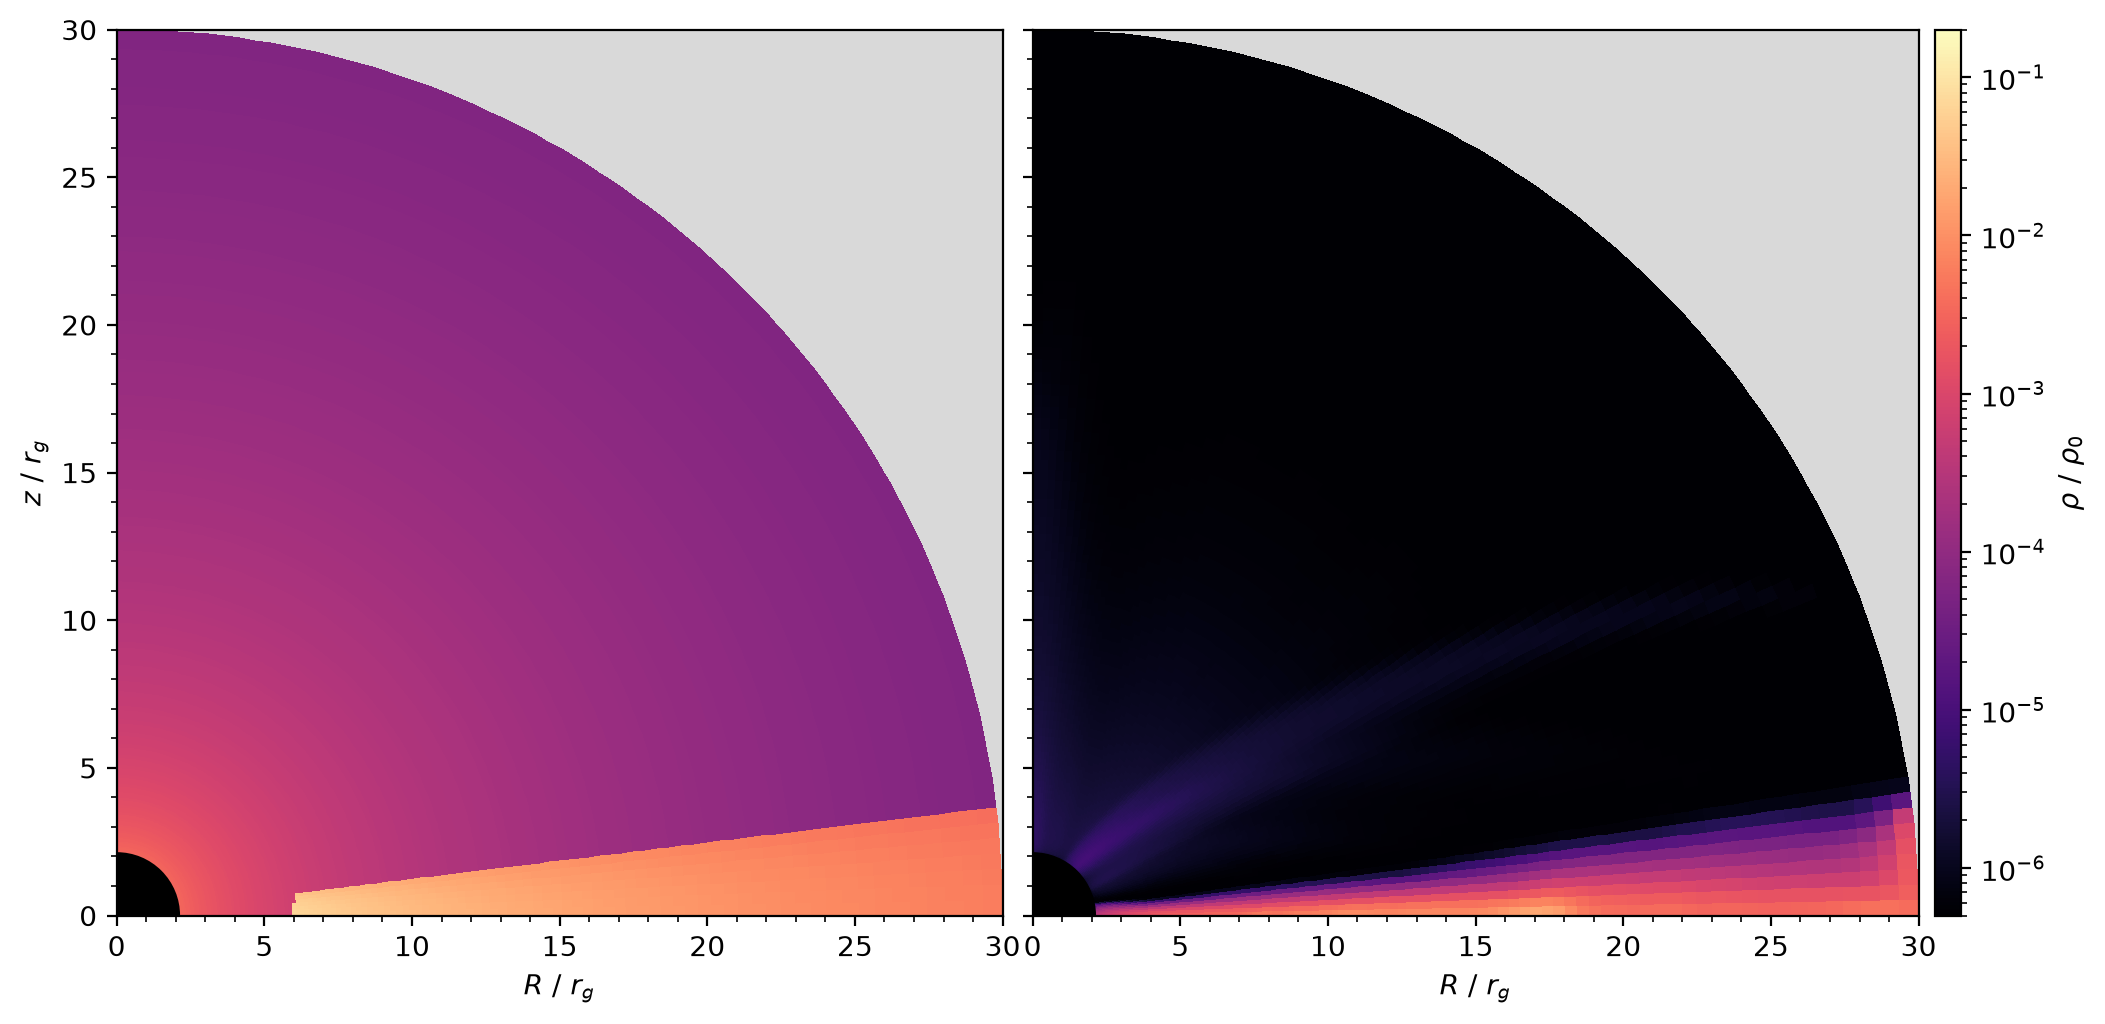

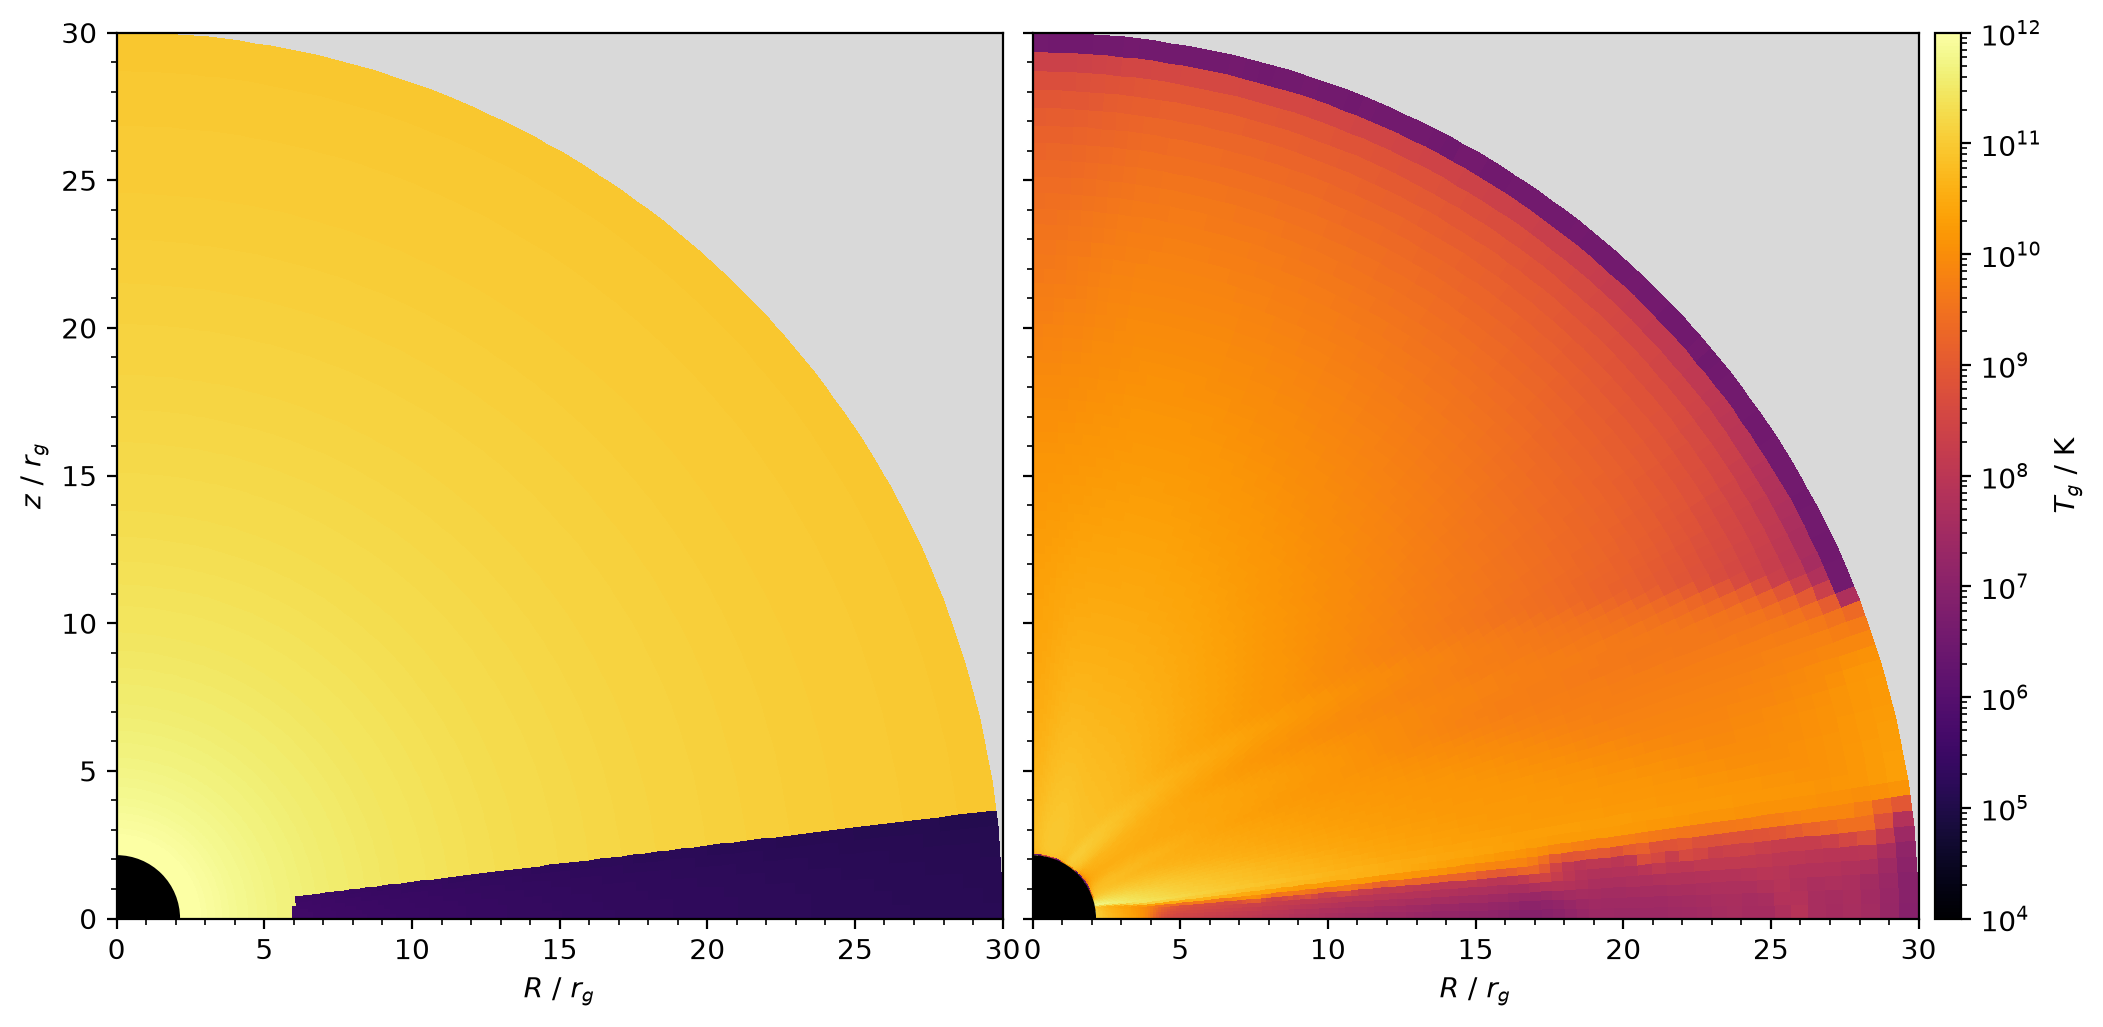

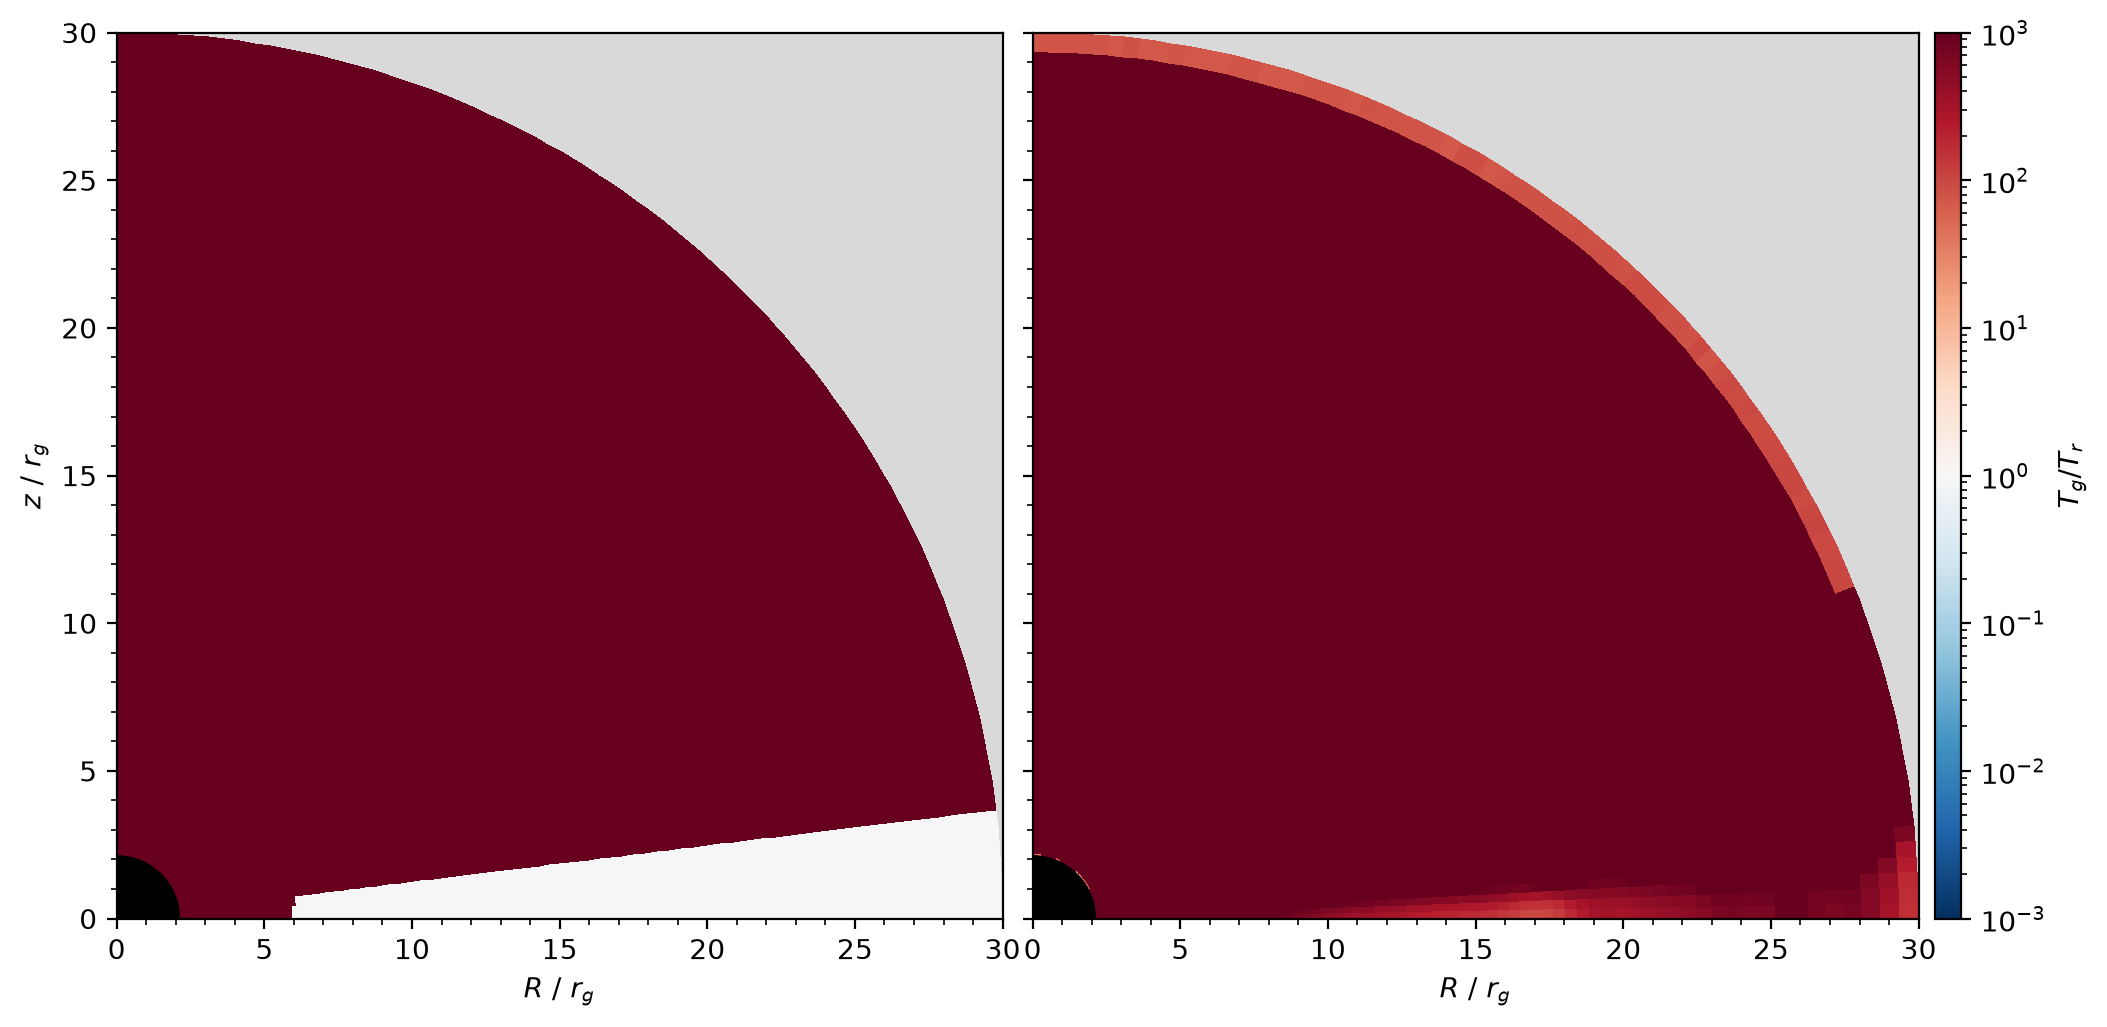

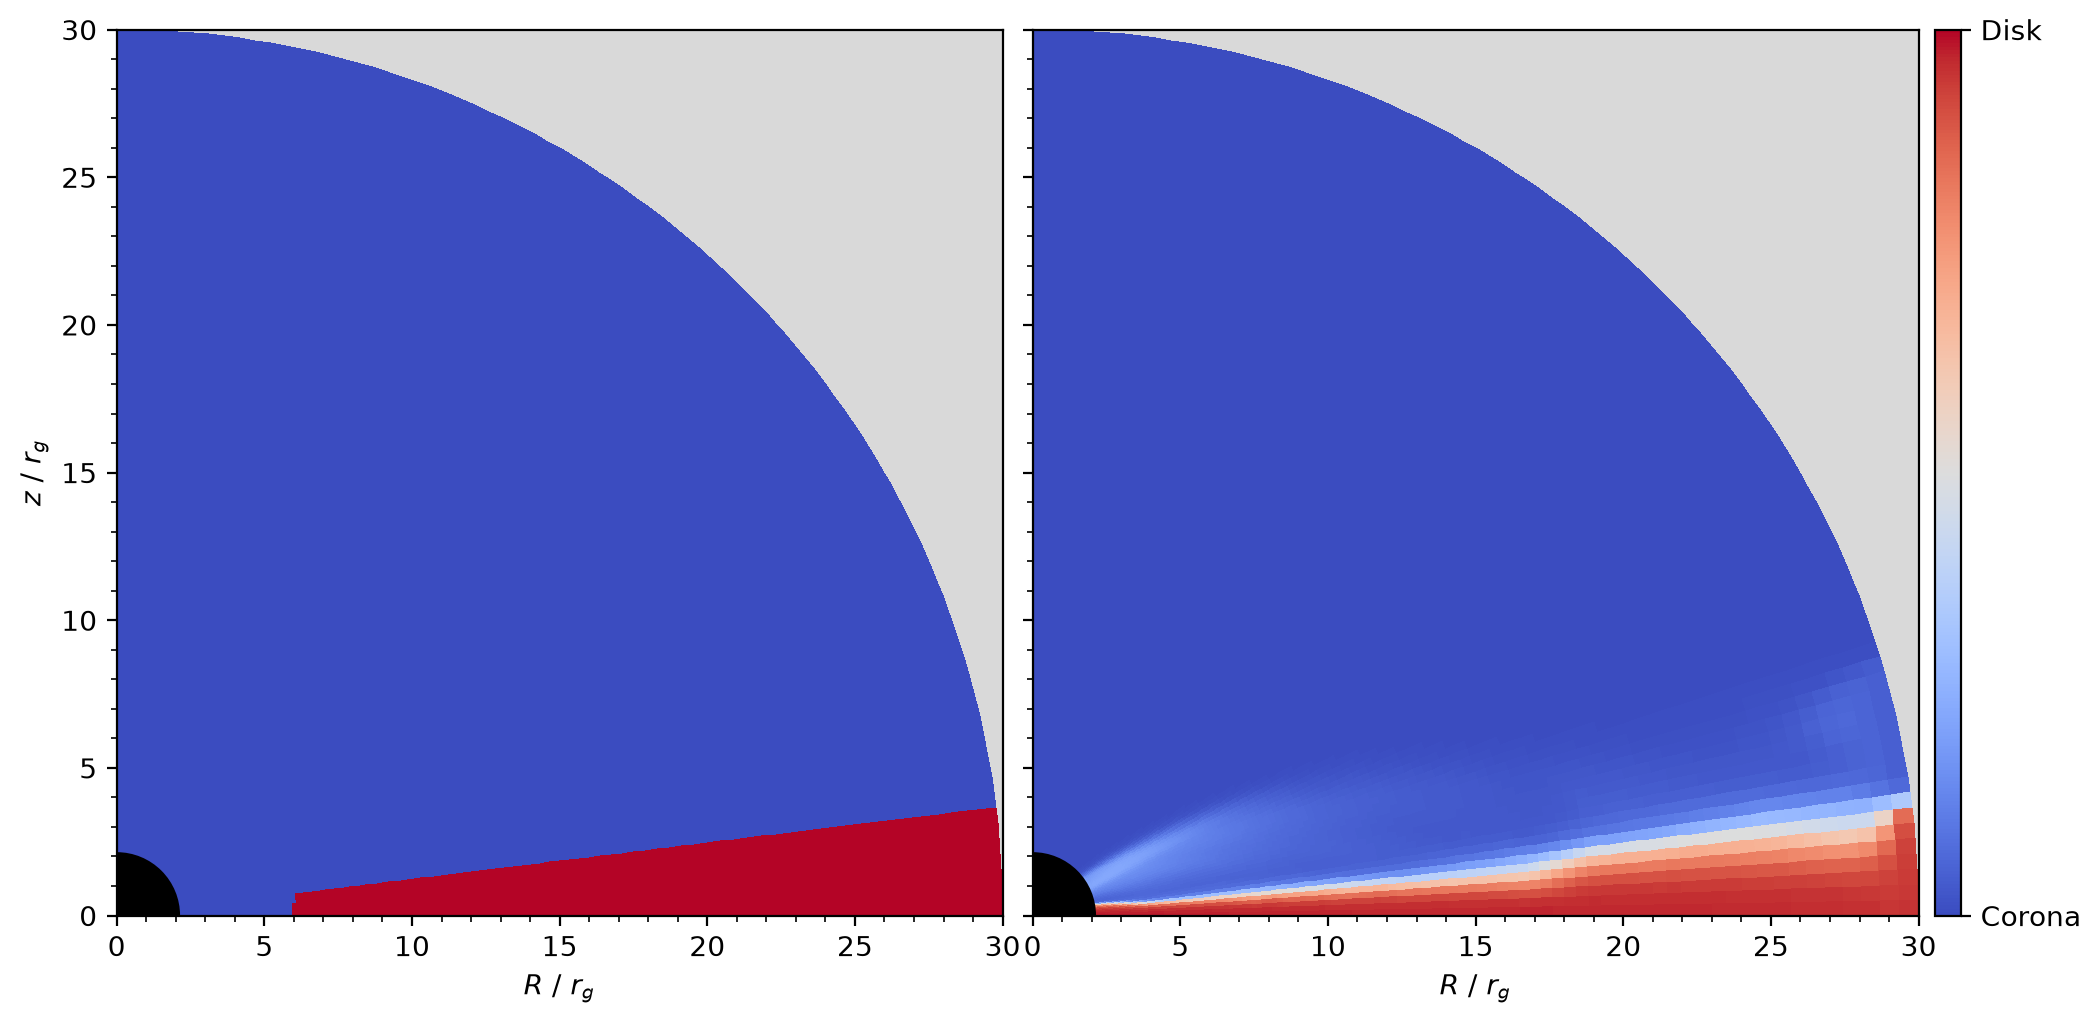

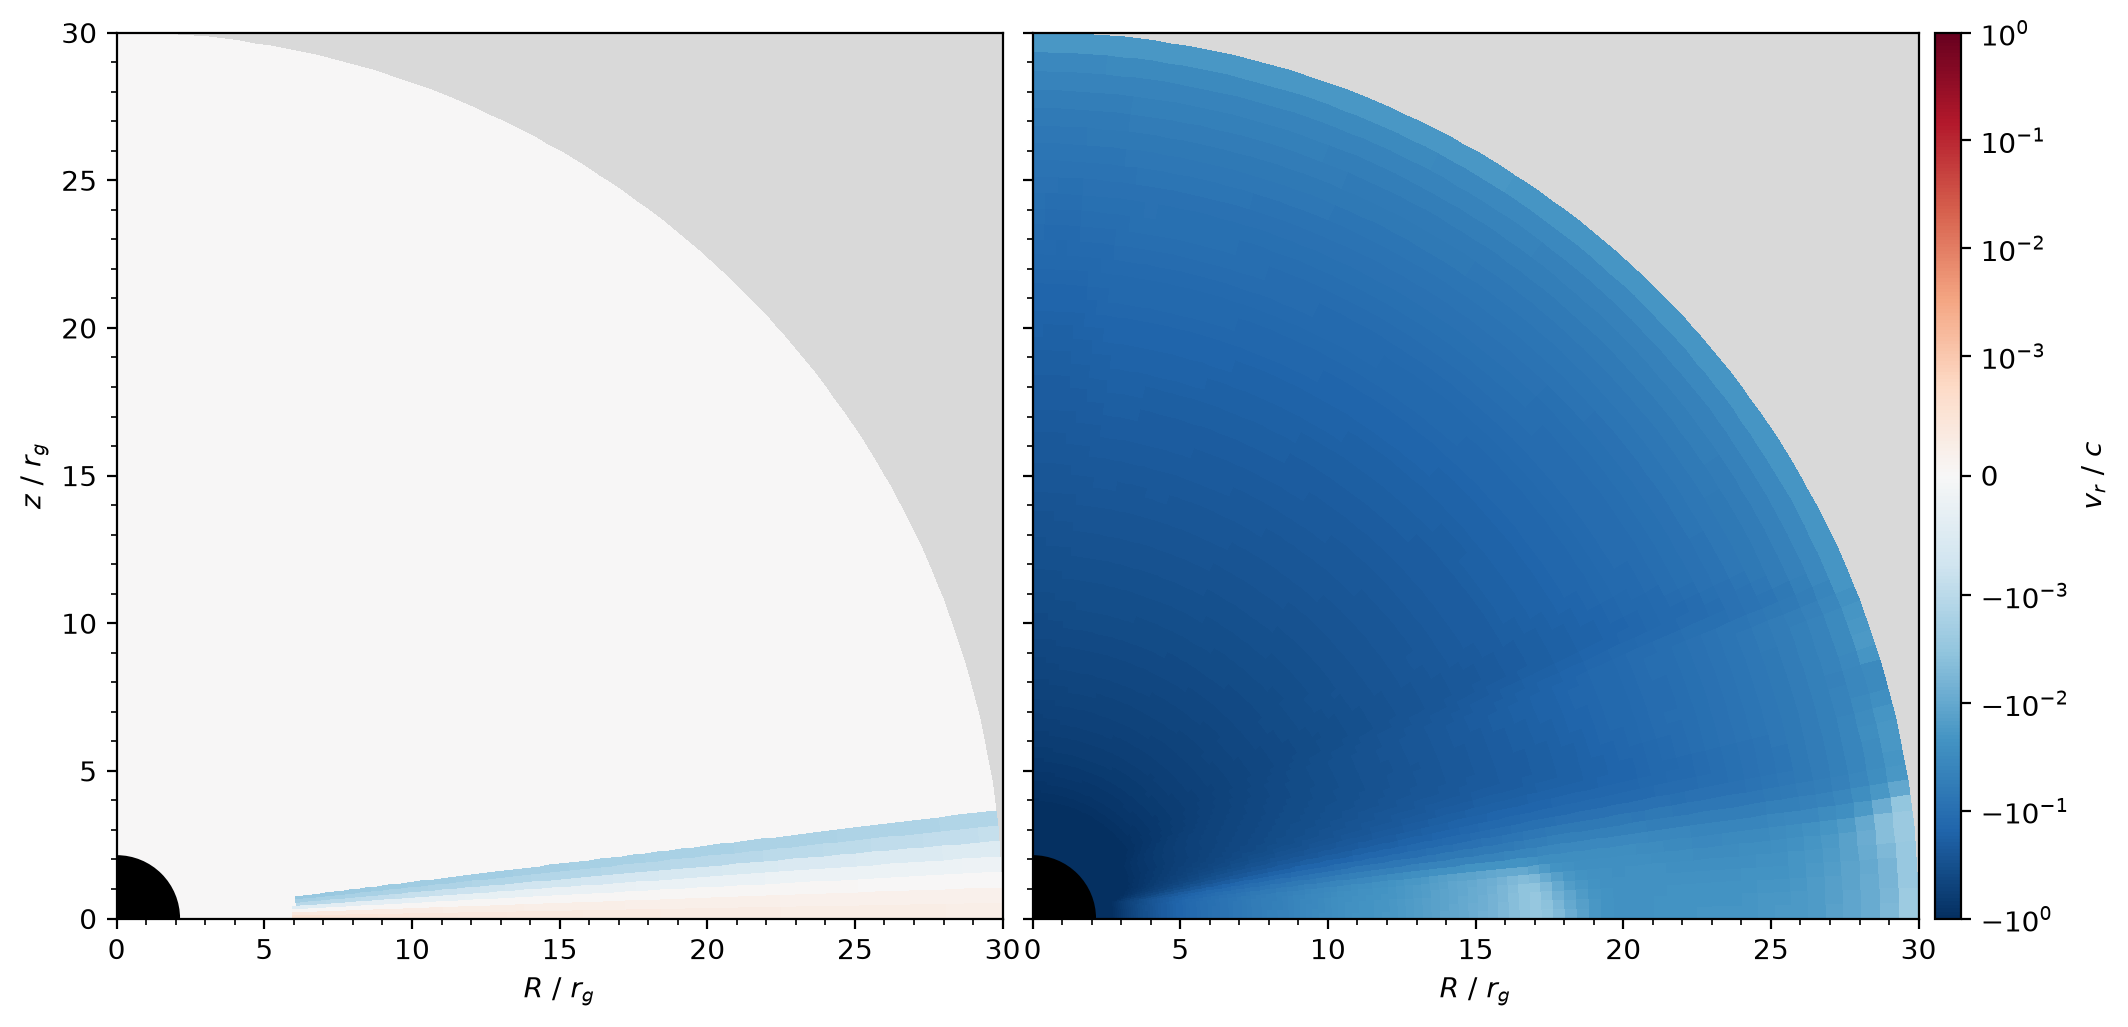

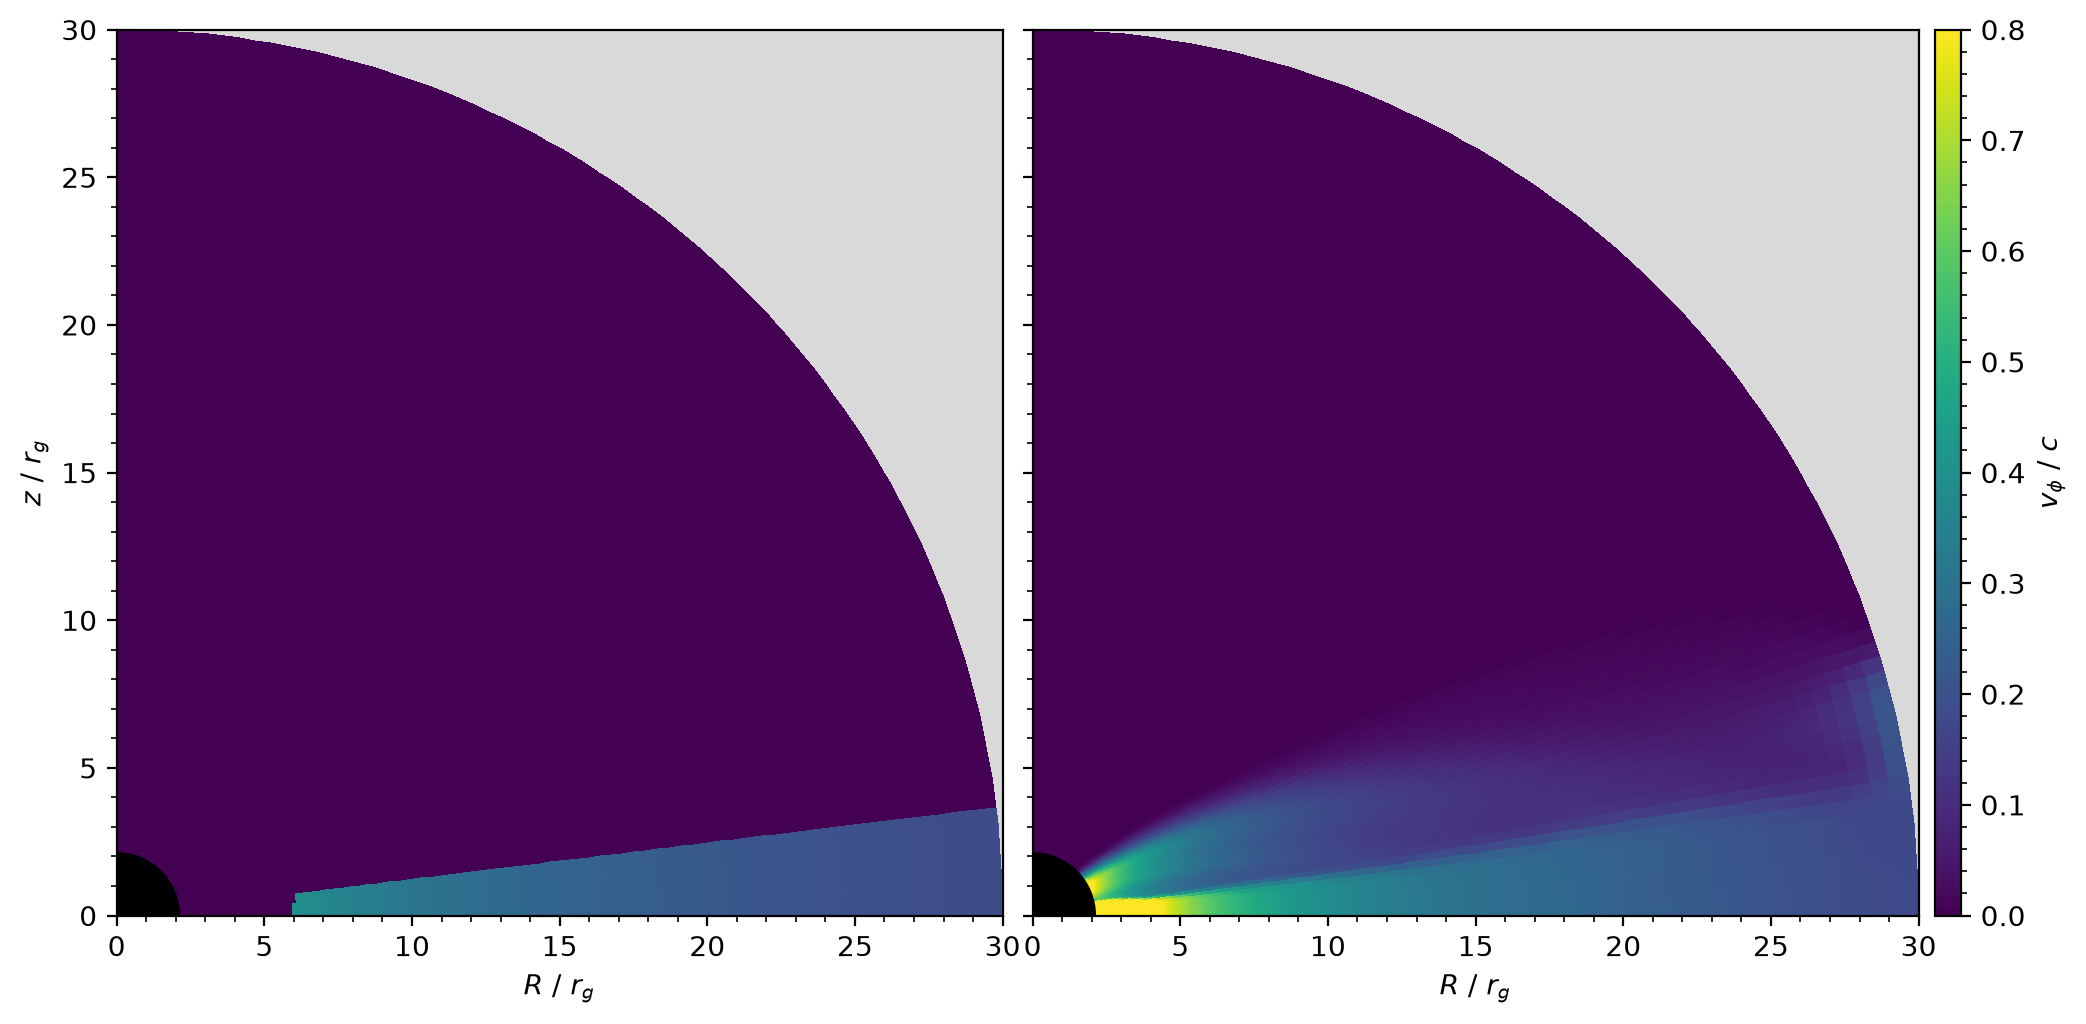

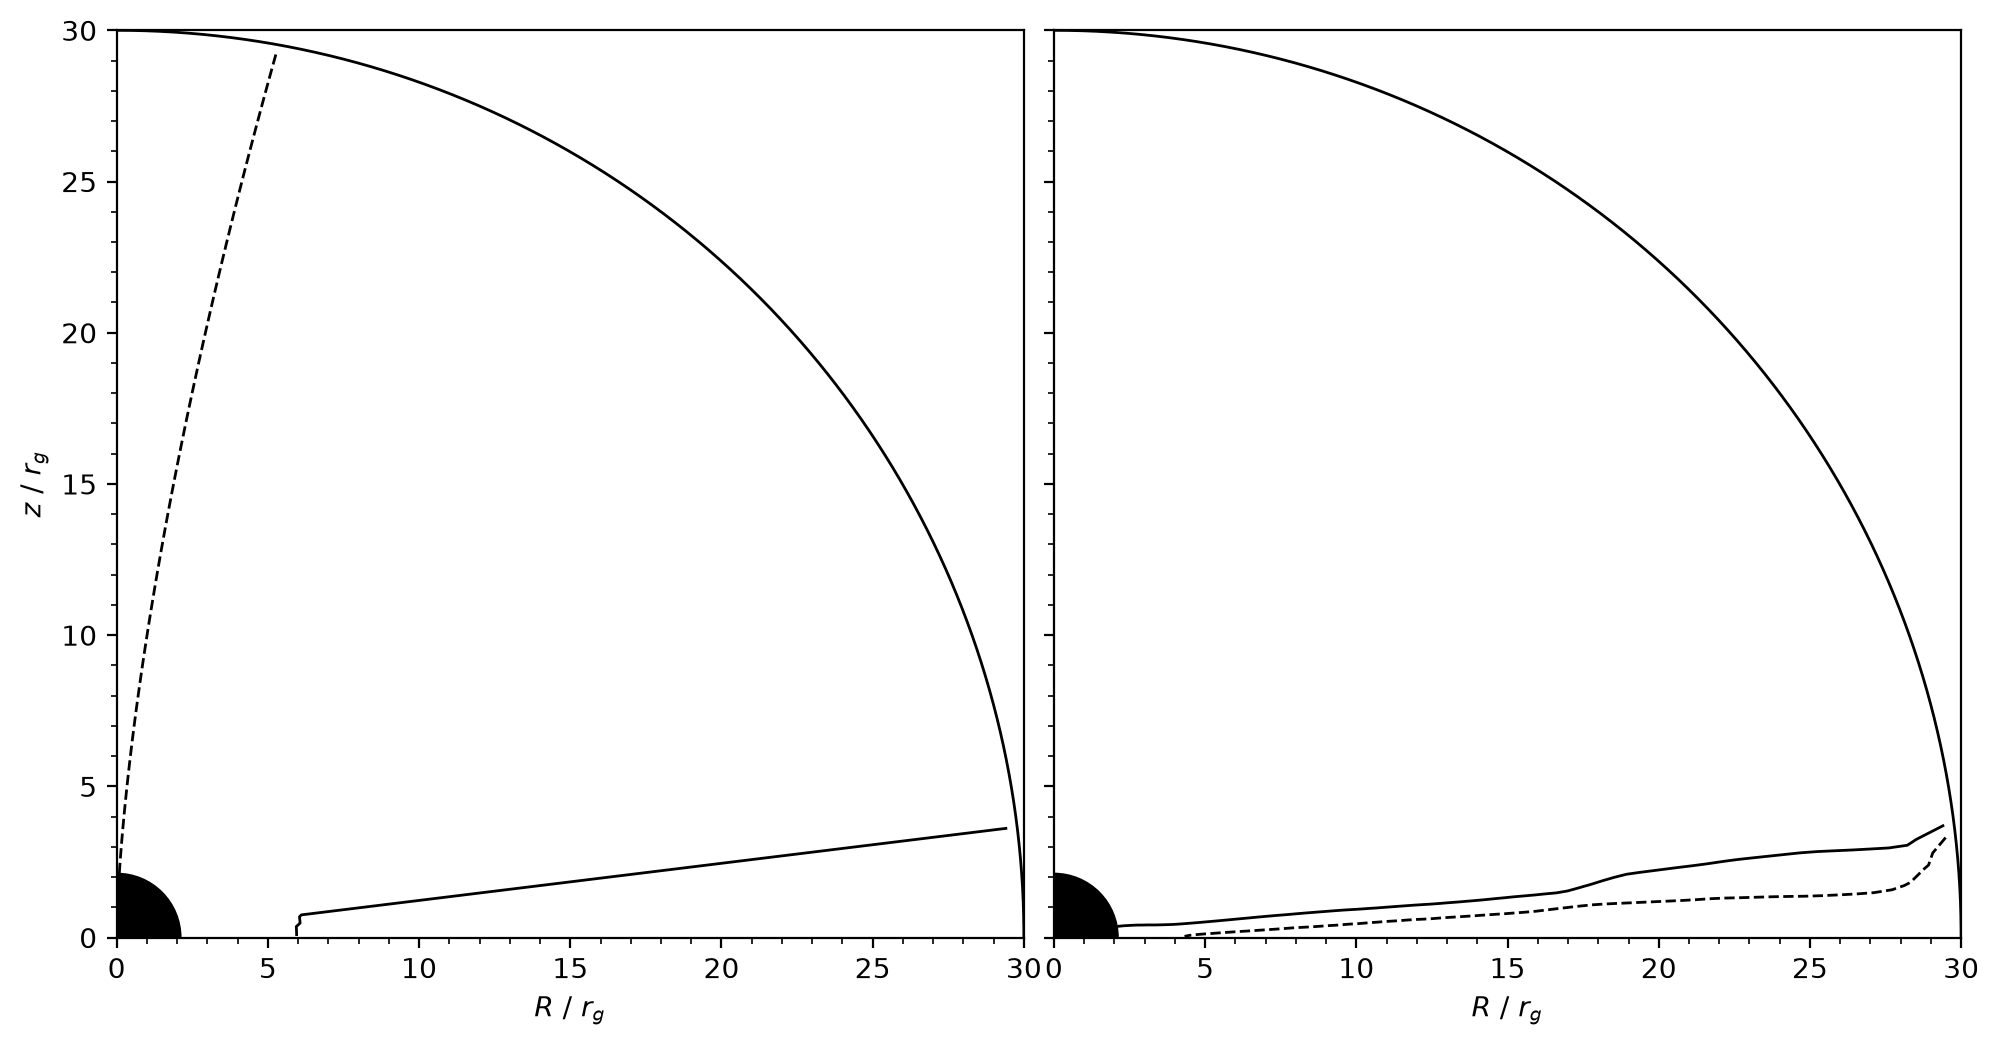

In [10]:
full_domain(RUN, MAIN_PATH, MAIN_GEO)

#### 1.2. Evolution

During early times, the radiation supported disk interior inflates and builds a dense surface layer, which then breaks apart.

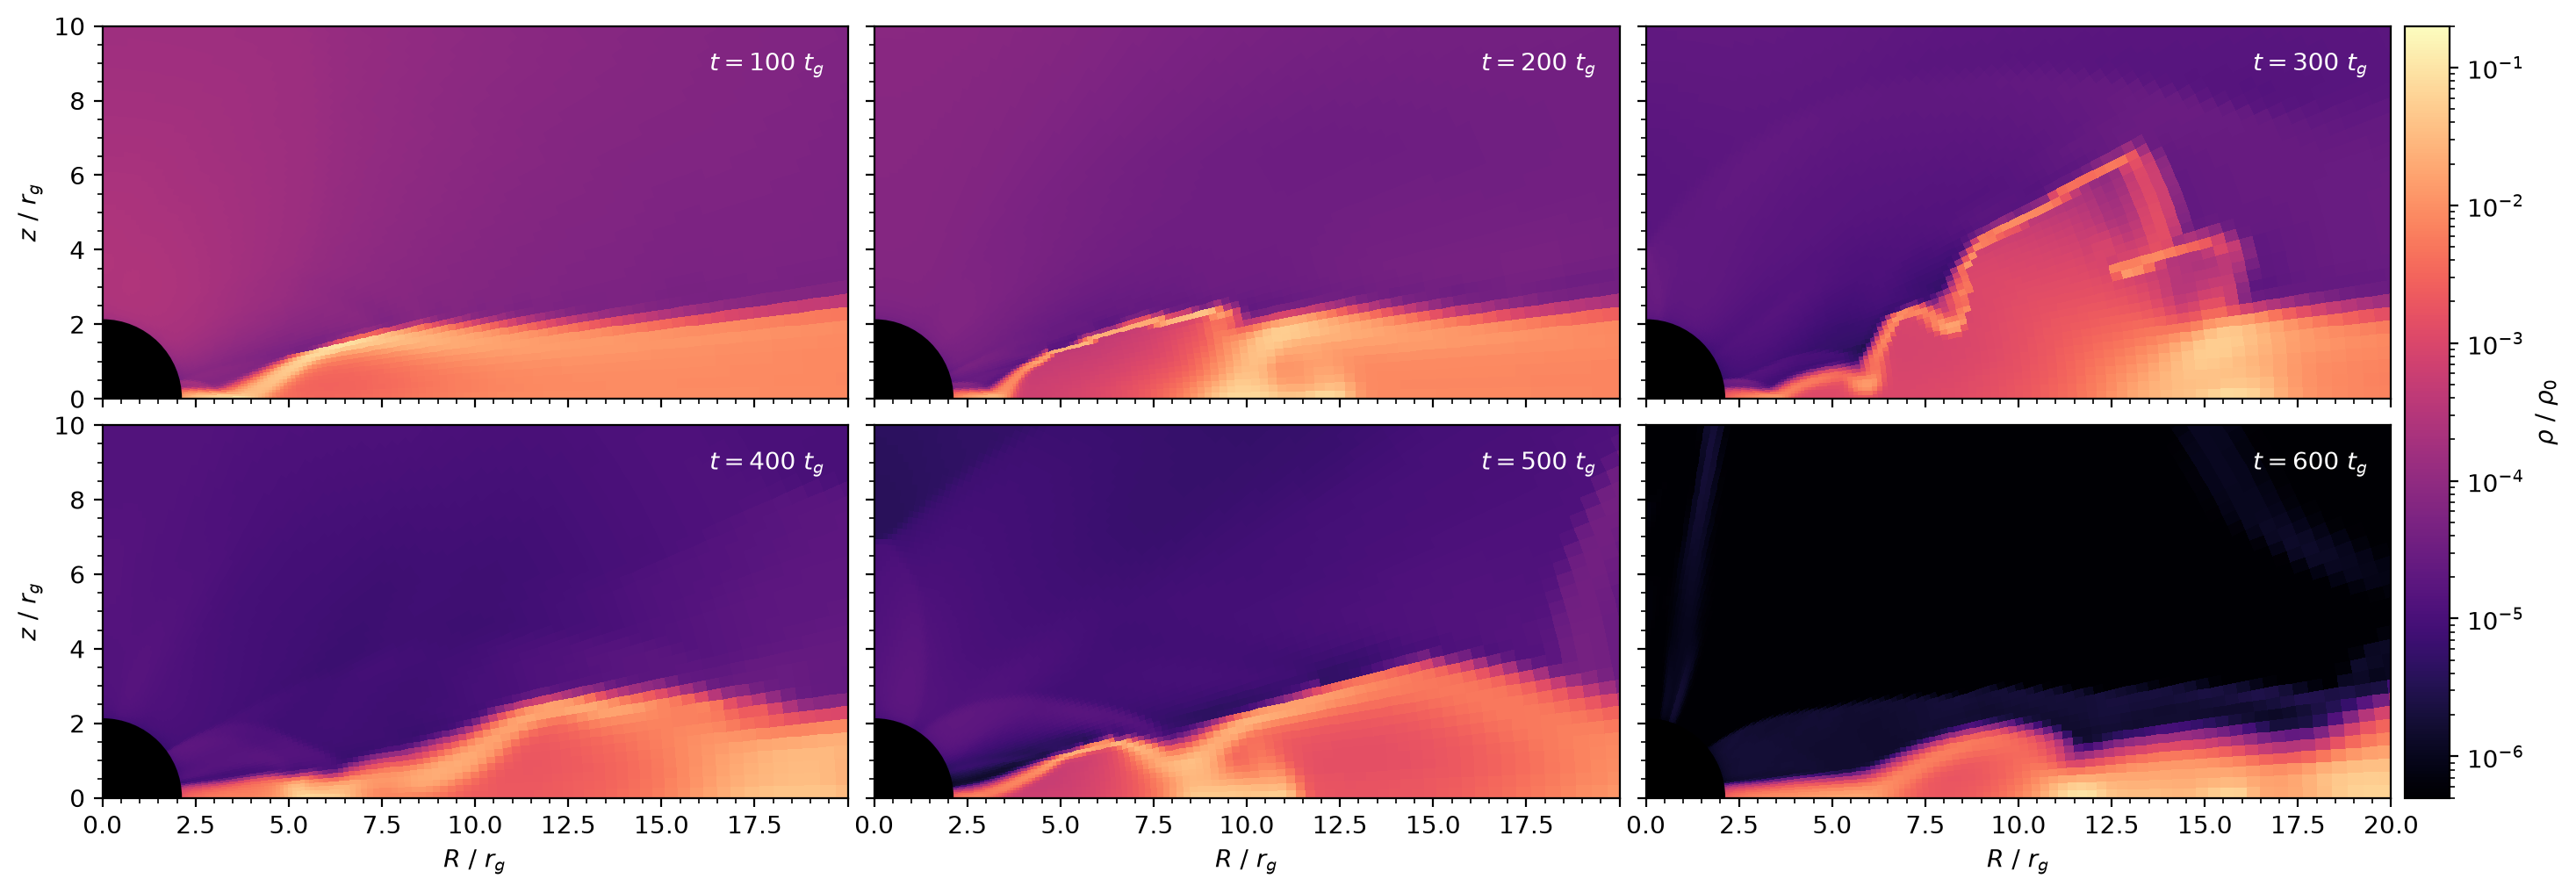

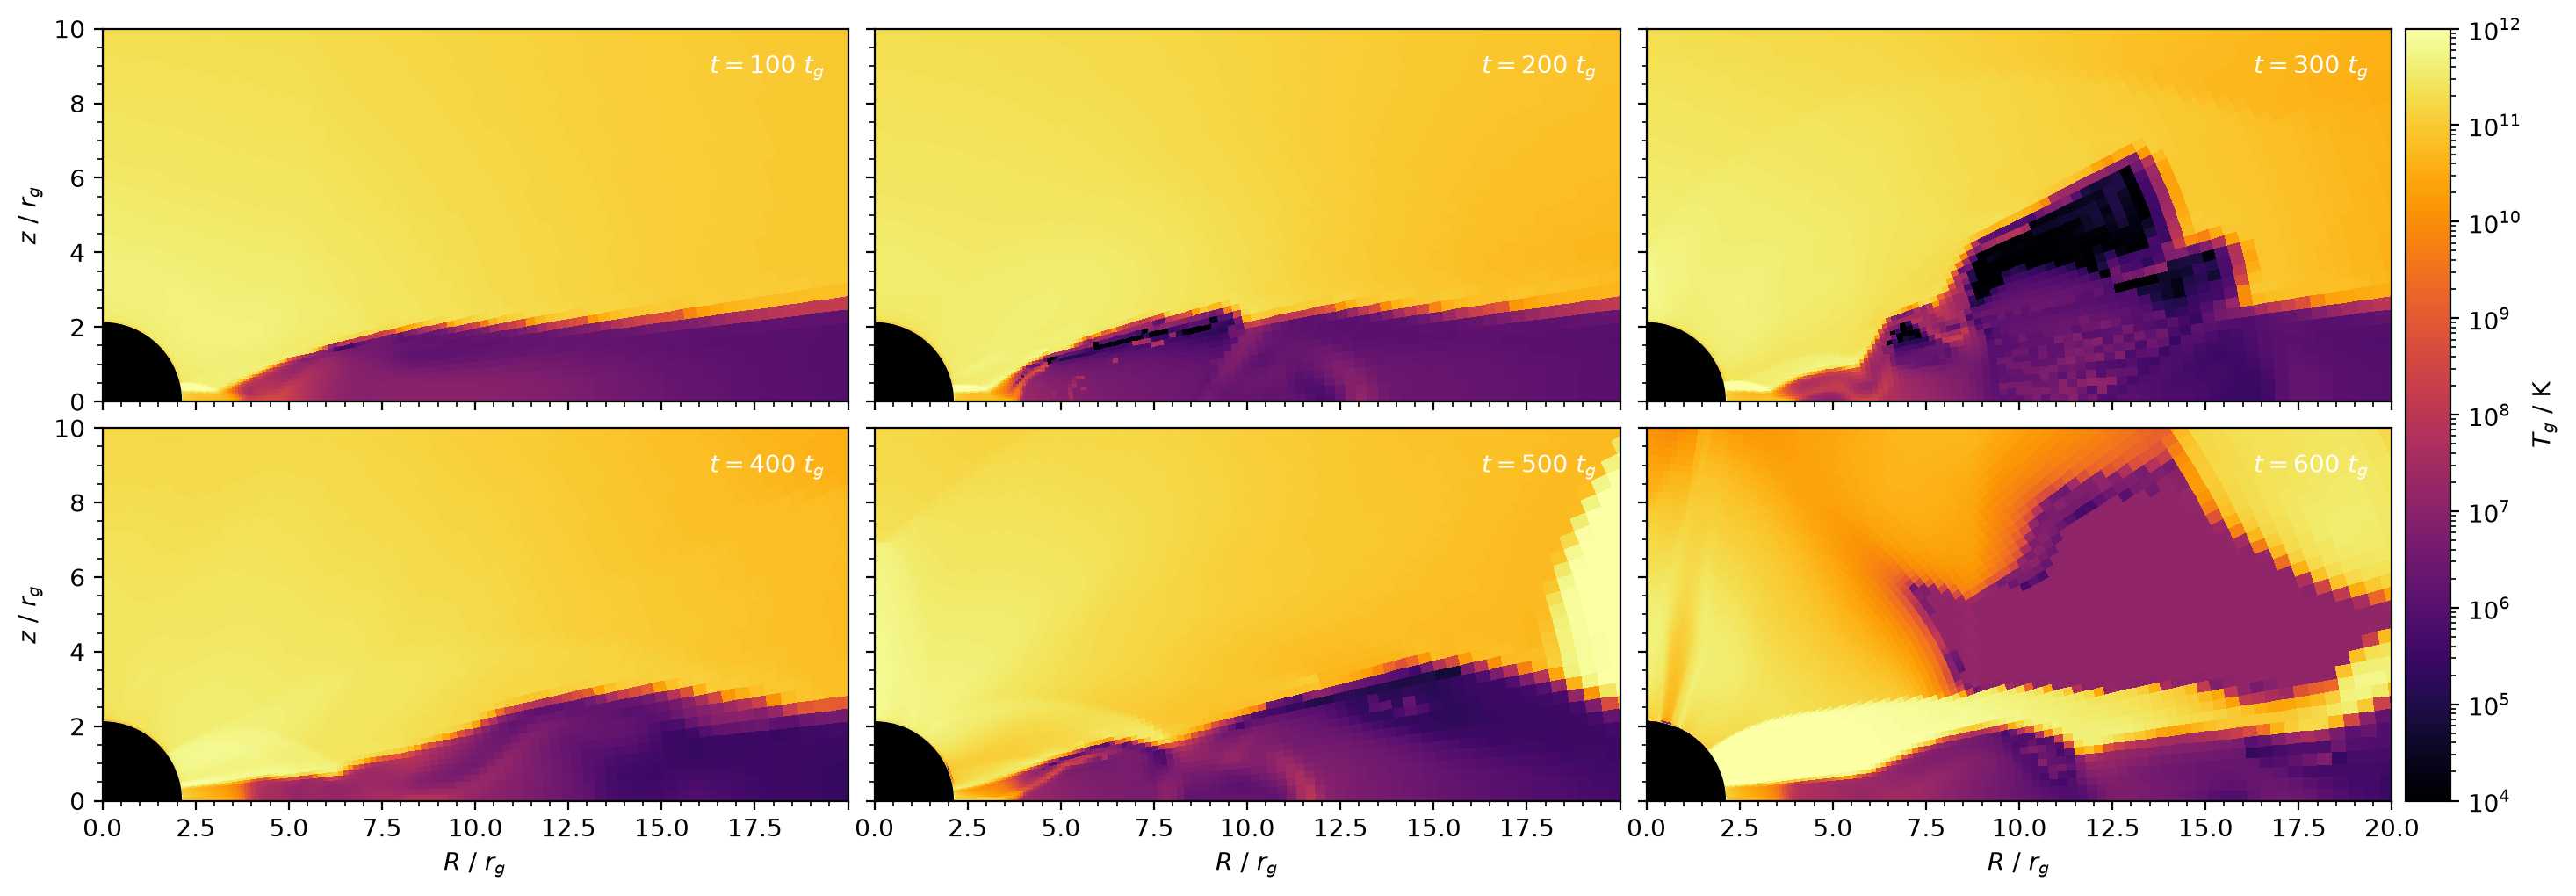

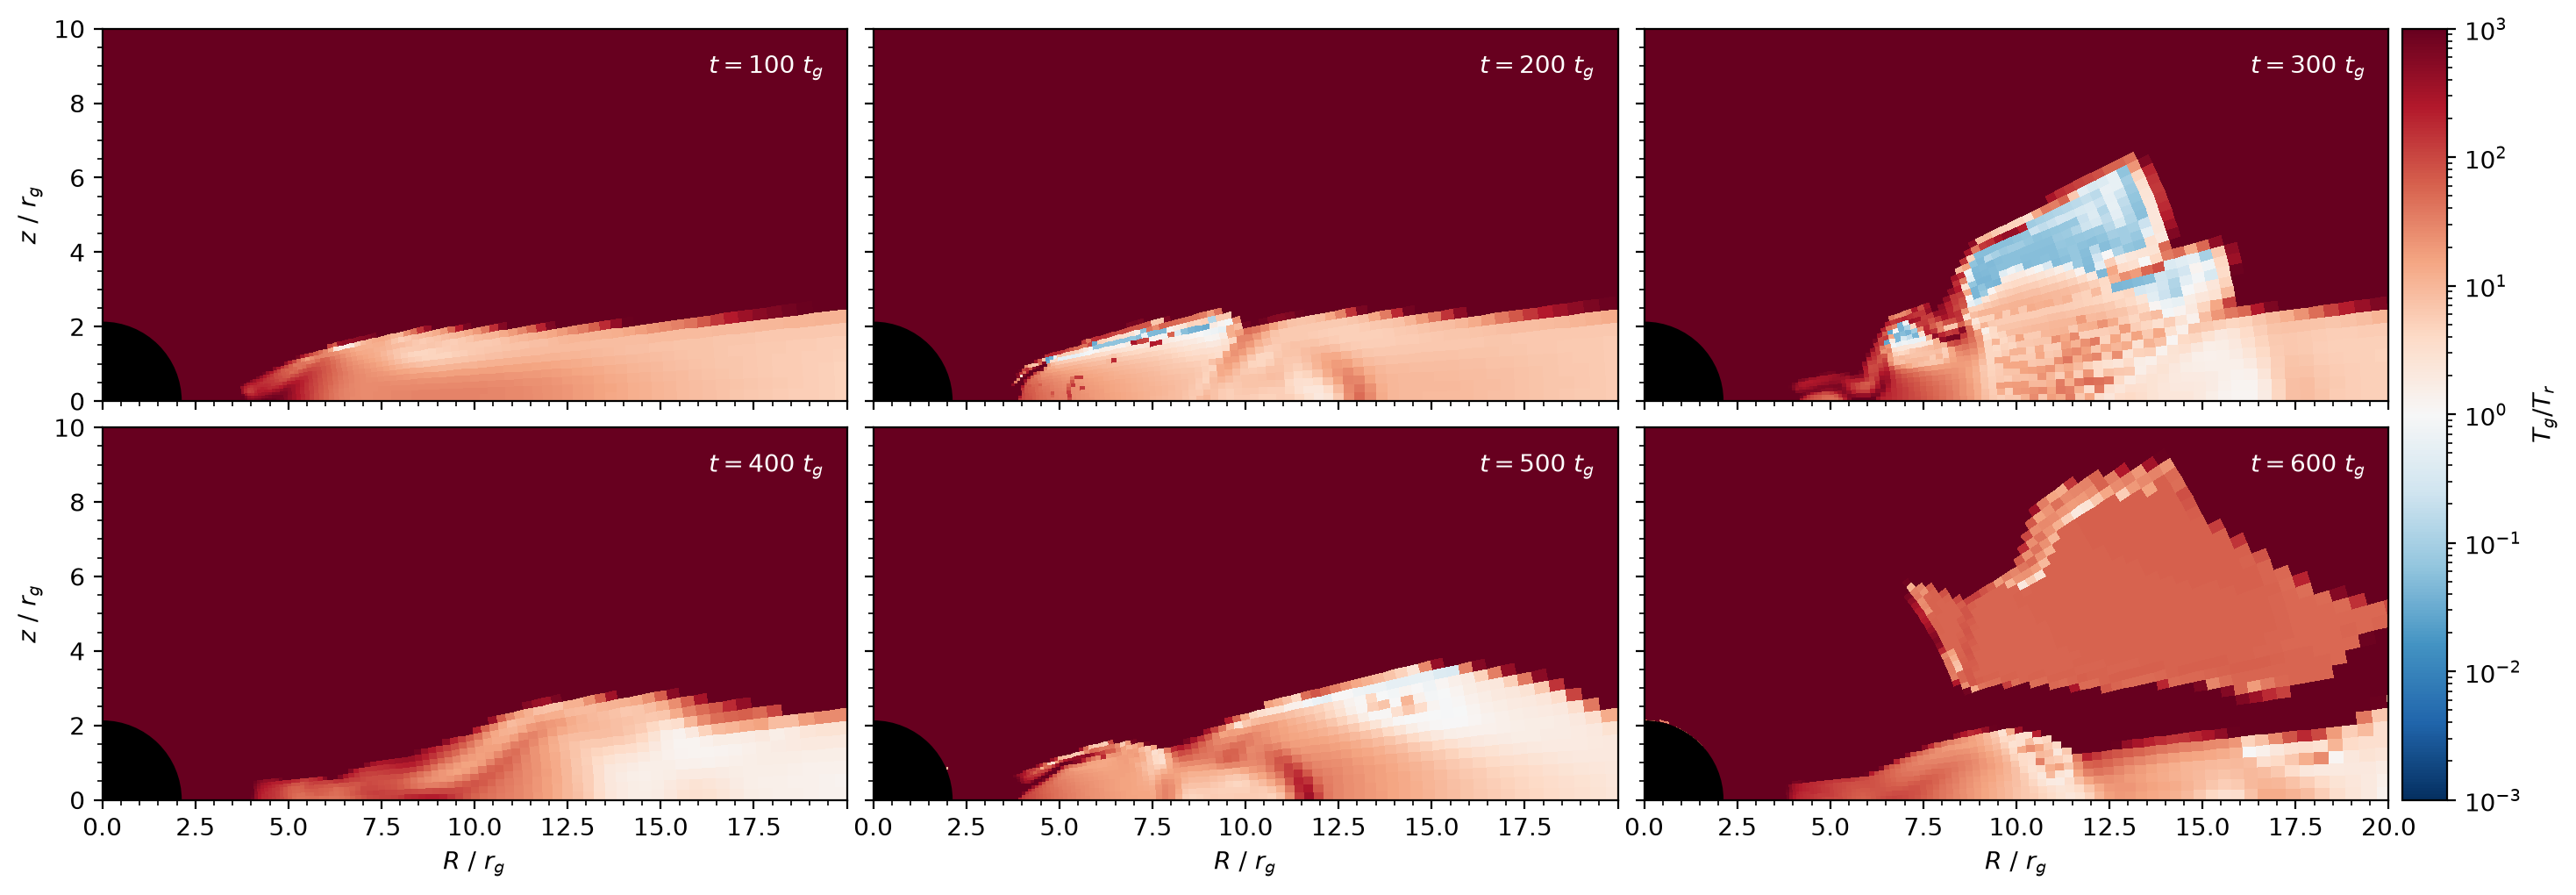

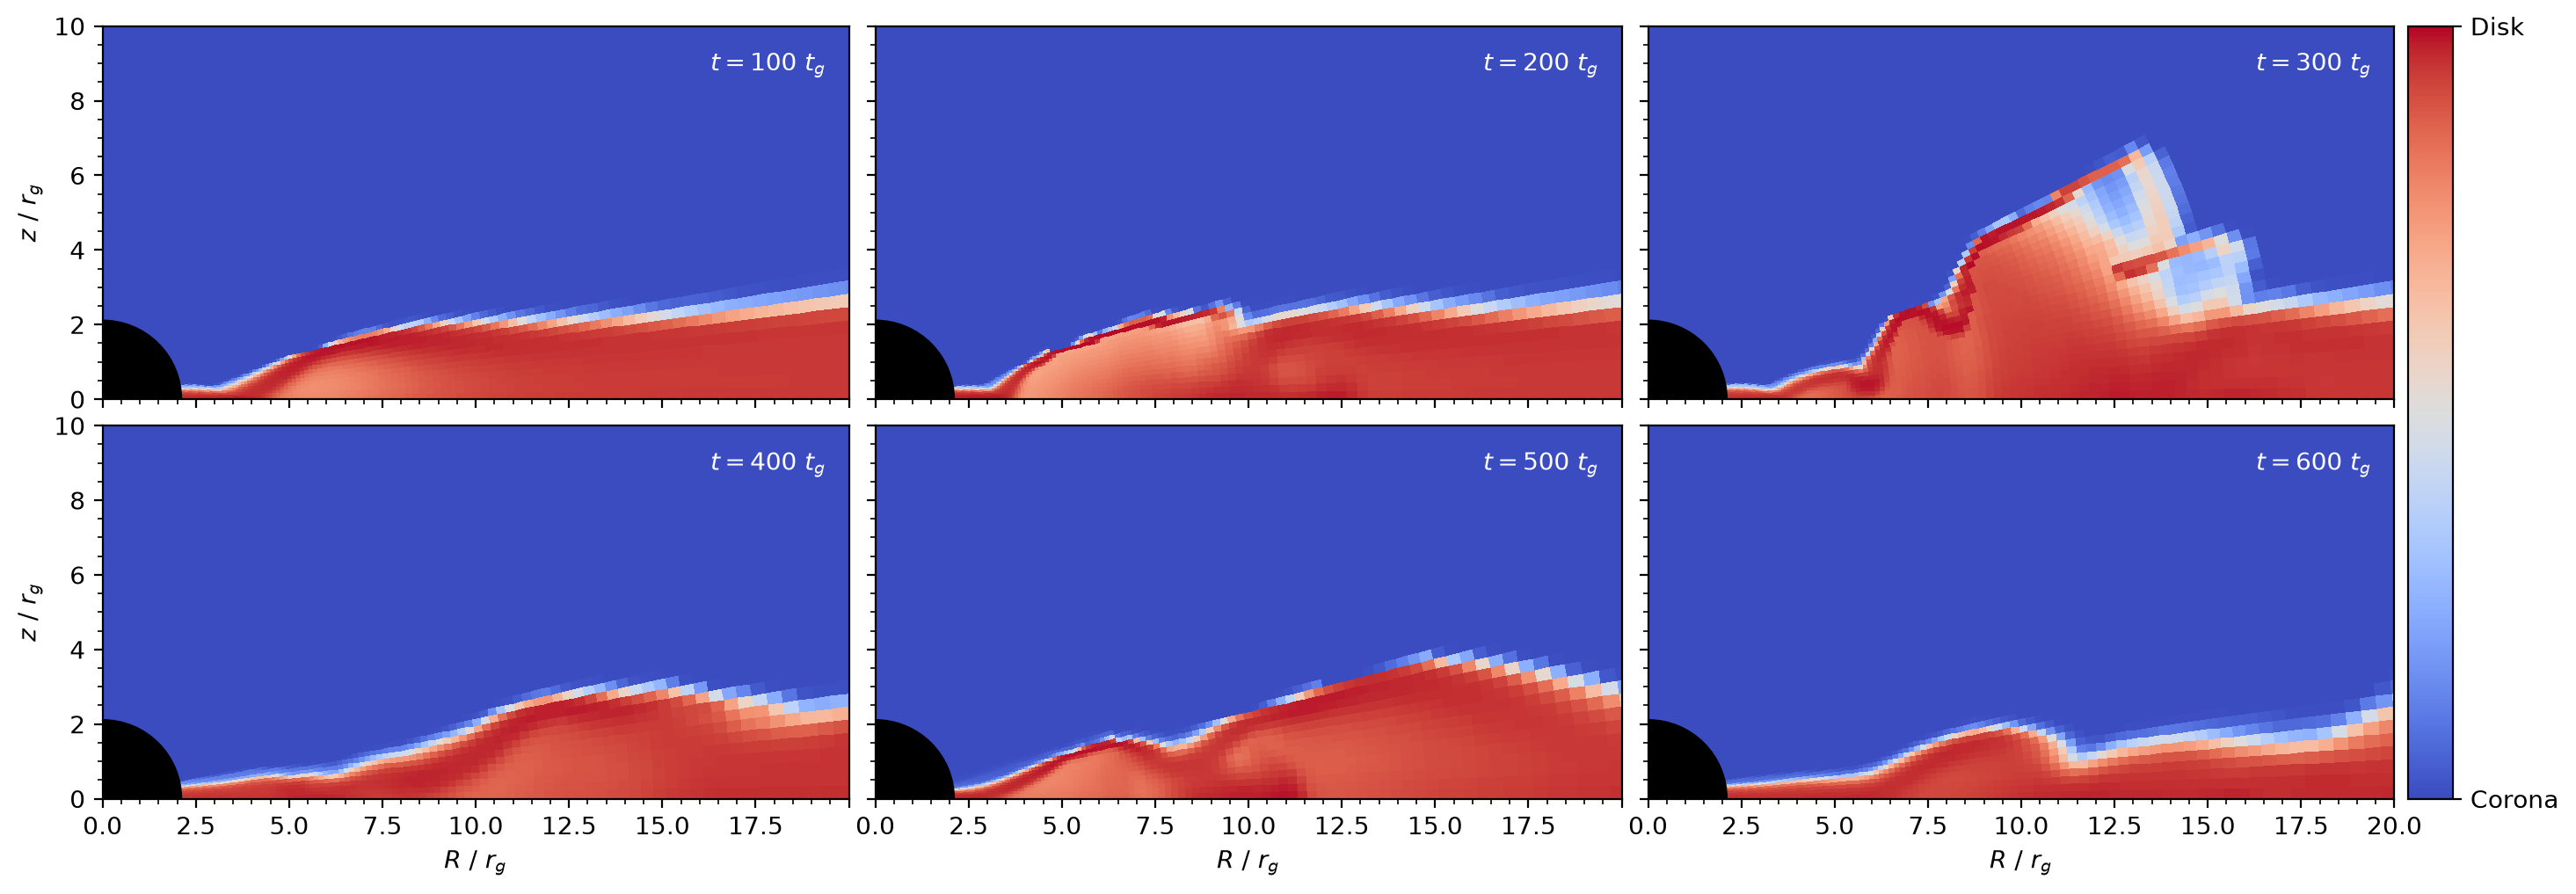

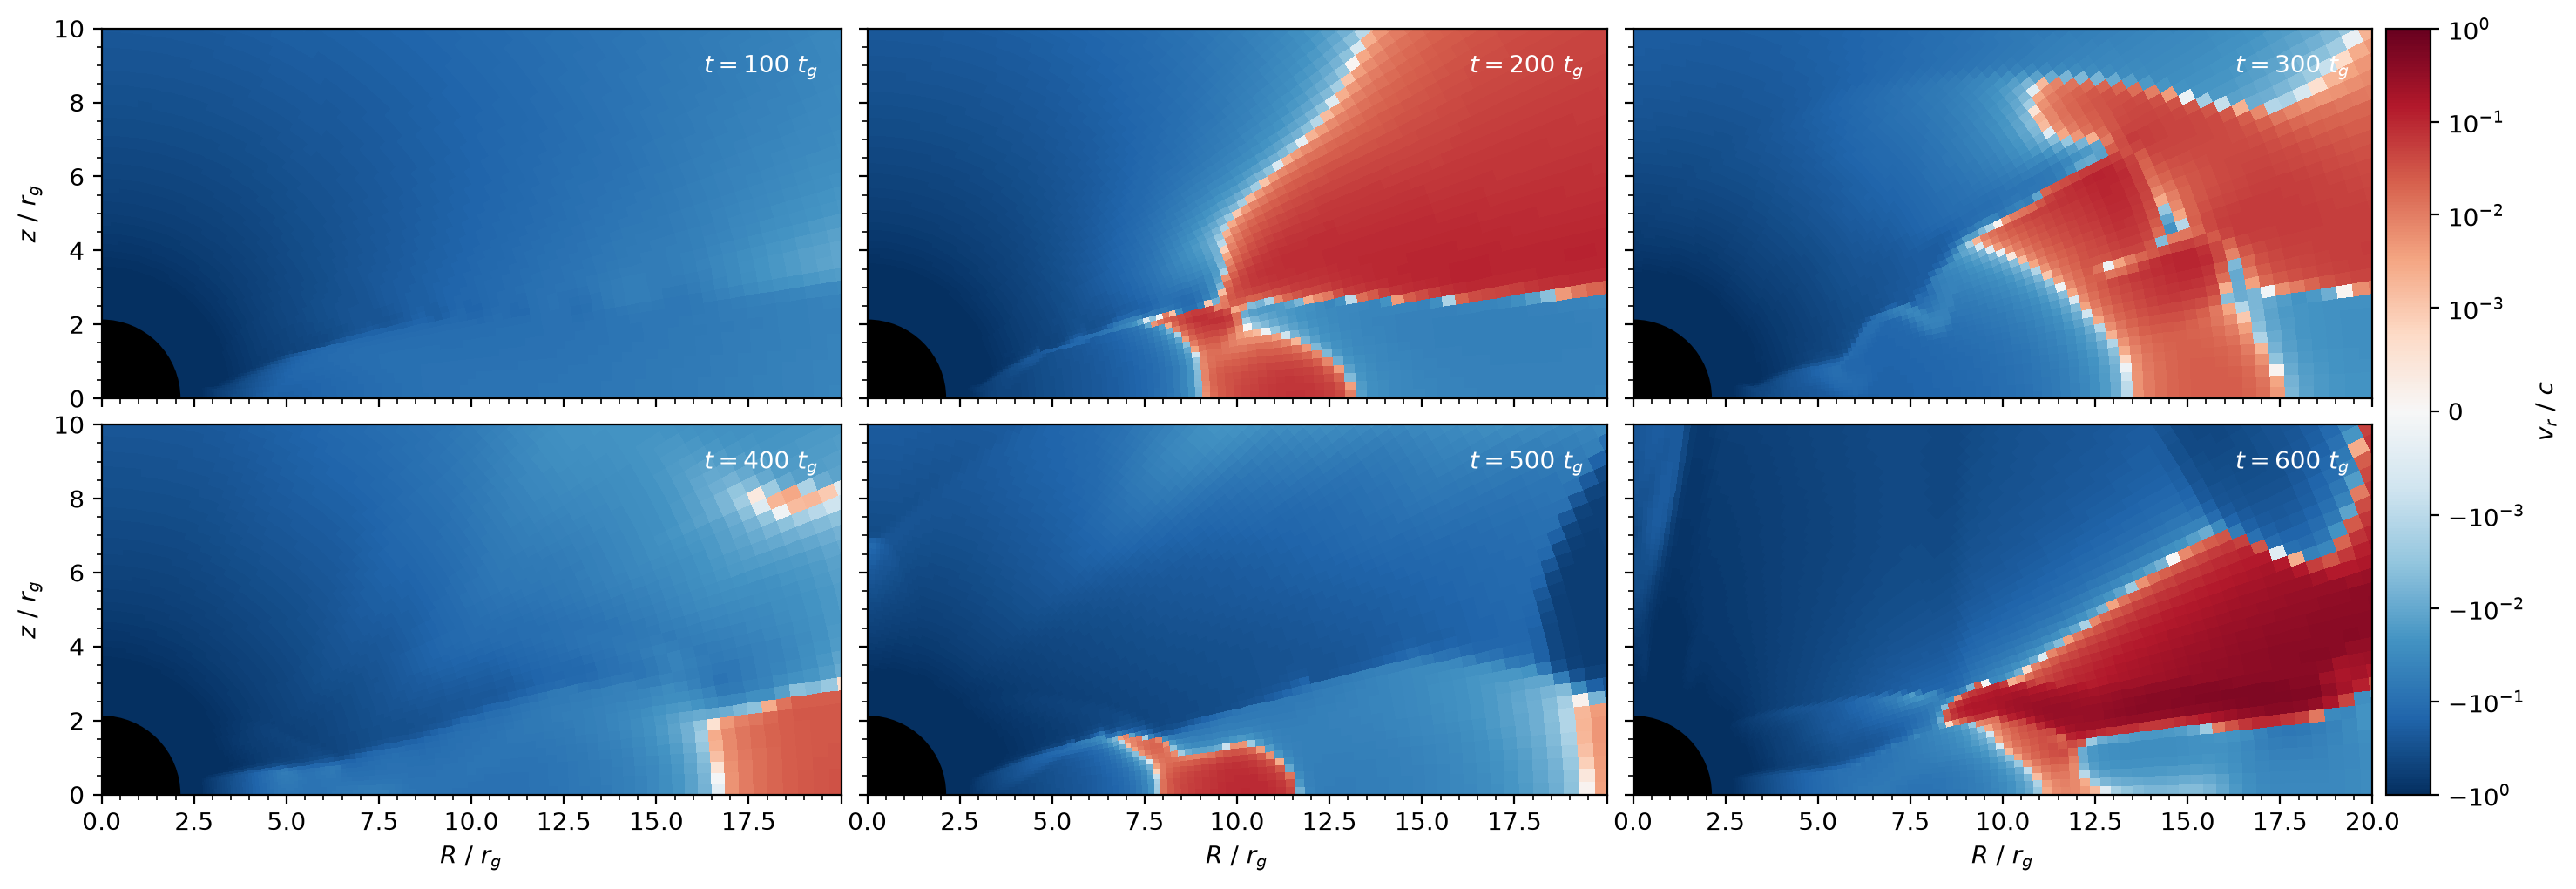

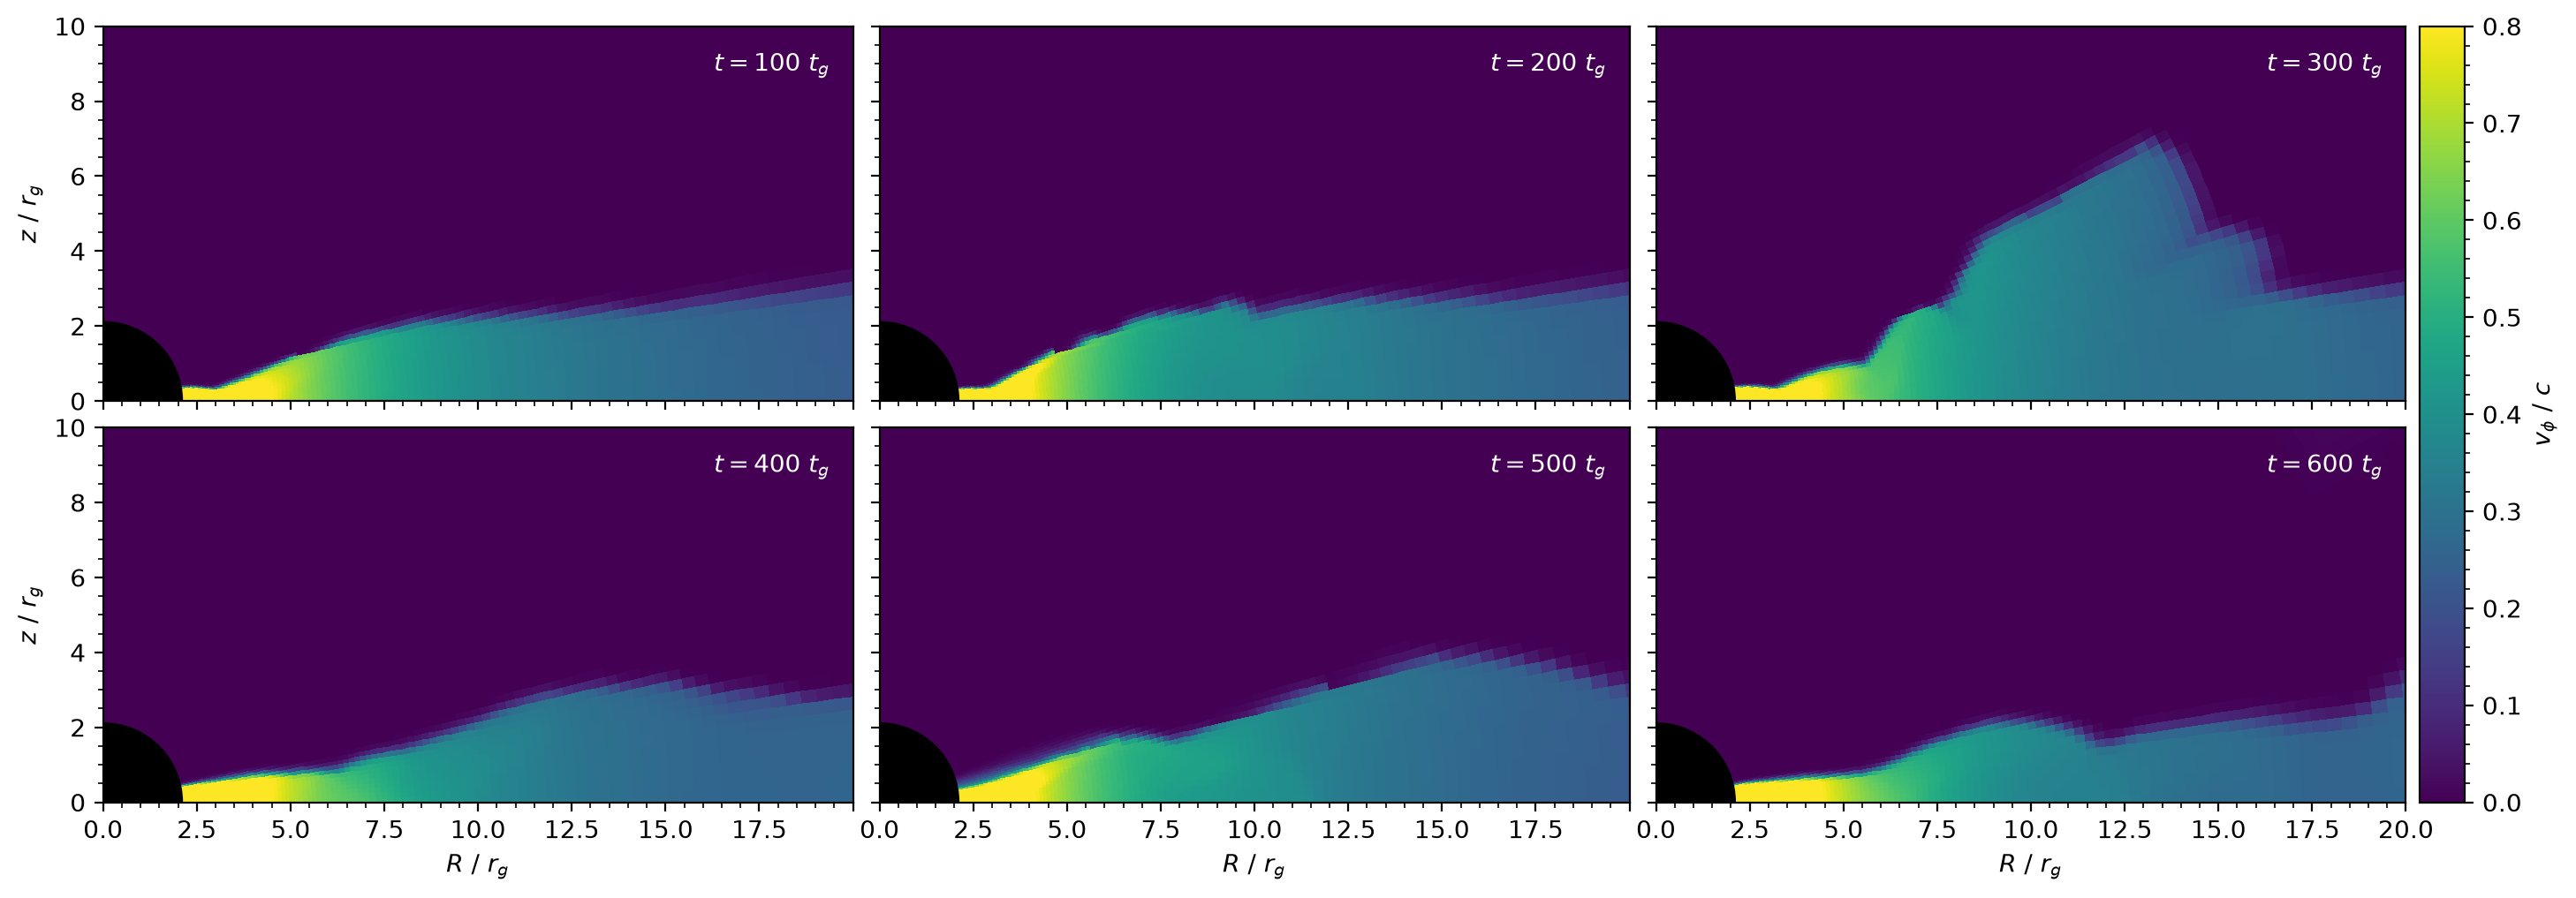

In [11]:
snapshot_rows(T_EARLY)

### 2. Relaxation

#### 2.1. Window

Stationarity is applied in the statistical sense here, since the steady state still contains quasiperiodic density oscillations. The sliding window mean over $N_W = W/\Delta t$ frames centred on $t_c$ is

$$\langle X \rangle_W(t_c) = \frac{1}{N_W}\sum_{|t_k - t_c| \leq W\!/2} X(t_k)$$

with cadence $\Delta t$ for a quantity $X(t)$ being sampled. The reference state $\langle X\rangle_\mathrm{ref}$ is the mean over the last fraction starting at $t_\mathrm{ref}$ of the run. Consecutive frames are correlated, so standard errors come from block averaging, in which an interval is split into $N_b$ blocks of fixed length, about three wave periods and longer than the correlation time, with block means $\bar X_b$ and

$$\mathrm{SE} = \frac{\mathrm{std}\left(\bar X_b\right)}{\sqrt{N_b}}$$

giving the uncertainty. If an interval holds fewer than four blocks, the block length is shortened to a quarter of it. Assuming the same fluctuation statistics in a window of $N_W$ frames as in the reference interval of $N_\mathrm{ref}$ frames, the standard error of the difference is $\sigma = \mathrm{SE}_\mathrm{ref}\sqrt{1 + N_\mathrm{ref}/N_W}$ and

$$D(t_c) = \frac{\left|\langle X\rangle_W(t_c) - \langle X\rangle_\mathrm{ref}\right|}{\sigma}$$


is the normalized distance. Windows that overlap the reference interval share frames with it and agree with it by construction, so only windows with
$t_c + W\!/2 \leq t_\mathrm{ref}$ are judged. The relaxation time is the earliest window centre consistent with the reference

$$t_\mathrm{relax} = \min\left\{ t_c : D(t_c') < Z_\mathrm{crit}\ \ \forall\, t_c' \geq t_c\,\wedge\, t_c' + W\!/2 \leq t_\mathrm{ref} \right\} \qquad Z_\mathrm{crit} = 2$$

after which all window means stay consistent. If even the last judged window is inconsistent $X$ has not demonstrably relaxed before $t_\mathrm{ref}$ and $t_\mathrm{ref}$ is used as a proxy for its actual relaxation time.

window 50 frames,  block 20 frames,  reference t > 32050


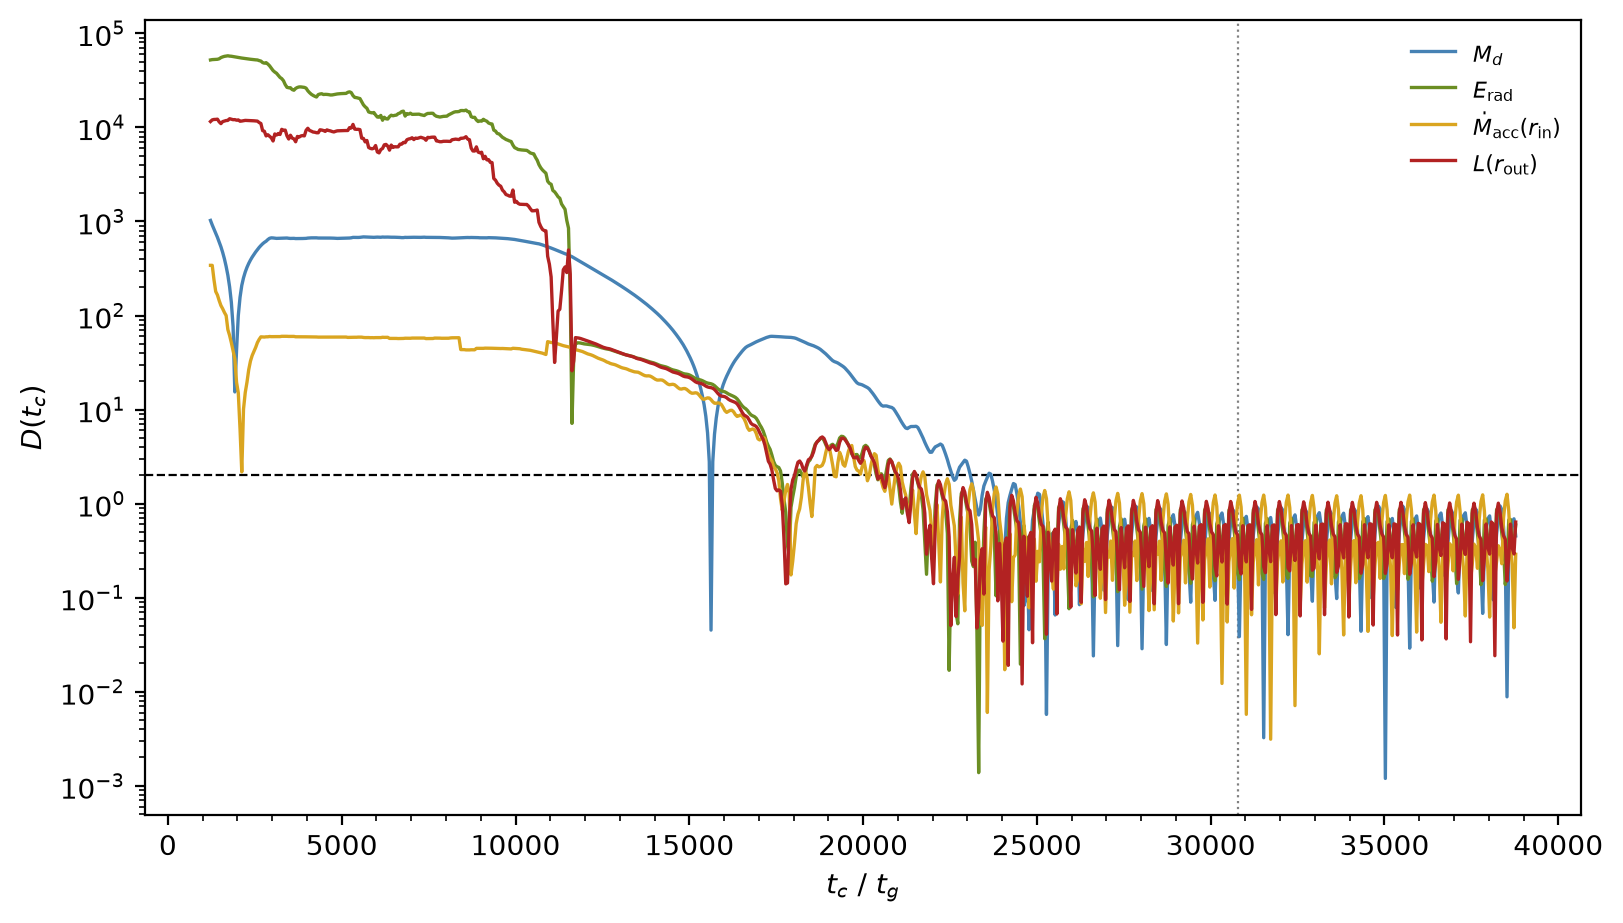

In [12]:
GLOBAL_TEX = {'M_d': r'$M_d$', 'E_rad': r'$E_\mathrm{rad}$', 'Mdot_acc(r_in)': r'$\dot M_\mathrm{acc}(r_\mathrm{in})$',
              'L(r_out)': r'$L(r_\mathrm{out})$'}

def global_series(Cx):
    return {'M_d': Cx['M_d'], 'E_rad': Cx['E_rad'], 'Mdot_acc(r_in)': -Cx['mdot'][:, 0], 'L(r_out)': Cx['L_out']}

scale = MDOT0 / MDOT_EDD

def frames(span, dt):
    return max(int(round(span / dt)), 1)

def mean_se(X, dt):
    X = np.asarray(X, dtype=float)
    n = X.shape[0]
    size = min(frames(BLOCK, dt), max(n // 4, 1))
    nb = n // size

    blocks = X[:nb * size].reshape((nb, size) + X.shape[1:]).mean(axis=1)
    return X.mean(axis=0), blocks.std(axis=0, ddof=1) / np.sqrt(nb)

def window_means(t, X, dt):
    X = np.asarray(X, dtype=float)
    n_w = min(frames(W_WINDOW, dt), X.shape[0])
    cs = np.cumsum(np.concatenate([np.zeros((1,) + X.shape[1:]), X]), axis=0)
    means = (cs[n_w:] - cs[:-n_w]) / n_w
    centres = 0.5 * (t[n_w - 1:] + t[:t.size - n_w + 1])
    return centres, means, n_w

def relaxation(t, X, dt):
    X = np.asarray(X, dtype=float)
    n_ref = max(int(round(REF_FRAC * t.size)), 8)
    tc, m, n_w = window_means(t, X, dt)
    ref, se = mean_se(X[-n_ref:], dt)
    sigma = np.maximum(se * np.sqrt(1.0 + n_ref / n_w), 1e-300)
    D = np.abs(m - ref) / sigma

    t_ref = t[-n_ref]
    judged = tc + 0.5 * W_WINDOW <= t_ref
    if not judged.any():
        return np.full(X.shape[1:], np.nan), tc, D, t_ref

    ok = D[judged] < Z_CRIT
    tail_ok = np.flip(np.logical_and.accumulate(np.flip(ok, axis=0), axis=0), axis=0)
    first = np.argmax(tail_ok, axis=0)
    t_relax = np.where(tail_ok.any(axis=0), tc[judged][first], np.nan)
    return t_relax, tc, D, t_ref

def steady_start(run, override=None):
    times, curves = {}, {}
    for label, X in global_series(run['C']).items():
        tr, tc, D, t_ref = relaxation(run['t'], X, run['dt'])
        times[label] = float(tr)
        curves[label] = (tc, D)

    t_steady = override if override is not None else max(v if np.isfinite(v) else t_ref for v in times.values())
    return t_steady, times, curves, t_ref

for run, override in [(RUN, MAIN_T_STEADY), (REF, REF_T_STEADY)]:
    if run is None:
        continue
    run['t_steady'], run['t_relax'], run['D_curves'], run['t_ref'] = steady_start(run, override)

print(f"window {frames(W_WINDOW, DT_OUT)} frames,  block {frames(BLOCK, DT_OUT)} frames,  reference t > {RUN['t_ref']:.0f}")

fig, ax = plt.subplots(figsize=[8, 4.5])

for k, (label, (tc, D)) in enumerate(RUN['D_curves'].items()):
    ax.plot(tc, D, color=f"C{k}", lw=1.2, label=GLOBAL_TEX[label])

ax.axhline(Z_CRIT, color='k', lw=0.8, ls='--', zorder=-10)
ax.axvline(RUN['t_ref'] - 0.5 * W_WINDOW, color='gray', lw=0.8, ls=':', zorder=-10)
ax.text(RUN['t_ref'] - 0.5 * W_WINDOW, ax.get_ylim()[0], ' overlaps reference', color='gray', fontsize=8, va='bottom')

ax.set_yscale('log')

ax.set_xlabel(r'$t_c\ /\ t_g$')
ax.set_ylabel(r'$D(t_c)$')

ax.legend(fontsize=8, handleheight=1.8, labelspacing=0.2)

plt.show()

#### 2.2. Equilibrium

The same statistic applied to $\log_{10}\Sigma(r)$ and $\dot M_\mathrm{acc}(r)$ at every radius gives $t_\mathrm{relax}(r)$ which
can be compared with the $t_\nu(r)$ viscous time. The inflow equilibrium radius $R_\mathrm{eq}(t_c)$ is the largest radius out to which the window averaged accretion rate is constant. The waves are strongly nonlinear, so single radii scatter and would require a smoothing window like

$$R_\mathrm{eq}(t_c) = \max\left\{ r_k : \left|\frac{\overline{\dot M}_W(r_j)}{\dot M_{W\,\mathrm{in}}} - 1\right| < \mathrm{TOL_{EQ}}\ \ \forall\, j \leq k \right\} \qquad \dot M_{W\,\mathrm{in}} = \left\langle \langle\dot M_\mathrm{acc}\rangle_W(r) \right\rangle_{r_\mathrm{in} < r < r_\mathrm{isco}}$$

where the reference averages the plunging region without the boundary cell. The two cells next to the outer boundary are not judged, since their cell centred flux is biased by the boundary, and $R_\mathrm{eq}$ may be compared with $R_\nu(t)$ where $t_\nu(R_\nu) = t$ and summarized by its median and standard deviation range over the steady window. The steady window used by all following sections starts at the latest of the global relaxation times

In [13]:
def inflow_equilibrium(run):
    t, r, dt = run['t'], run['r'], run['dt']
    tc, wm, _ = window_means(t, -run['C']['mdot'], dt)

    inner = (r > r[0]) & (r < 6.0)
    ref = wm[:, inner].mean(axis=1)
    smooth = uniform_filter1d(wm, 5, axis=1, mode='nearest')
    ok = np.abs(smooth / ref[:, None] - 1.0) < TOL_EQ
    ok[:, r < 6.0] = True
    ok[:, -2:] = True

    flat = np.logical_and.accumulate(ok, axis=1)
    r_eq = np.array([r[np.nonzero(row)[0][-1]] if row.any() else np.nan for row in flat])

    steady = tc - 0.5 * W_WINDOW >= run['t_steady']
    return np.nanpercentile(r_eq[steady], [16, 50, 84]) if steady.any() else np.full(3, np.nan)

for run in RUNS:
    run['R_eq_stats'] = inflow_equilibrium(run)
    run['sel'] = run['t'] >= run['t_steady']
    if run['D'] is not None:
        idx = np.nonzero(run['D']['t'] >= run['t_steady'])[0]
        run['S'], run['dt_s'] = slice_cache(run['D'], idx), run['dt_d']
    else:
        run['S'], run['dt_s'] = slice_cache(run['C'], np.nonzero(run['sel'])[0]), run['dt']
    run['ts'] = run['S']['t']

    lo, med, hi = run['R_eq_stats']
    print(f"{run['label']}:")
    print("   relaxation times:", {k: (round(v) if np.isfinite(v) else 'not before t_ref') for k, v in run['t_relax'].items()})
    print(f"   steady window t in [{run['t_steady']:.0f}, {run['t'][-1]:.0f}],  {run['sel'].sum()} long frames;"
          f"  spectral series {run['ts'].size} frames at cadence {run['dt_s']:g}")
    print(f"   inflow equilibrium radius R_eq = {med:.1f} ({lo:.1f} - {hi:.1f}),  viscous estimate R_nu = {r_viscous(run['t'][-1]):.1f}")

SEL, TS = RUN['sel'], RUN['t'][RUN['sel']]

HR:
   relaxation times: {'M_d': 23725, 'E_rad': 21525, 'Mdot_acc(r_in)': 21775, 'L(r_out)': 21575}
   steady window t in [23725, 40000],  326 long frames;  spectral series 2001 frames at cadence 5
   inflow equilibrium radius R_eq = 17.4 (16.3 - 21.8),  viscous estimate R_nu = 26.1
LR:
   relaxation times: {'M_d': 9225, 'E_rad': 7125, 'Mdot_acc(r_in)': 7325, 'L(r_out)': 7125}
   steady window t in [9225, 50000],  816 long frames;  spectral series 816 frames at cadence 50
   inflow equilibrium radius R_eq = 17.9 (16.4 - 21.4),  viscous estimate R_nu = 30.3


#### 2.3. Settling

The global mass budget is plotted, revealing a turbulent breakup of the higher resolution run compared to lower count grid, which dampens instabilities artificially, before eventually converging. Afterwards, mass and energy as well as luminosity are shown in the steady window.

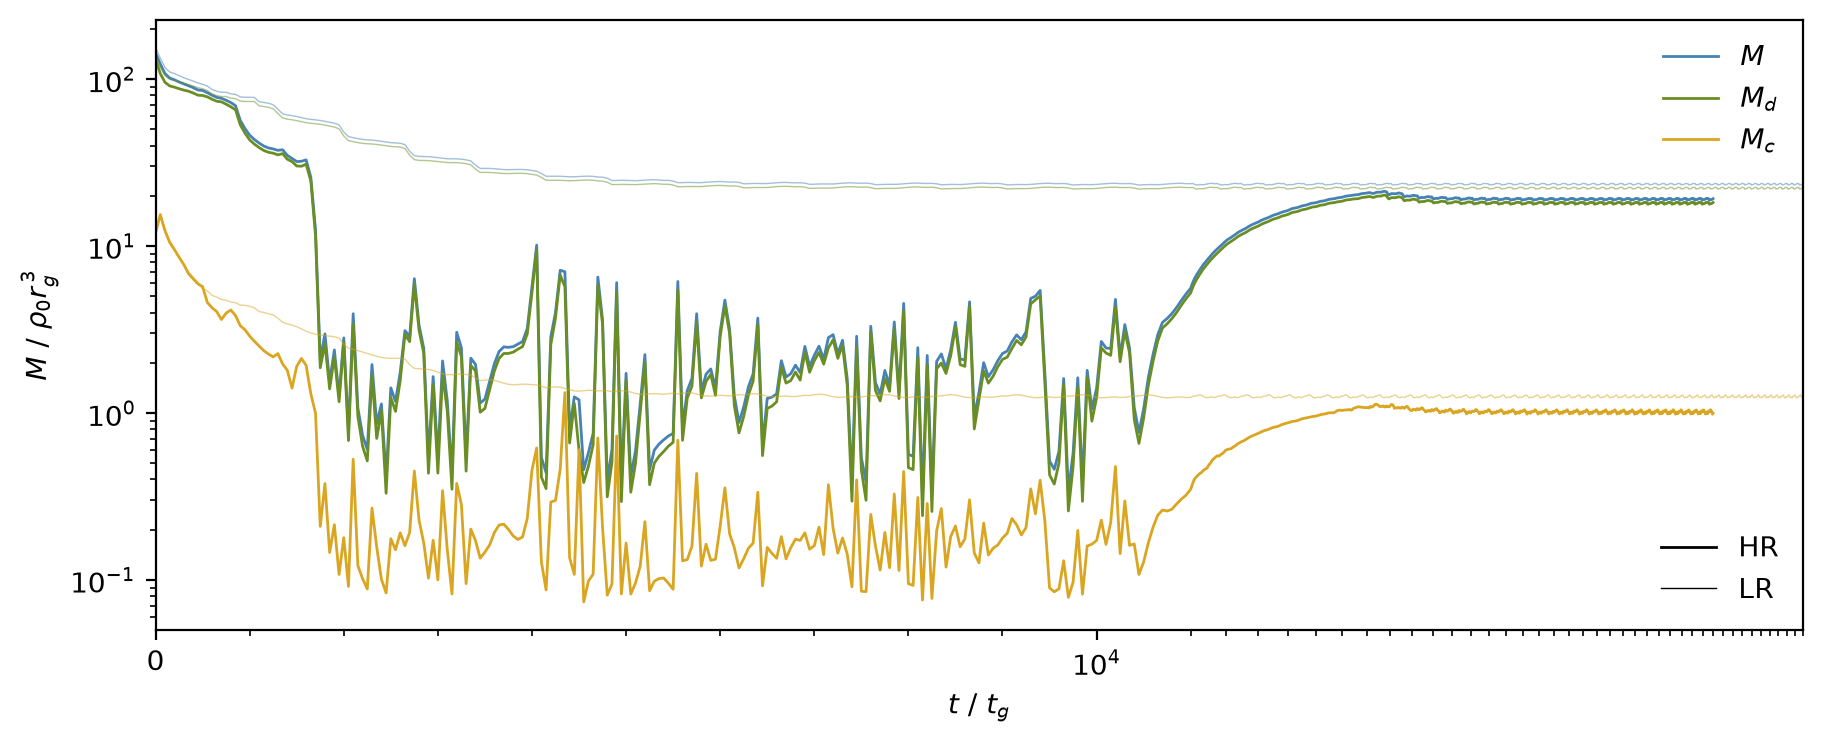

In [14]:
def global_panels(axs, window=False):
    for run in RUNS:
        s = run['sel'] if window else slice(None)
        Cx, t = run['C'], run['t'][s]
        lw, al = (1.0, 1.0) if run is RUN else (0.5, 0.5)
        lab = (lambda x: x if run is RUN else None)

        for k, (key, name) in enumerate([('M', r'$M$'), ('M_d', r'$M_d$'), ('M_c', r'$M_c$')]):
            axs[0].plot(t, Cx[key][s], color=f"C{k}", ls=run['ls'], lw=lw, alpha=al, label=lab(name))

        if len(axs) > 1:
            for k, (key, name) in enumerate([('E_rad', r'$E_\mathrm{rad}$'), ('E_th', r'$E_\mathrm{th}$'), ('E_kin', r'$E_\mathrm{kin}$')]):
                axs[1].plot(t, Cx[key][s], color=f"C{k}", ls=run['ls'], lw=lw, alpha=al, label=lab(name))

            axs[2].plot(t, -Cx['mdot'][s, 0] * scale, color='C0', ls=run['ls'], lw=lw, alpha=al,
                        label=lab(r'$\dot M_\mathrm{acc}(r_\mathrm{in}) / \dot M_\mathrm{E}$'))
            axs[2].plot(t, Cx['L_out'][s] * L0 / L_EDD, color='C1', ls=run['ls'], lw=lw, alpha=al,
                        label=lab(r'$L(r_\mathrm{out}) / L_\mathrm{E}$'))

    axs[0].set_yscale('log')
    axs[0].set_ylabel(r'$M\ /\ \rho_0 r_g^{\,3}$')

    if len(axs) > 1:
        leg_mass = axs[0].legend(ncol=1, bbox_to_anchor=(0.0, 0.78), loc='center left')
        axs[0].add_artist(leg_mass)
        run_legend(axs[0], bbox_to_anchor=(0.0, 0.22), loc='center left')

        axs[1].set_yscale('log')
        axs[1].set_ylabel(r'$E\ /\ \rho_0 c^2 r_g^{\,3}$')
        axs[1].legend(ncol=1, bbox_to_anchor=(0.0, 0.77), loc='center left')

        axs[2].set_ylabel(r'$\lambda_E$')
        h, l = axs[2].get_legend_handles_labels()
        h, l = h[::-1], l[::-1]
        leg_left = axs[2].legend(h[:1], l[:1], loc='upper left')
        axs[2].add_artist(leg_left)
        axs[2].legend(h[1:], l[1:], loc='upper right')

    else:
        leg_mass = axs[0].legend(ncol=1, loc='upper right')
        axs[0].add_artist(leg_mass)
        run_legend(axs[0], loc='lower right')

    axs[-1].set_xlabel(r'$t\ /\ t_g$')

linthresh = 11e3
tmax = max(run['t'][-1] for run in RUNS)

fig, ax = plt.subplots(figsize=[9, 3.6])

global_panels([ax])

ax.set_xscale('symlog', linthresh=linthresh, linscale=1.0)
ax.set_xlim(0, tmax)

major_ticks = [0, 1e4]
minor_ticks = [k * 1e3 for k in range(1, 51) if k != 10]

def fmt(v, _):
    if v == 0:
        return '0'
    e = int(np.floor(np.log10(v)))
    return rf'$10^{{{e}}}$'

ax.xaxis.set_major_locator(FixedLocator(major_ticks))
ax.xaxis.set_major_formatter(FuncFormatter(fmt))
ax.xaxis.set_minor_locator(FixedLocator(minor_ticks))
ax.xaxis.set_minor_formatter(NullFormatter())

plt.show()

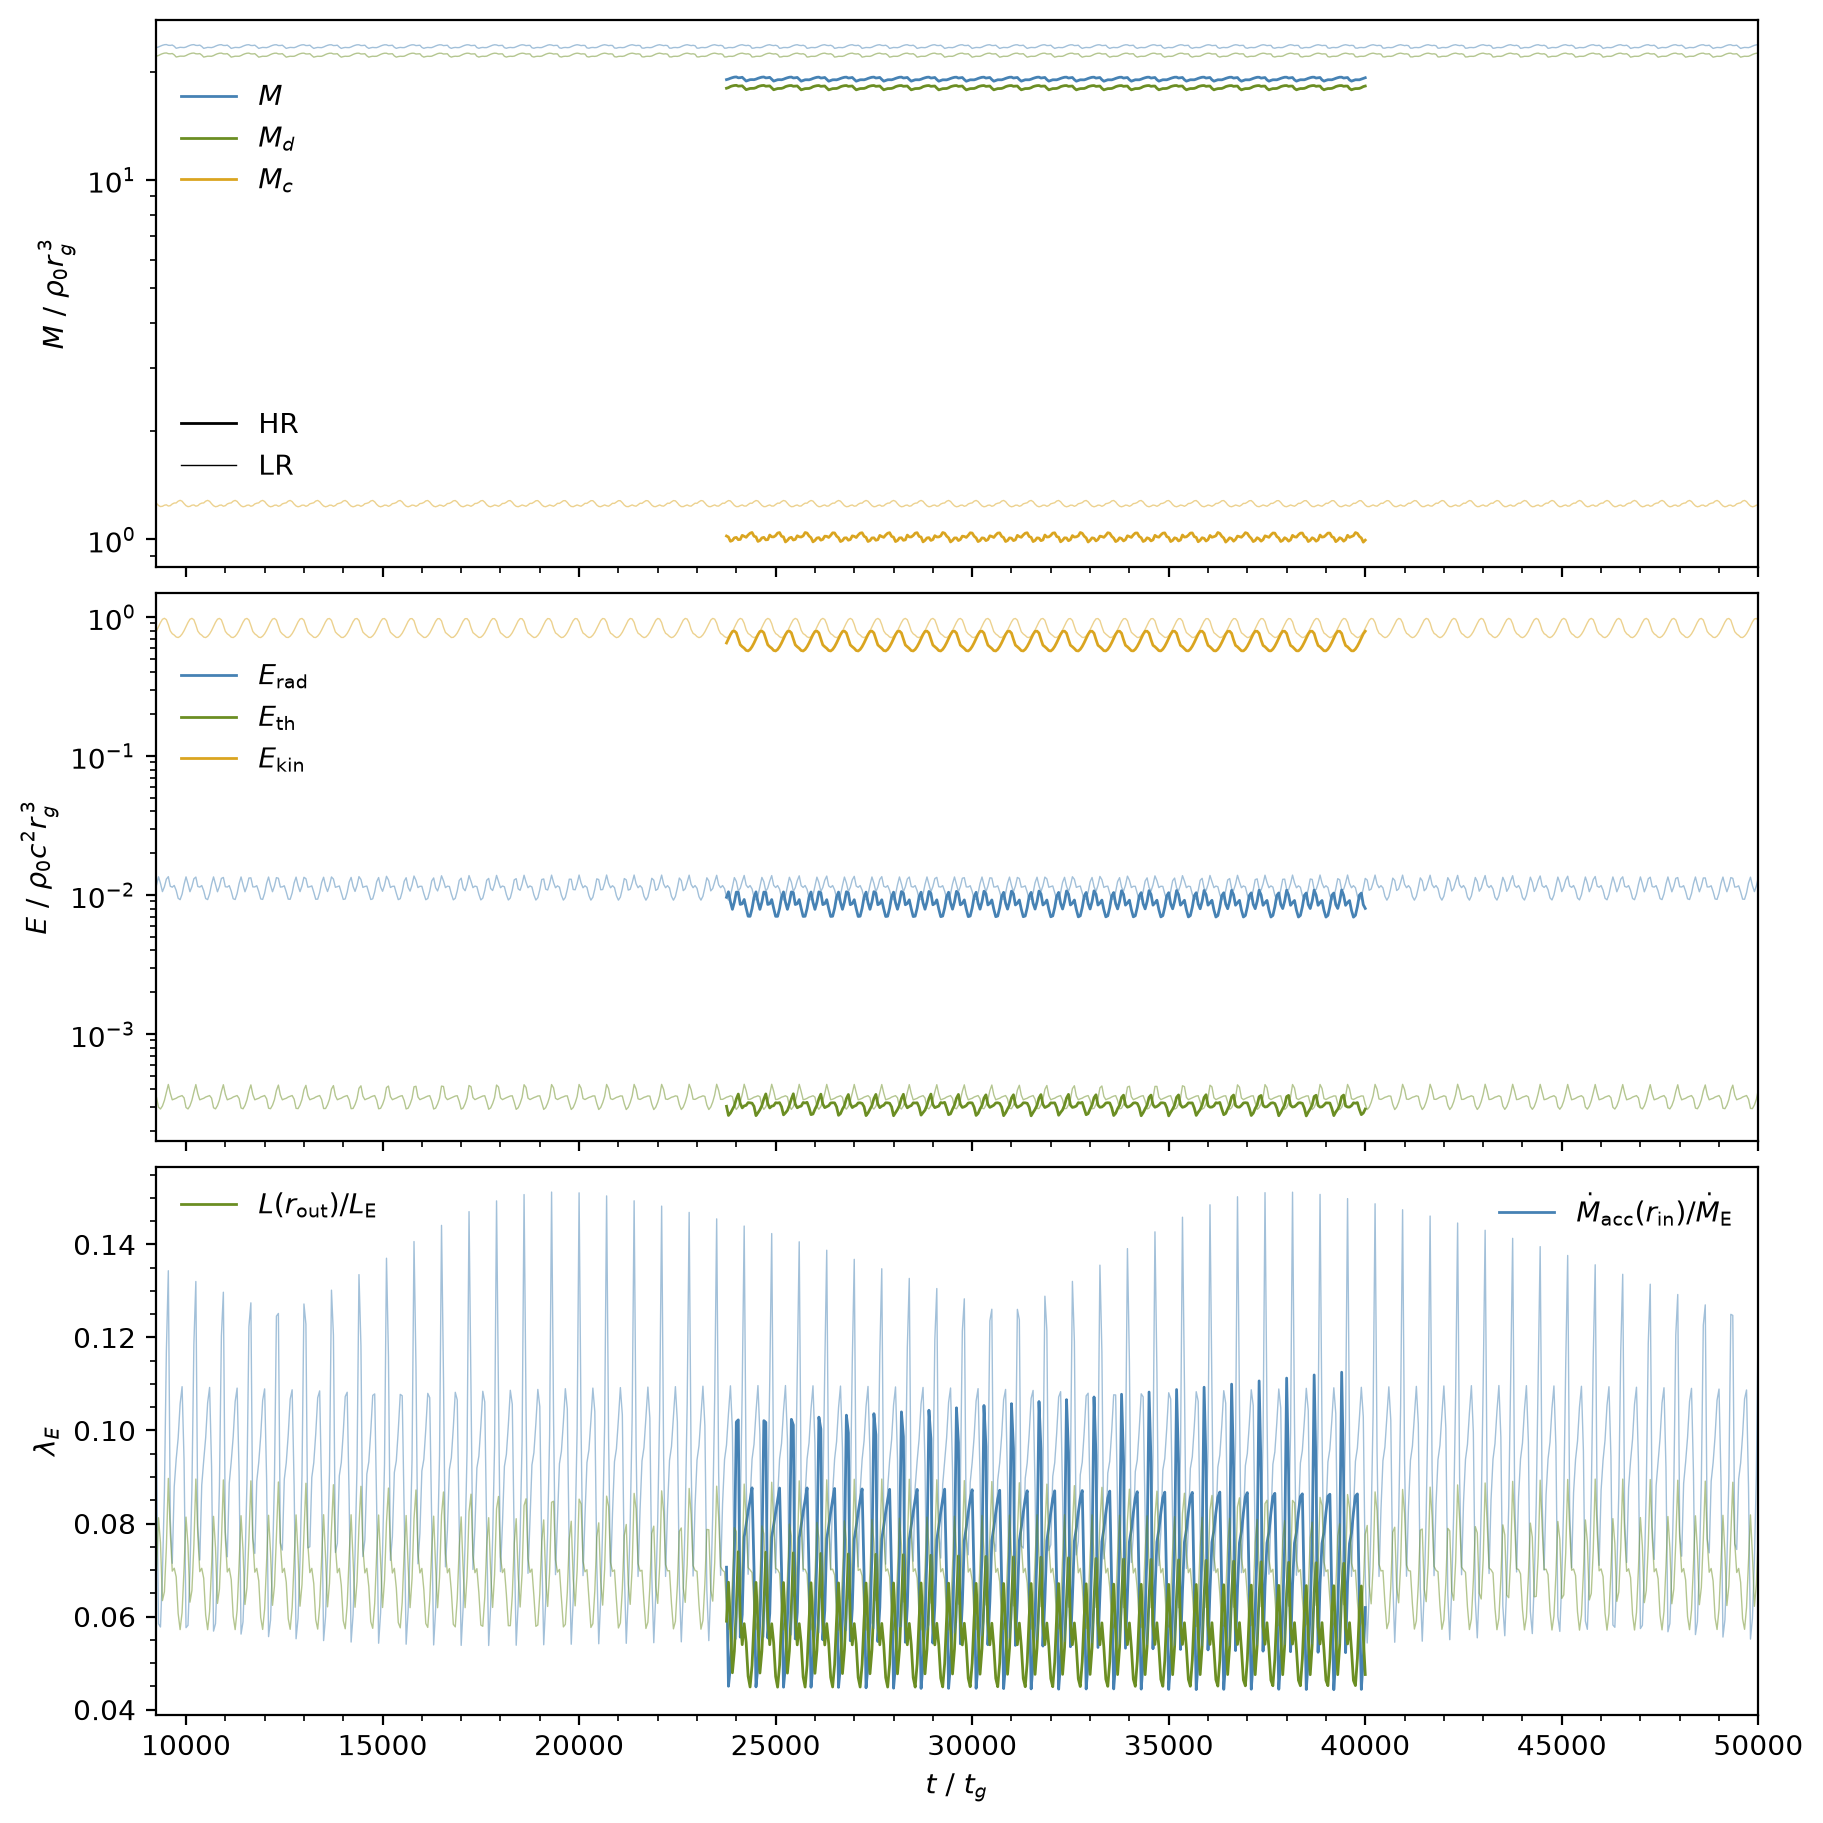

In [15]:
fig, axs = plt.subplots(3, 1, figsize=[9, 9], sharex=True)

global_panels(axs, window=True)

axs[-1].set_xlim(min(run['t_steady'] for run in RUNS), max(run['t'][-1] for run in RUNS))

plt.show()

#### 2.4. Drift

A steady window should show no trend beyond the fluctuations. The block means $\bar X_b$ at block centres $t_b$ normalized by the
window mean are fitted with a straight line

$$\frac{\bar X_b}{\langle X\rangle} = a + b\,\frac{t_b - \bar t}{10^4\,t_g}$$

and the slope $b$ gives the change per $10^4\,t_g$ and is tested against zero with heteroskedasticity and autocorrelation consistent Newey-West standard errors, which accounts for correlated neighbouring blocks. Then $|b|/\sigma_b > 2$ flags a significant drift. This replaces stationarity tests such as KPSS or ADF which are dominated by the periodic waves and only compare against a single alternative.

In [16]:
def drift(t, X, dt):
    size = frames(BLOCK, dt)
    nb = X.size // size
    if nb < 4:
        return np.nan, np.nan

    xb = X[:nb * size].reshape(nb, size).mean(axis=1)
    tb = t[:nb * size].reshape(nb, size).mean(axis=1)

    fit = sm.OLS(xb / xb.mean(), sm.add_constant((tb - tb.mean()) / 1e4)).fit(cov_type='HAC', cov_kwds={'maxlags': 1})
    return fit.params[1], fit.bse[1]

print(f"{'':28s}" + ''.join(f"{run['label']:>30s}" for run in RUNS) + "\n")
for label in global_series(C):
    line = f"{label:28s}"
    for run in RUNS:
        X = global_series(run['C'])[label][run['sel']]
        b, eb = drift(run['t'][run['sel']], X, run['dt'])
        line += f"{b * 100:+10.2f} +- {eb * 100:5.2f} %  (z = {b / eb:+5.1f})" if np.isfinite(b) else f"{'too short':>30s}"
    print(line)

print("\nrelative change per 1e4 t_g over each steady window")

                                                        HR                            LR

M_d                              -0.05 +-  0.05 %  (z =  -1.1)     -0.01 +-  0.01 %  (z =  -1.2)
E_rad                            -0.56 +-  0.50 %  (z =  -1.1)     -0.09 +-  0.10 %  (z =  -0.9)
Mdot_acc(r_in)                   +0.52 +-  0.63 %  (z =  +0.8)     -0.02 +-  0.22 %  (z =  -0.1)
L(r_out)                         -0.38 +-  0.41 %  (z =  -0.9)     -0.08 +-  0.10 %  (z =  -0.8)

relative change per 1e4 t_g over each steady window


### 3. Accretion

#### 3.1. Spacetime

The mass flux $\dot M_\mathrm{acc}(r, t) = -\dot M(r,t)$ in units of $\dot M_\mathrm{E}$ is set positive for inflow. The disk and corona are separated by the classifier weights.

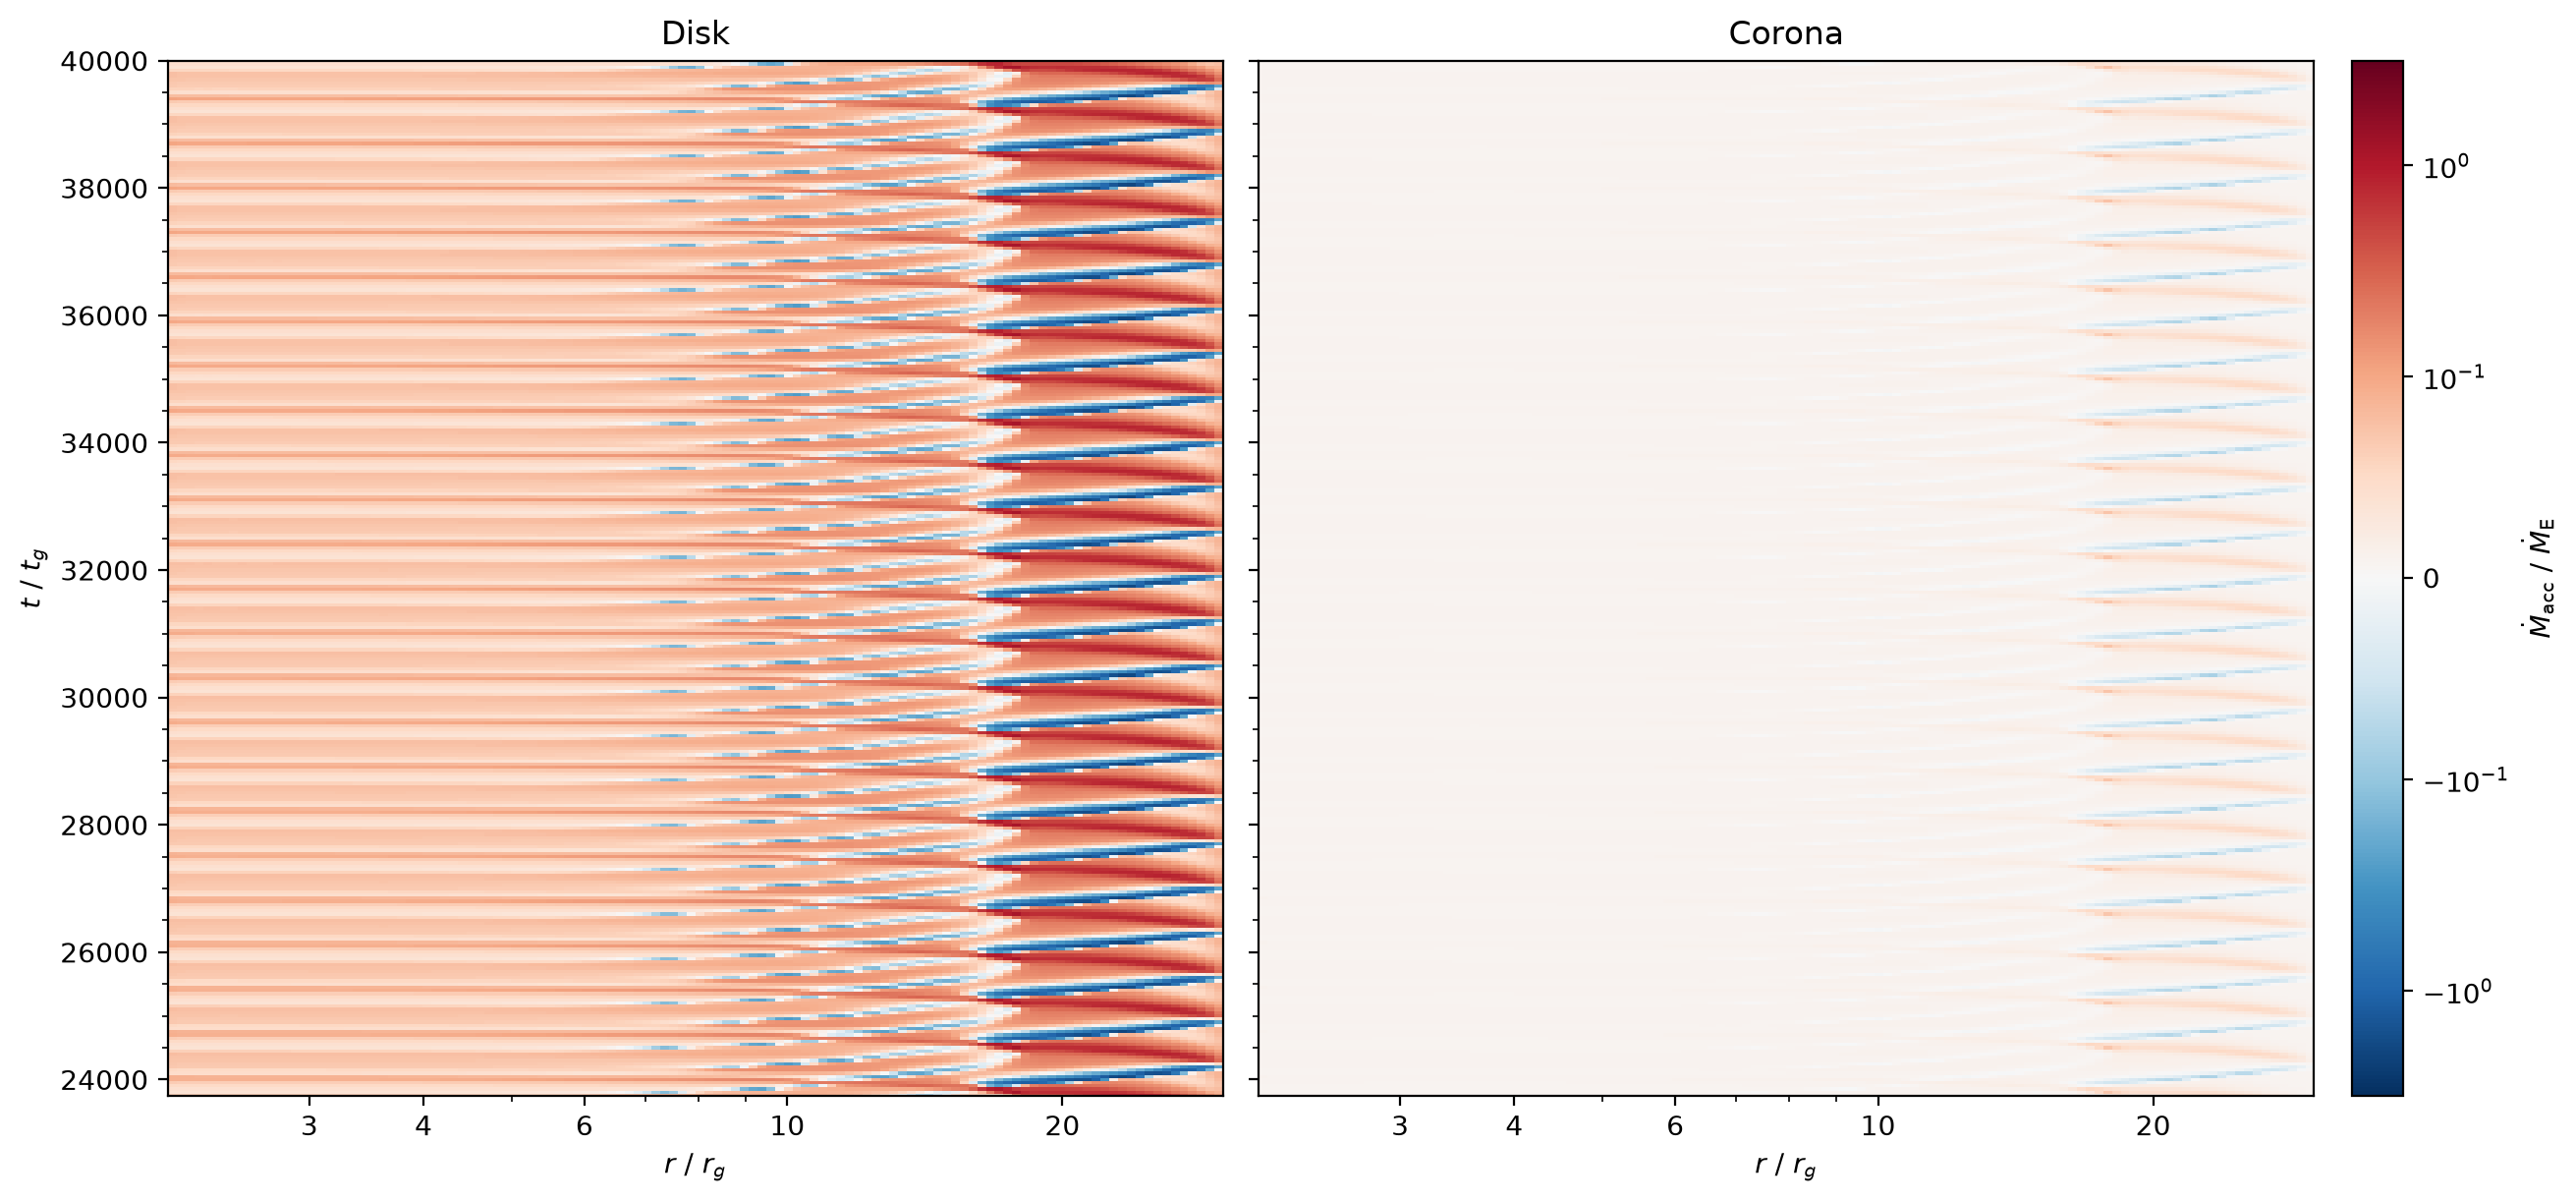

In [17]:
def spacetime(ax, t, data, norm, cmap, tlim=None, r=R_C):
    im = ax.pcolormesh(r, t, data, norm=norm, cmap=cmap, shading='nearest', rasterized=True)

    ax.set_xscale('log')
    ax.set_xlabel(r'$r\ /\ r_g$')
    ax.set_ylabel(r'$t\ /\ t_g$')
    if tlim is not None:
        ax.set_ylim(*tlim)
    plain_log(ax, 'x')
    return im

tlim = (TS[0], TS[-1])

mdot_acc = -C['mdot']
lin = np.nanpercentile(np.abs(mdot_acc[SEL]) * scale, 50)
vmax = np.nanpercentile(np.abs(mdot_acc) * scale, 99.5)
norm = SymLogNorm(linthresh=max(lin, 11e-2), vmin=-vmax, vmax=vmax)

fig, axs = plt.subplots(1, 2, figsize=[13, 6], sharex=True, sharey=True)

spacetime(axs[0], T, -C['mdot_d'] * scale, norm, 'RdBu_r', tlim=tlim)
im = spacetime(axs[1], T, -C['mdot_c'] * scale, norm, 'RdBu_r', tlim=tlim)

axs[1].set_ylabel('')
axs[0].set_title('Disk')
axs[1].set_title('Corona')

fig.colorbar(im, ax=axs, label=r'$\dot M_\mathrm{acc}\ /\ \dot M_\mathrm{E}$', pad=0.0175)

plt.show()

#### 3.2. Profiles

Over the steady window, the time averaged accretion rate with its block standard error should be independent of radius inside
$R_\mathrm{eq}$ giving a steady $\alpha$ disk with zero torque at $R_\mathrm{isco}$ a surface density

$$\Sigma_\mathrm{ss}(R) = \frac{\langle\dot M_\mathrm{acc}\rangle}{3\pi\,\nu(R)}\left(1 - \sqrt{\frac{R_\mathrm{isco}}{R}}\right) \qquad R > R_\mathrm{isco}$$

evaluated with the measured mean accretion rate at the inner boundary and the kinematic viscosity $\nu(R)$ of the model. A check compares the mean flux in the cells next to the boundaries with the median over the interior. The flux is evaluated at cell centres $\rho v_r$ of the cell and not as the conservative interface flux of the solver, and next to a boundary the two can differ because the ghost cells impose their own state. Deviations there are an expected property of the diagnostic, not mass sources.

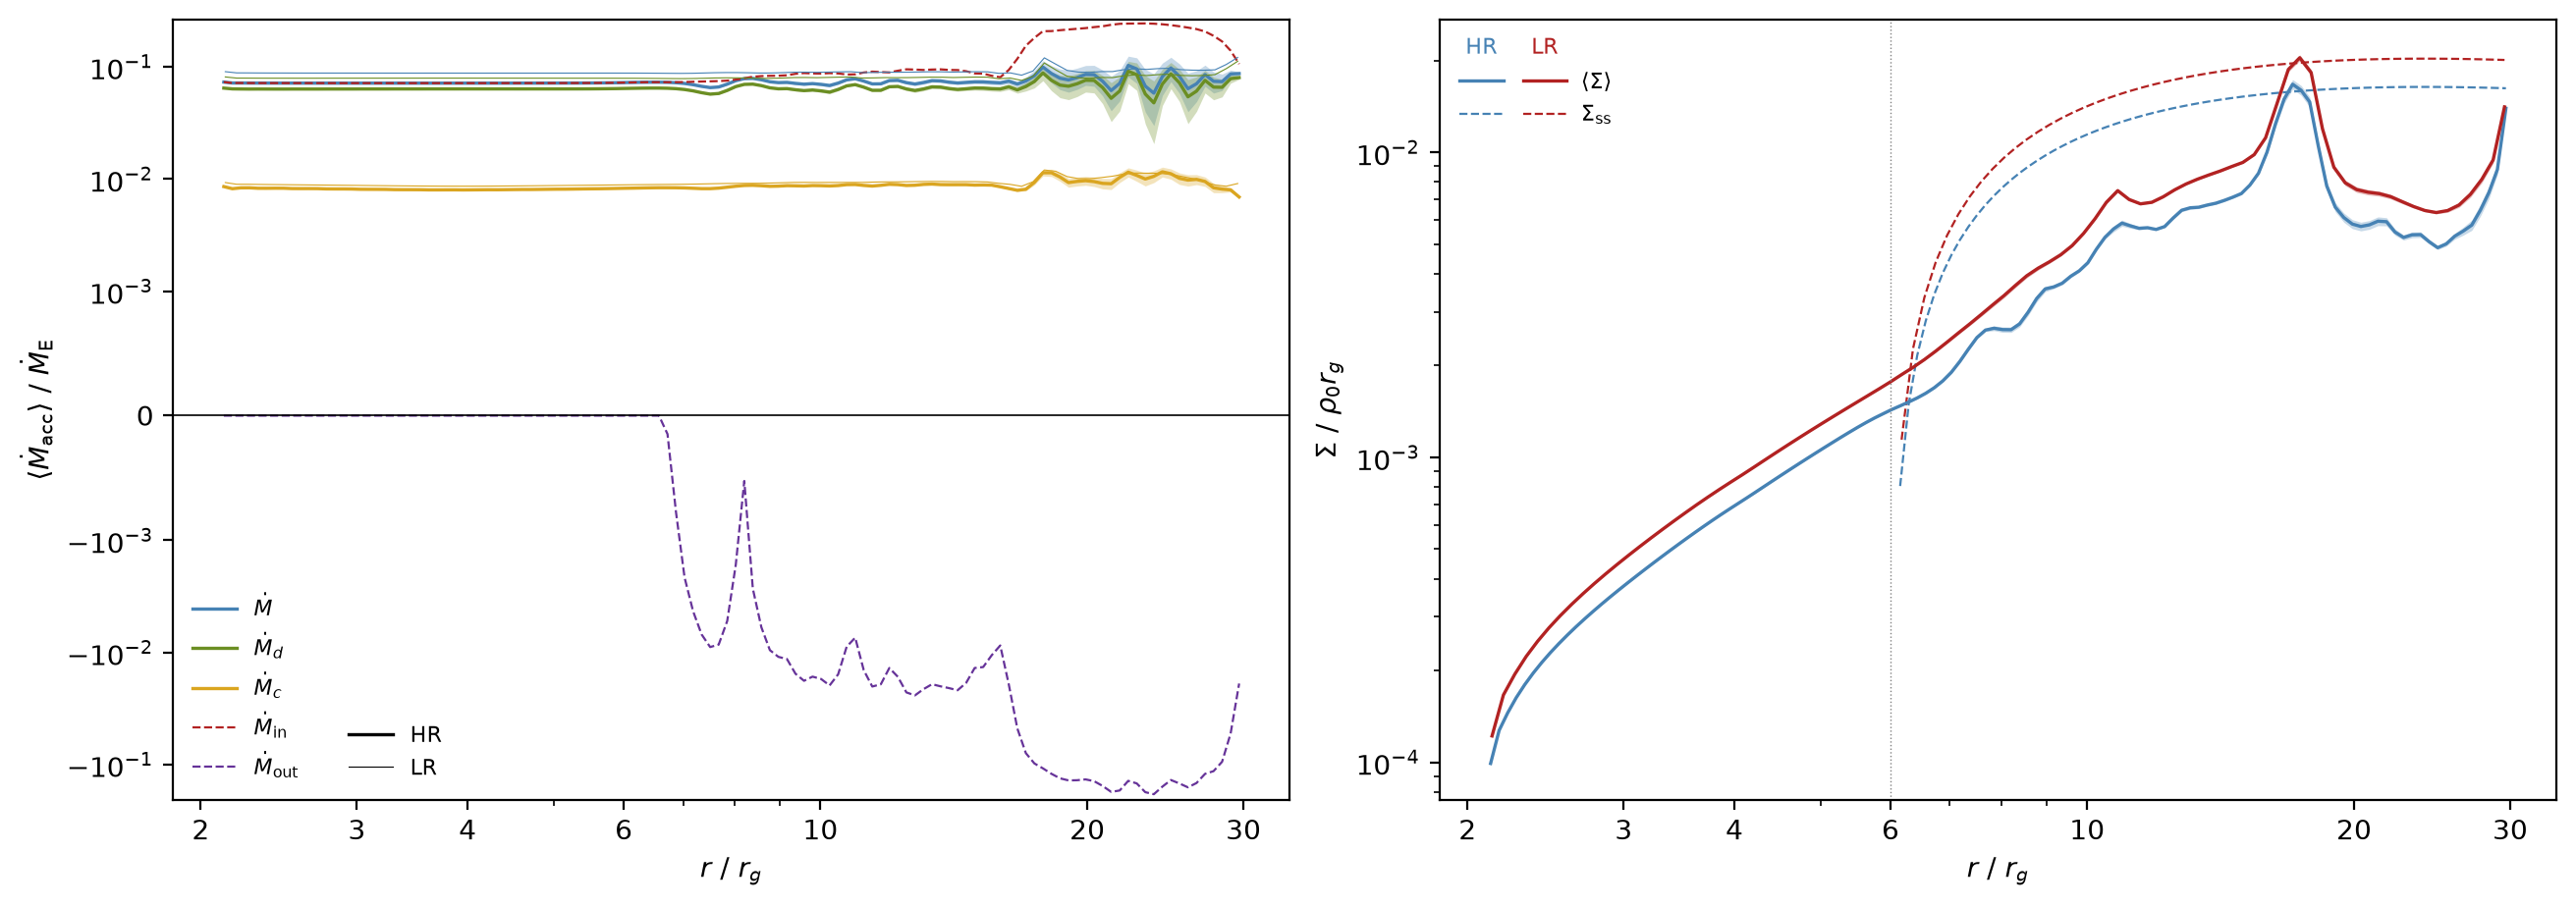

HR:  <Mdot_acc(r_in)> = 0.0731 +- 0.0004 Mdot_Edd = 0.304 Msun/yr
   boundary cells relative to the interior median: r = 2.12: +1.9%, r = 2.17: -0.0%, r = 29.02: +20.4%, r = 29.67: +21.3%
LR:  <Mdot_acc(r_in)> = 0.0905 +- 0.0003 Mdot_Edd = 0.376 Msun/yr
   boundary cells relative to the interior median: r = 2.13: +2.4%, r = 2.20: -0.1%, r = 28.70: +18.8%, r = 29.56: +37.1%


In [18]:
for run in RUNS:
    Cx, s, dt = run['C'], run['sel'], run['dt']
    run['mdot_in_mean'], run['mdot_in_se'] = mean_se(-Cx['mdot'][s, 0], dt)
    run['mdot_prof'] = mean_se(-Cx['mdot'][s], dt)[0]
    run['sig_mean'], run['sig_se'] = mean_se(Cx['sigma'][s], dt)

MDOT_PARTS = [('mdot', r'$\dot M$'), ('mdot_d', r'$\dot M_d$'), ('mdot_c', r'$\dot M_c$')]
MDOT_FLOWS = [('mdot_in', r'$\dot M_\mathrm{in}$'), ('mdot_out', r'$\dot M_\mathrm{out}$')]

fig, axs = plt.subplots(1, 2, figsize=[13, 4.5])

ax = axs[0]
for run in RUNS:
    Cx, s, dt, r = run['C'], run['sel'], run['dt'], run['r']

    for k, (key, lab) in enumerate(MDOT_PARTS):
        m, e = mean_se(-Cx[key][s] * scale, dt)
        ax.plot(r, m, color=f"C{k}", ls=run['ls'], lw=1.2 if run is RUN else 0.4, label=lab if run is RUN else None)
        if run is RUN:
            ax.fill_between(r, m - e, m + e, color=f"C{k}", alpha=0.3, lw=0)

    if run is RUN:
        for k, (key, lab) in enumerate(MDOT_FLOWS):
            ax.plot(r, mean_se(-Cx[key][s] * scale, dt)[0], color=f"C{k + 3}", ls='--', lw=0.8, label=lab)

ax.axhline(0, color='k', lw=0.6)

ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=1e-3)
plain_log(ax, 'x')

ax.set_xlabel(r'$r\ /\ r_g$')
ax.set_ylabel(r'$\langle\dot M_\mathrm{acc}\rangle\ /\ \dot M_\mathrm{E}$')

ax.add_artist(ax.legend(fontsize=8, ncol=1, loc='lower left'))
run_legend(ax, lws=(1.2, 0.4), fontsize=8, bbox_to_anchor=(0.14, 0.0), loc='lower left')

ax = axs[1]
for run in RUNS:
    r = run['r']
    ax.plot(r, run['sig_mean'], color=run['color'], ls=run['ls'], lw=1.2)
    ax.fill_between(r, run['sig_mean'] - run['sig_se'], run['sig_mean'] + run['sig_se'], color=run['color'], alpha=0.3, lw=0)

    R_ss = r[r > 6.06]
    if run['mdot_in_mean'] > 0:
        ax.plot(R_ss, run['mdot_in_mean'] / (3.0 * np.pi * nu_kin(R_ss)) * (1.0 - np.sqrt(6.0 / R_ss)), color=run['color'], ls='--',
                lw=0.8, zorder=-10)

ax.axvline(6.0, color='gray', lw=0.5, ls=':')

ax.set_xscale('log')
ax.set_yscale('log')
plain_log(ax, 'x')

ax.set_xlabel(r'$r\ /\ r_g$')
ax.set_ylabel(r'$\Sigma\ /\ \rho_0 r_g$')

run_table(ax, [(r'$\;\langle\Sigma\rangle$', dict(lw=1.2)), (r'$\;\Sigma_\mathrm{ss}$', dict(ls='--', lw=0.8))],
          side='right', handlelength=2.0, fontsize=8, columnspacing=0.5)
plt.show()

for run in RUNS:
    m, r = run['mdot_prof'], run['r']
    interior = np.median(m[(r > 3.0) & (r < 25.0)])
    cells = ', '.join(f"r = {r[i]:.2f}: {m[i] / interior - 1:+.1%}" for i in [0, 1, -2, -1])

    print(f"{run['label']}:  <Mdot_acc(r_in)> = {run['mdot_in_mean'] * scale:.4f} +- {run['mdot_in_se'] * scale:.4f} Mdot_Edd"
          f" = {run['mdot_in_mean'] * MDOT0 * YEAR / CONST_Msun:.3f} Msun/yr")
    print(f"   boundary cells relative to the interior median: {cells}")

#### 3.3. Effective

In a steady disk the mean accretion rate and surface density fix the effective kinematic viscosity, whatever transports the angular
momentum, through the same relation as $\Sigma_\mathrm{ss}$ surface density. Written as an effective $\alpha$ with the viscosity law of the model

$$\nu_\mathrm{eff}(R) = \frac{\langle\dot M_\mathrm{acc}\rangle}{3\pi\,\langle\Sigma\rangle}\left(1 - \sqrt{\frac{R_\mathrm{isco}}{R}}\right) \qquad \alpha_\mathrm{eff}(R) = \frac{\nu_\mathrm{eff}(R)}{\tfrac{2}{3}\,\epsilon^2 R^{1/2}}$$

so $\alpha_\mathrm{eff}/\alpha = 1$ means that the explicit viscosity carries the accretion, and $\alpha_\mathrm{eff}/\alpha > 1$ that
an additional transport acts, which could be waves, Reynolds stresses of the mean flow, or numerical viscosity. The latter decreases
with resolution, so a ratio that is the same in both runs points to a physical transport. The mass weighted inflow speed
$\bar v_r = \langle\dot M_\mathrm{acc}\rangle / (2\pi R\langle\Sigma\rangle)$ is compared with the steady $\alpha$ disk value
$\tfrac{3\nu}{2R}(1 - \sqrt{R_\mathrm{isco}/R})^{-1}$ and the uncertainty combines the standard errors of
$\langle\dot M_\mathrm{acc}\rangle$ and $\langle\Sigma\rangle$ meaningfully only inside the $R_\mathrm{eq}$ boundary.

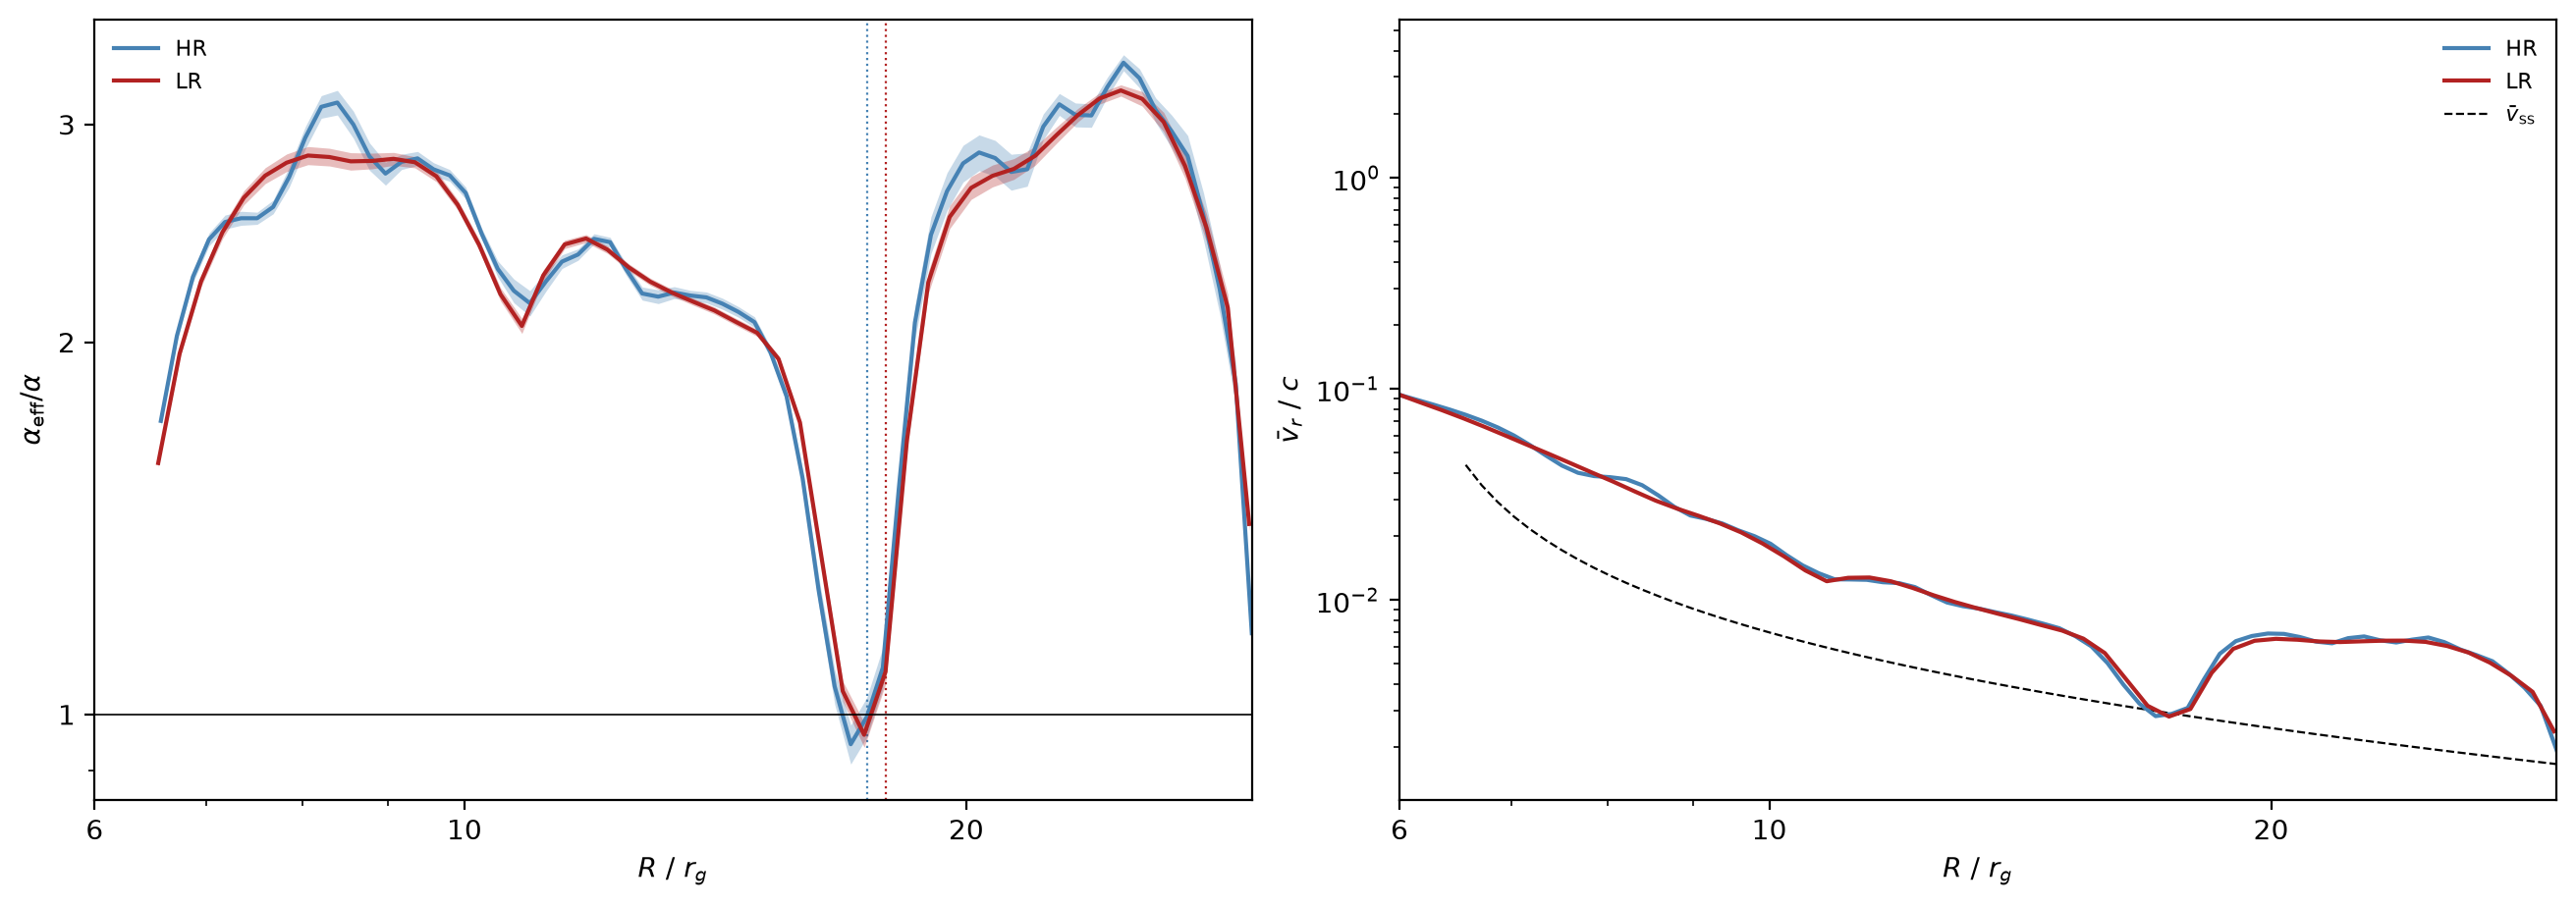

R = 10.0:  HR: alpha_eff / alpha = 2.65 +- 0.03,   LR: alpha_eff / alpha = 2.53 +- 0.02
R = 15.0:  HR: alpha_eff / alpha = 2.05 +- 0.02,   LR: alpha_eff / alpha = 2.03 +- 0.01
R = 20.0:  HR: alpha_eff / alpha = 2.80 +- 0.10,   LR: alpha_eff / alpha = 2.63 +- 0.06


In [19]:
def effective_alpha(run):
    r = run['r']
    w = 1.0 - np.sqrt(6.0 / np.maximum(r, 6.0))
    nu_eff = run['mdot_in_mean'] * w / (3.0 * np.pi * run['sig_mean'])
    a_eff = nu_eff / (2.0 / 3.0 * EPS**2 * np.sqrt(r))

    rel = np.sqrt((run['mdot_in_se'] / run['mdot_in_mean'])**2 + (run['sig_se'] / run['sig_mean'])**2)
    v_mass = run['mdot_in_mean'] / (2.0 * np.pi * r * run['sig_mean'])

    return np.where(r > 6.5, a_eff / ALPHA, np.nan), rel, v_mass

fig, axs = plt.subplots(1, 2, figsize=[13, 4.5])

for run in RUNS:
    r = run['r']
    ratio, rel, v_mass = effective_alpha(run)
    run['alpha_ratio'], run['alpha_ratio_rel'] = ratio, rel

    axs[0].plot(r, ratio, color=run['color'], ls=run['ls'])
    axs[0].fill_between(r, ratio * (1 - rel), ratio * (1 + rel), color=run['color'], alpha=0.3, lw=0)
    axs[0].axvline(run['R_eq_stats'][1], color=run['color'], ls=':', lw=0.8, zorder=-10)

    axs[1].plot(r, v_mass, color=run['color'], ls=run['ls'])

R_ss = R_C[R_C > 6.5]
axs[1].plot(R_ss, 1.5 * nu_kin(R_ss) / R_ss / (1.0 - np.sqrt(6.0 / R_ss)), 'k--', lw=0.8, zorder=-10)
axs[0].axhline(1.0, color='k', lw=0.6)

for ax in axs:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(6, R_C[-1])
    ax.set_xlabel(r'$R\ /\ r_g$')
    plain_log(ax, 'x')
plain_log(axs[0], 'y')

axs[0].set_ylabel(r'$\alpha_\mathrm{eff} / \alpha$')
axs[1].set_ylabel(r'$\bar v_r\ /\ c$')

run_legend(axs[0], color=True, fontsize=8)
run_legend(axs[1], color=True, extra=[(r'$\bar v_\mathrm{ss}$', dict(ls='--', lw=0.8))], fontsize=8)

plt.show()

for R0 in [10.0, 15.0, 20.0]:
    print(f"R = {R0:4.1f}:  " + ',   '.join(
        f"{run['label']}: alpha_eff / alpha = {np.interp(R0, run['r'], run['alpha_ratio']):.2f}"
        f" +- {np.interp(R0, run['r'], run['alpha_ratio'] * run['alpha_ratio_rel']):.2f}" for run in RUNS))

#### 3.4. Variability

The power spectral density of the accretion rate through the inner boundary estimated with the Welch method and a Hann window at $50\%$ overlap, where linear trends get removed per segment, is

$$P(\nu_f) = \frac{2\,\Delta t}{N_\mathrm{seg}\, U}\sum_{s}\left|\sum_{k} w_k\, x_{sk}\, e^{-2\pi i \nu_f t_k}\right|^2 \qquad U = \sum_k w_k^2$$

with frequencies in $t_g^{-1}$ and converted to inverse days. The segment length is chosen so that there are a minimum number of segments at a maximum length. The Nyquist frequency is $\nu_\mathrm{Ny} = 1/(2\Delta t)$ and the peak frequency is refined by a parabola through the logarithm of the three highest bins.

In [20]:
def welch_len(n, dt):
    nper = max(min(int(2 * n / (WELCH_SEG + 1)), frames(WELCH_TSEG, dt)), 8)
    nper = min(nper, n)
    return nper, (n - nper) // (nper // 2) + 1, max(n // nper, 1)

def welch_kw(n, dt):
    nper = welch_len(n, dt)[0]
    return dict(fs=1.0 / dt, window='hann', nperseg=nper, noverlap=nper // 2, detrend='linear', axis=0)

def welch(x, dt):
    return signal.welch(x, **welch_kw(x.shape[0], dt))

def peak_frequency(f, P):
    k = int(np.argmax(P[1:])) + 1

    if 1 < k < f.size - 1 and np.all(P[k - 1:k + 2] > 0):
        y = np.log(P[k - 1:k + 2])
        den = y[0] - 2.0 * y[1] + y[2]
        shift = 0.5 * (y[0] - y[2]) / den if den != 0 else 0.0
        return f[k] + np.clip(shift, -0.5, 0.5) * (f[1] - f[0]), f[1] - f[0]

    return f[k], f[1] - f[0]

for run in RUNS:
    x = -run['S']['mdot'][:, 0] * scale
    f_in, P_in = welch(x, run['dt_s'])
    f_pk, df = peak_frequency(f_in, P_in)

    print(f"{run['label']}: peak {f_pk:.3e} / t_g (bin {df:.1e}),  period {1 / f_pk:.0f} t_g = {T_G / f_pk / DAY:.2f} days,"
          f"  Nyquist {0.5 / run['dt_s']:.3e} / t_g")

HR: peak 2.863e-03 / t_g (bin 4.0e-04),  period 349 t_g = 1.99 days,  Nyquist 1.000e-01 / t_g
LR: peak 2.870e-03 / t_g (bin 4.0e-04),  period 348 t_g = 1.99 days,  Nyquist 1.000e-02 / t_g


#### 3.5. Budget

For the mass $M_{ab}$ between the cell centres $r_a$ and $r_b$ closest to a given budget, continuity gives

$$\frac{\mathrm{d}M_{ab}}{\mathrm{d}t} = \dot M(r_a) - \dot M(r_b) + \dot M_\mathrm{floor}$$

with $\dot M$ positive outward. Integrated in time from $t_0$ we get

$$\Delta M_\mathrm{floor}(t) = \left[M_{ab}(t) - M_{ab}(t_0)\right] - \int_{t_0}^t \left[\dot M(r_a) - \dot M(r_b)\right]\mathrm{d}t'$$

while the control volume stays away from the boundary cells, whose cell centred fluxes are biased. For comparison the budget is also evaluated between the first and the last cell centre. The fluxes are only sampled at the output cadence, so the integral carries a sampling error. It is estimated by evaluating the same trapezoidal integral with only the even and only the odd samples via $I_\mathrm{even}$ and $I_\mathrm{odd}$ at twice the cadence

$$\sigma_I = \max\left(\left|I - I_\mathrm{even}\right|, \left|I - I_\mathrm{odd}\right|\right)$$

so that for a flux that varies faster than the cadence the samples are nearly independent, and this difference equals the $I$ random sampling
error. For a well resolved flux it is the truncation error at twice the cadence, which overestimates the $I$ error. The lag one autocorrelation of the net flux tells which case applies. Close to one the flux is resolved, far below one it is not. The band in the plots grows linearly in time to the final $\sigma_I$ where floors can only add mass, so a negative residual beyond its error means the fluxes are not representative.

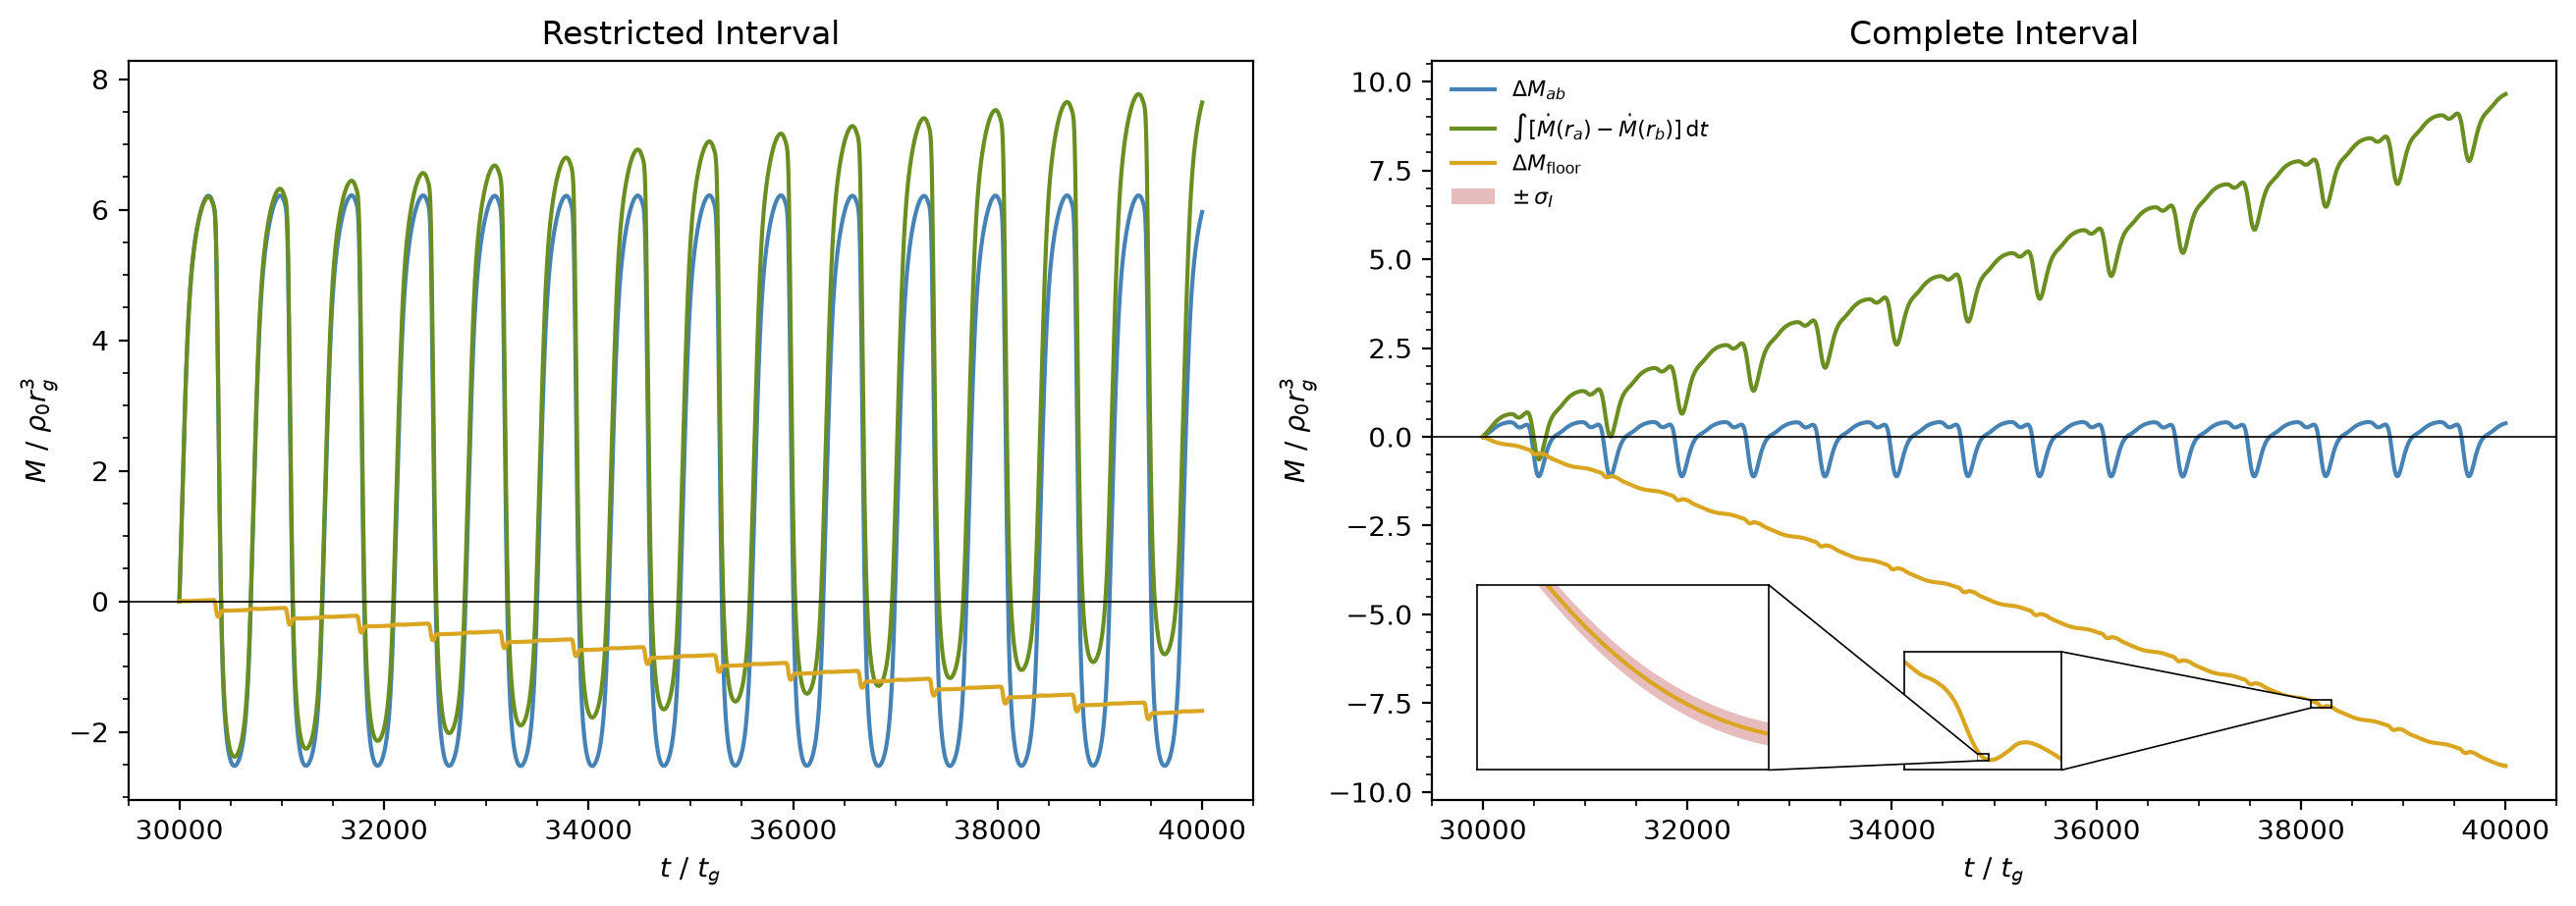

Restricted Interval:  residual -1.678e+00 +- 4.5e-03  (z = -369.0),  -3.4% of the mass accreted through r_a,  lag-one autocorrelation 0.99
Complete Interval:  residual -9.265e+00 +- 9.5e-04  (z = -9749.3),  -18.3% of the mass accreted through r_a,  lag-one autocorrelation 0.99


In [21]:
def shell_mass(Cx, a, b):
    return Cx['m_hi'][:, a] + Cx['m_lo'][:, b] + np.sum(Cx['m_lo'][:, a + 1:b] + Cx['m_hi'][:, a + 1:b], axis=1)

def cumulative_trapezoid(t, y):
    return np.concatenate([[0.0], np.cumsum(0.5 * (y[1:] + y[:-1]) * np.diff(t))])

def mass_budget(Cx, a, b):
    t = Cx['t']
    net = Cx['mdot'][:, a] - Cx['mdot'][:, b]
    flux_int = cumulative_trapezoid(t, net)

    t_e, t_o = t[0::2], t[1::2]
    I_full_e = np.interp(t_e[-1], t, flux_int) - np.interp(t_e[0], t, flux_int)
    I_full_o = np.interp(t_o[-1], t, flux_int) - np.interp(t_o[0], t, flux_int)
    err = max(abs(I_full_e - cumulative_trapezoid(t_e, net[0::2])[-1]), abs(I_full_o - cumulative_trapezoid(t_o, net[1::2])[-1]))

    M_ab = shell_mass(Cx, a, b)
    dM = M_ab - M_ab[0]

    x = net - net.mean()
    ac1 = np.sum(x[1:] * x[:-1]) / np.sum(x * x)

    return dict(t=t, dM=dM, flux=flux_int, floor=dM - flux_int, err=(t - t[0]) / (t[-1] - t[0]) * err, ac1=ac1,
                inflow=-Cx['mdot'][:, a].mean())

def bend(y):
    chord = np.linspace(y[0], y[-1], y.size)
    return np.max(np.abs(y - chord)) / max(np.ptp(y), 1e-300)

def frac_point(parent, box, x, y):
    (x0, x1), (y0, y1) = parent.get_xlim(), parent.get_ylim()
    return box[0] + box[2] * (x - x0) / (x1 - x0), box[1] + box[3] * (y - y0) / (y1 - y0)

def frac_box(parent, box, xlim, ylim):
    return (*frac_point(parent, box, xlim[0], ylim[0]), *frac_point(parent, box, xlim[1], ylim[1]))

def box_corners(box):
    x0, y0, x1, y1 = box
    return [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]

def view_box(bounds):
    return (bounds[0], bounds[1], bounds[0] + bounds[2], bounds[1] + bounds[3])

def funnel_corners(window, view, pairs):
    w, v = box_corners(window), box_corners(view)
    (i, j), (k, l) = pairs
    return [w[i], w[k], v[l], v[j]]

def intersects(p, q, a, b):
    side = lambda u, v, w: np.sign((v[0] - u[0]) * (w[1] - u[1]) - (v[1] - u[1]) * (w[0] - u[0]))
    return side(p, q, a) != side(p, q, b) and side(a, b, p) != side(a, b, q)

def floor_inset(ax, parent, B, bounds, xlim, ylim, smooth=False):
    t, y, err = B['t'], B['floor'], B['err']

    if smooth:
        near = (t >= xlim[0] - 10 * (t[1] - t[0])) & (t <= xlim[1] + 10 * (t[1] - t[0]))
        t_fine = np.linspace(*xlim, 400)
        y = CubicSpline(t[near], uniform_filter1d(y[near], 3, mode='nearest'))(t_fine)
        err = np.interp(t_fine, t, err)
        t = t_fine

    axin = ax.inset_axes(bounds)
    axin.plot(t, y, color='C2')
    axin.fill_between(t, y - err, y + err, alpha=0.3, lw=0, color='firebrick')

    axin.set_xlim(*xlim)
    axin.set_ylim(*ylim)
    axin.set_xticks([])
    axin.set_yticks([])
    axin.minorticks_off()
    for spine in axin.spines.values():
        spine.set_linewidth(0.6)

    parent.add_patch(mpl.patches.Rectangle((xlim[0], ylim[0]), xlim[1] - xlim[0], ylim[1] - ylim[0], fill=False, ec='k', lw=0.6, zorder=5))

    return axin

def draw_funnel(host, ax, window, view, pairs, zorder):
    w, v = box_corners(window), box_corners(view)
    host.add_artist(mpl.patches.Polygon(funnel_corners(window, view, pairs), closed=True, fc='w', ec='none',
                                        transform=ax.transAxes, clip_on=False, zorder=zorder))
    for i, j in pairs:
        host.add_artist(Line2D(*zip(w[i], v[j]), color='k', lw=0.6, transform=ax.transAxes, clip_on=False, zorder=zorder))

def band_window(ax, axin, outer, inner, B, lo, c, n_sigma):
    t, y, err = B['t'], B['floor'], B['err']
    W, H = ax.figure.get_size_inches() * ax.get_position().size
    view = view_box(inner)
    aspect = (view[2] - view[0]) * W / ((view[3] - view[1]) * H)

    curve = [frac_point(axin, outer, t[i], y[i]) for i in range(lo, c + 1)]
    pairs = [(3, 2), (0, 1)]
    candidates = []

    for r in range(c - 1, lo, -1):
        h = n_sigma * err[r]
        y0, y1 = frac_point(axin, outer, t[r], y[r] - h)[1], frac_point(axin, outer, t[r], y[r] + h)[1]
        half = 0.5 * aspect * (y1 - y0) * H / W / outer[2] * np.ptp(axin.get_xlim())
        xlim, ylim = (t[r] - half, t[r] + half), (y[r] - h, y[r] + h)
        if xlim[1] >= t[c]:
            continue

        window = frac_box(axin, outer, xlim, ylim)
        candidates.append((xlim, ylim))

        outside = [p for p in curve if not (window[0] <= p[0] <= window[2] and window[1] <= p[1] <= window[3])]
        lines = [(box_corners(window)[i], box_corners(view)[j]) for i, j in pairs]
        crossing = any(intersects(*line, p, q) for line in lines for p, q in zip(outside[:-1], outside[1:]))
        covered = mpl.path.Path(funnel_corners(window, view, pairs)).contains_points(outside).any() if outside else False
        if not crossing and not covered:
            return xlim, ylim, window, pairs

    xlim, ylim = candidates[-1]
    return xlim, ylim, frac_box(axin, outer, xlim, ylim), pairs

def floor_zoom(ax, B, outer=(0.42, 0.04, 0.14, 0.16), inner=(0.04, 0.04, 0.26, 0.25), n_sigma=8.0, after=0.6):
    t, y = B['t'], B['floor']
    n = t.size
    m = max(n // 100, 4)

    ax.set_xlim(ax.get_xlim())
    ax.set_ylim(ax.get_ylim())

    centres = np.arange(max(int(np.searchsorted(t, t[0] + after * (t[-1] - t[0]))), m), n - n // 20)
    k = centres[np.argmax([bend(y[c - m:c + m + 1]) for c in centres])]
    lo, hi = k - m, k + m

    span = np.ptp(y[lo:hi + 1])
    mid = 0.5 * (y[lo:hi + 1].max() + y[lo:hi + 1].min())
    xlim, ylim = (t[lo], t[hi]), (mid - 0.6 * span, mid + 0.6 * span)
    axin = floor_inset(ax, ax, B, outer, xlim, ylim)
    draw_funnel(ax, ax, frac_box(ax, (0, 0, 1, 1), xlim, ylim), view_box(outer), [(3, 2), (0, 1)], 4)

    seg = y[lo:hi + 1]
    dips = np.nonzero((seg[1:-1] < seg[:-2]) & (seg[1:-1] <= seg[2:]))[0] + 1
    rise = [seg[i:].max() - seg[i] for i in dips]
    c = lo + (int(dips[np.argmax(rise)]) if dips.size else int(np.argmin(seg)))

    xlim, ylim, window, pairs = band_window(ax, axin, outer, inner, B, lo, c, n_sigma)
    floor_inset(ax, axin, B, inner, xlim, ylim, smooth=True)
    draw_funnel(axin, ax, window, view_box(inner), pairs, 10)

S = RUN['S']
IA = int(np.argmin(np.abs(R_C - R_BUDGET[0])))
IB = int(np.argmin(np.abs(R_C - R_BUDGET[1])))
budgets = [("Restricted Interval", mass_budget(S, IA, IB)),
           ("Complete Interval", mass_budget(S, 0, NR - 1))]

fig, axs = plt.subplots(1, 2, figsize=[13, 4.5])

for ax, (title, B) in zip(axs, budgets):
    ax.plot(B['t'], B['dM'], label=r'$\Delta M_{ab}$')
    ax.plot(B['t'], B['flux'], label=r'$\int [\dot M(r_a) - \dot M(r_b)]\,\mathrm{d}t$')
    ax.plot(B['t'], B['floor'], label=r'$\Delta M_\mathrm{floor}$')
    ax.fill_between(B['t'], B['floor'] - B['err'], B['floor'] + B['err'], alpha=0.3, lw=0, color='firebrick', label=r'$\pm\,\sigma_I$')
    ax.axhline(0, color='k', lw=0.6)

    ax.set_title(title)
    ax.set_xlabel(r'$t\ /\ t_g$')
    ax.set_ylabel(r'$M\ /\ \rho_0 r_g^3$')

floor_zoom(axs[1], budgets[1][1])

axs[1].legend(fontsize=8)

plt.show()

for title, B in budgets:
    tau = B['t'][-1] - B['t'][0]
    print(f"{title}:  residual {B['floor'][-1]:+.3e} +- {B['err'][-1]:.1e}  (z = {B['floor'][-1] / B['err'][-1]:+.1f}),"
          f"  {B['floor'][-1] / (B['inflow'] * tau):+.1%} of the mass accreted through r_a,  lag-one autocorrelation {B['ac1']:.2f}")

B_MAIN = budgets[0][1]
FLOOR_FRAC = B_MAIN['floor'][-1] / (B_MAIN['inflow'] * (B_MAIN['t'][-1] - B_MAIN['t'][0]))
FLOOR_Z = B_MAIN['floor'][-1] / B_MAIN['err'][-1]

### 4. Waves

#### 4.1. Diagram

The semisteady disk carries quasiperiodic density enhancements that travel outward. All wave diagnostics use 

$$\delta(r, t) = \frac{\Sigma(r,t)}{\langle\Sigma\rangle_t(r)} - 1$$

as the relative perturbation of the surface density. A cadence of $50\,t_g$ resolves periods above $100\,t_g$ whereas a dense $5\,t_g$ segment resolves the pulse shape and short travel times between neighbouring cells. Outward travelling waves appear as ridges tilted towards larger $r$ with time.

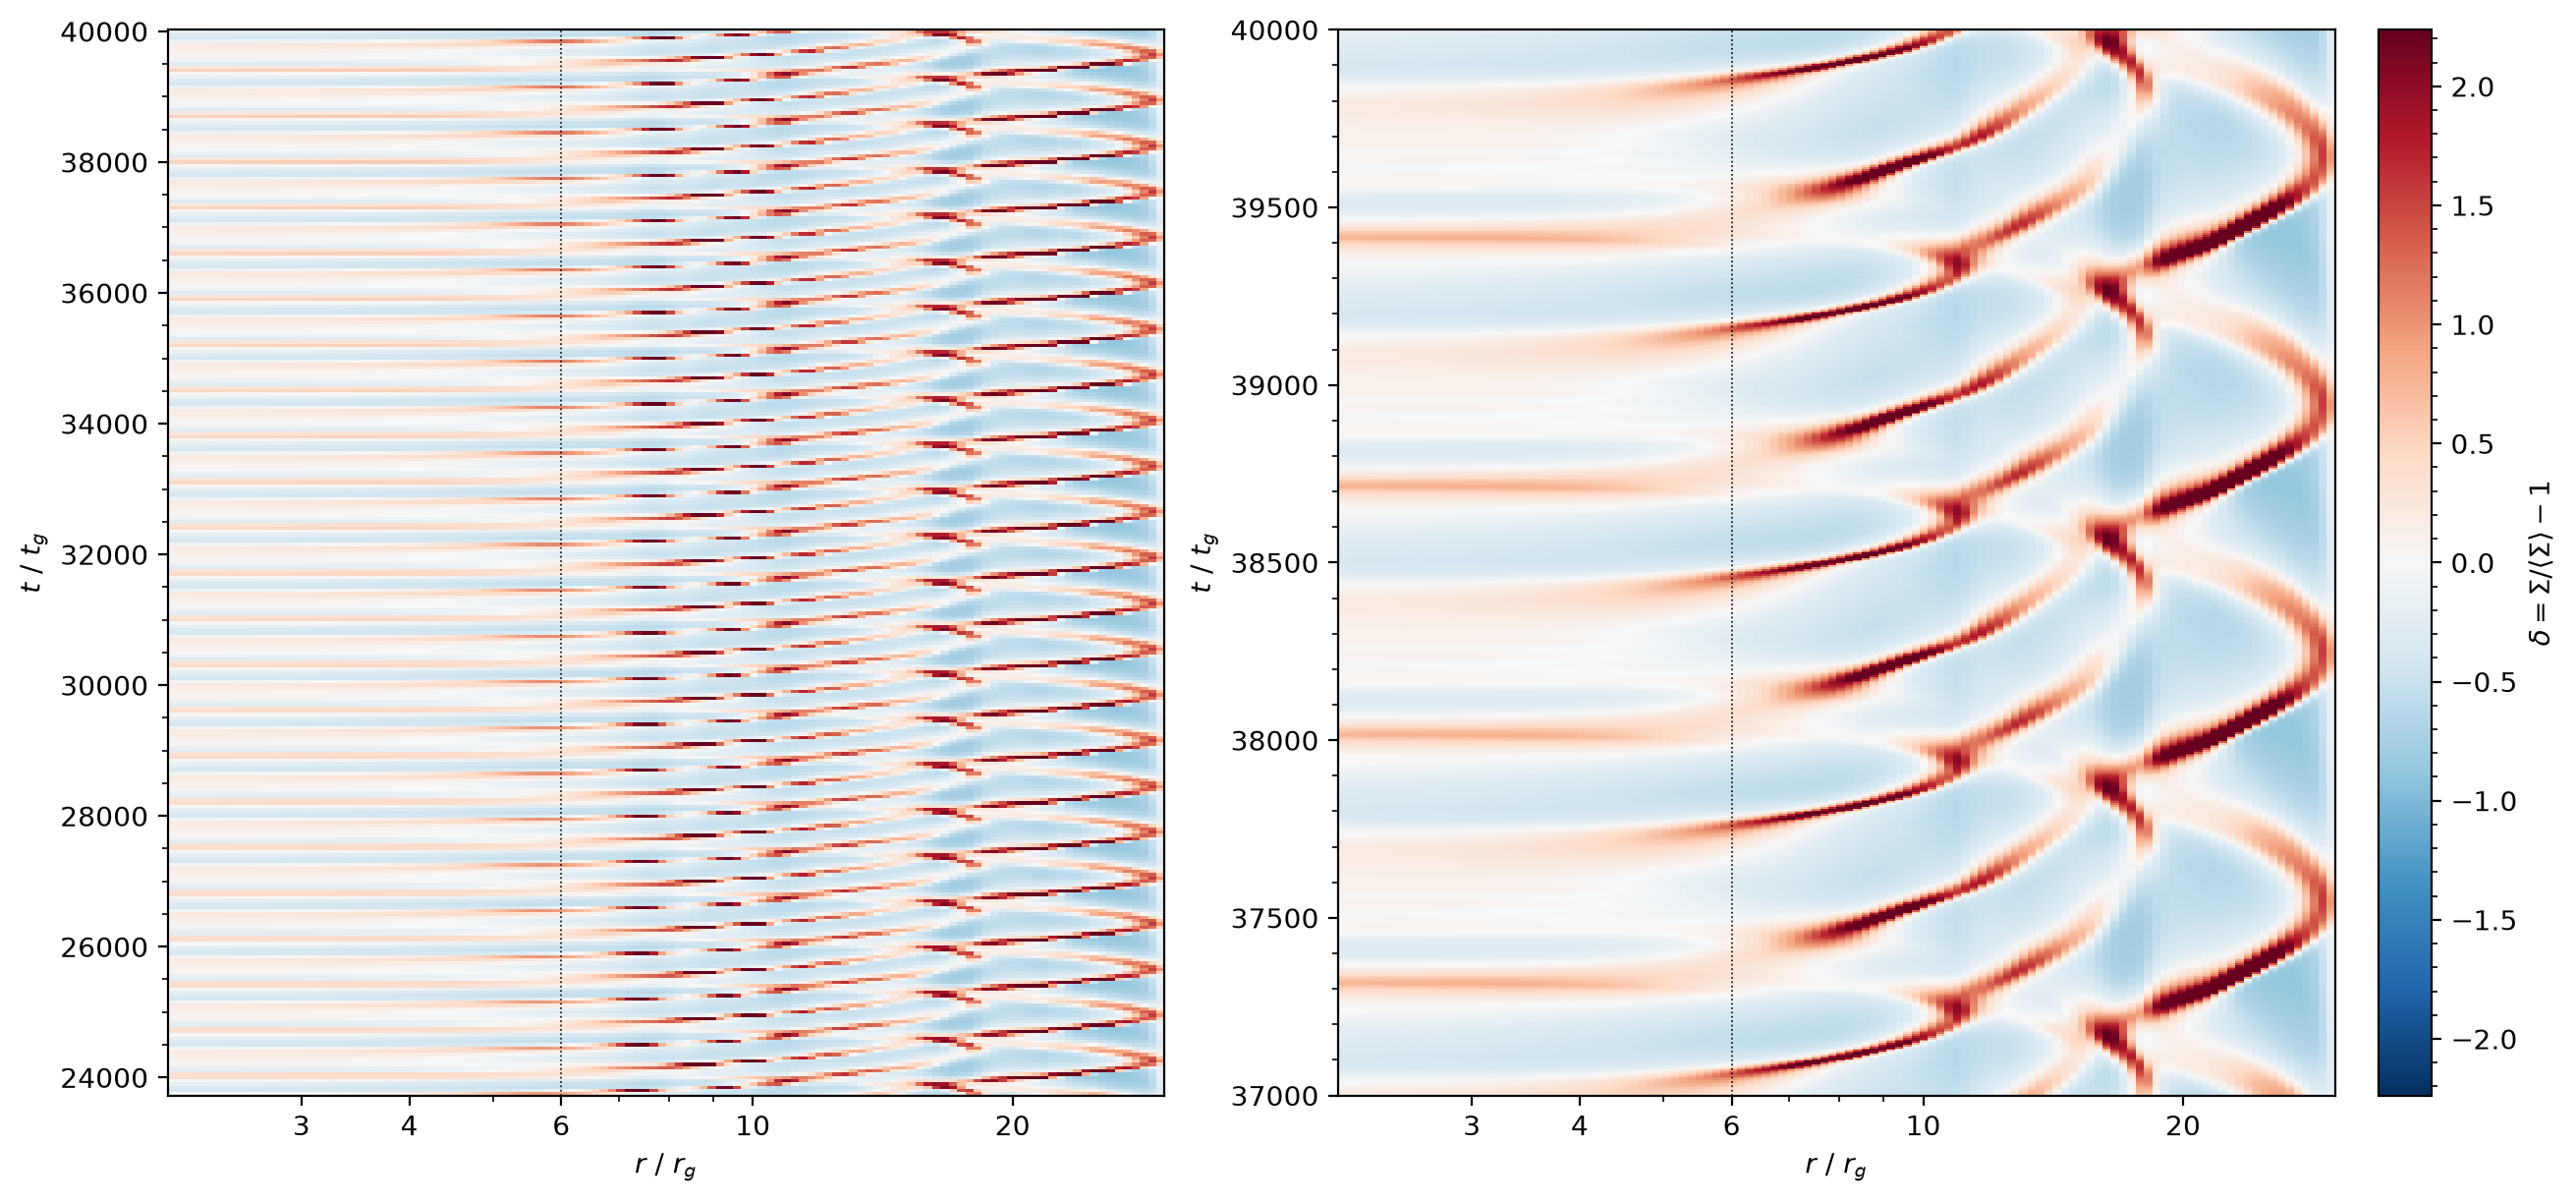

In [22]:
for run in RUNS:
    run['delta'] = run['S']['sigma'] / run['S']['sigma'].mean(axis=0)[None, :] - 1.0

DELTA_LONG = C['sigma'][SEL] / C['sigma'][SEL].mean(axis=0)[None, :] - 1.0
amp = np.nanpercentile(np.abs(DELTA_LONG), 99)
dnorm = TwoSlopeNorm(vmin=-amp, vcenter=0.0, vmax=amp)

fig, axs = plt.subplots(1, 2, figsize=[13, 6], sharex=True)

spacetime(axs[0], TS, DELTA_LONG, dnorm, 'RdBu_r')
im = spacetime(axs[1], RUN['ts'], RUN['delta'], dnorm, 'RdBu_r', tlim=(max(RUN['ts'][0], RUN['ts'][-1] - 3000), RUN['ts'][-1]))

for ax in axs:
    ax.axvline(6.0, color='k', lw=0.6, ls=':')

fig.colorbar(im, ax=axs, label=r'$\delta = \Sigma / \langle\Sigma\rangle - 1$', pad=0.02)

plt.show()

#### 4.2. Frequency

The power spectrum $P(r, \nu_f)$ of $\delta(r,t)$ at every radius is depicted. A mode launched at one radius and travelling through the disk appears at the same frequency at all radii, while locally excited oscillations would follow one of the local frequencies. The radius averaged spectrum normalizes each radius to unit total power

$$\langle P\rangle_r = \langle P(r,\nu_f)/\sum_{\nu_f} P(r,\nu_f)\rangle_r$$

so that it compares the spectral shape of both runs independently of the wave amplitude. The dominant frequency $\nu_\mathrm{peak}$ is its maximum, with an uncertainty of about half a frequency bin.

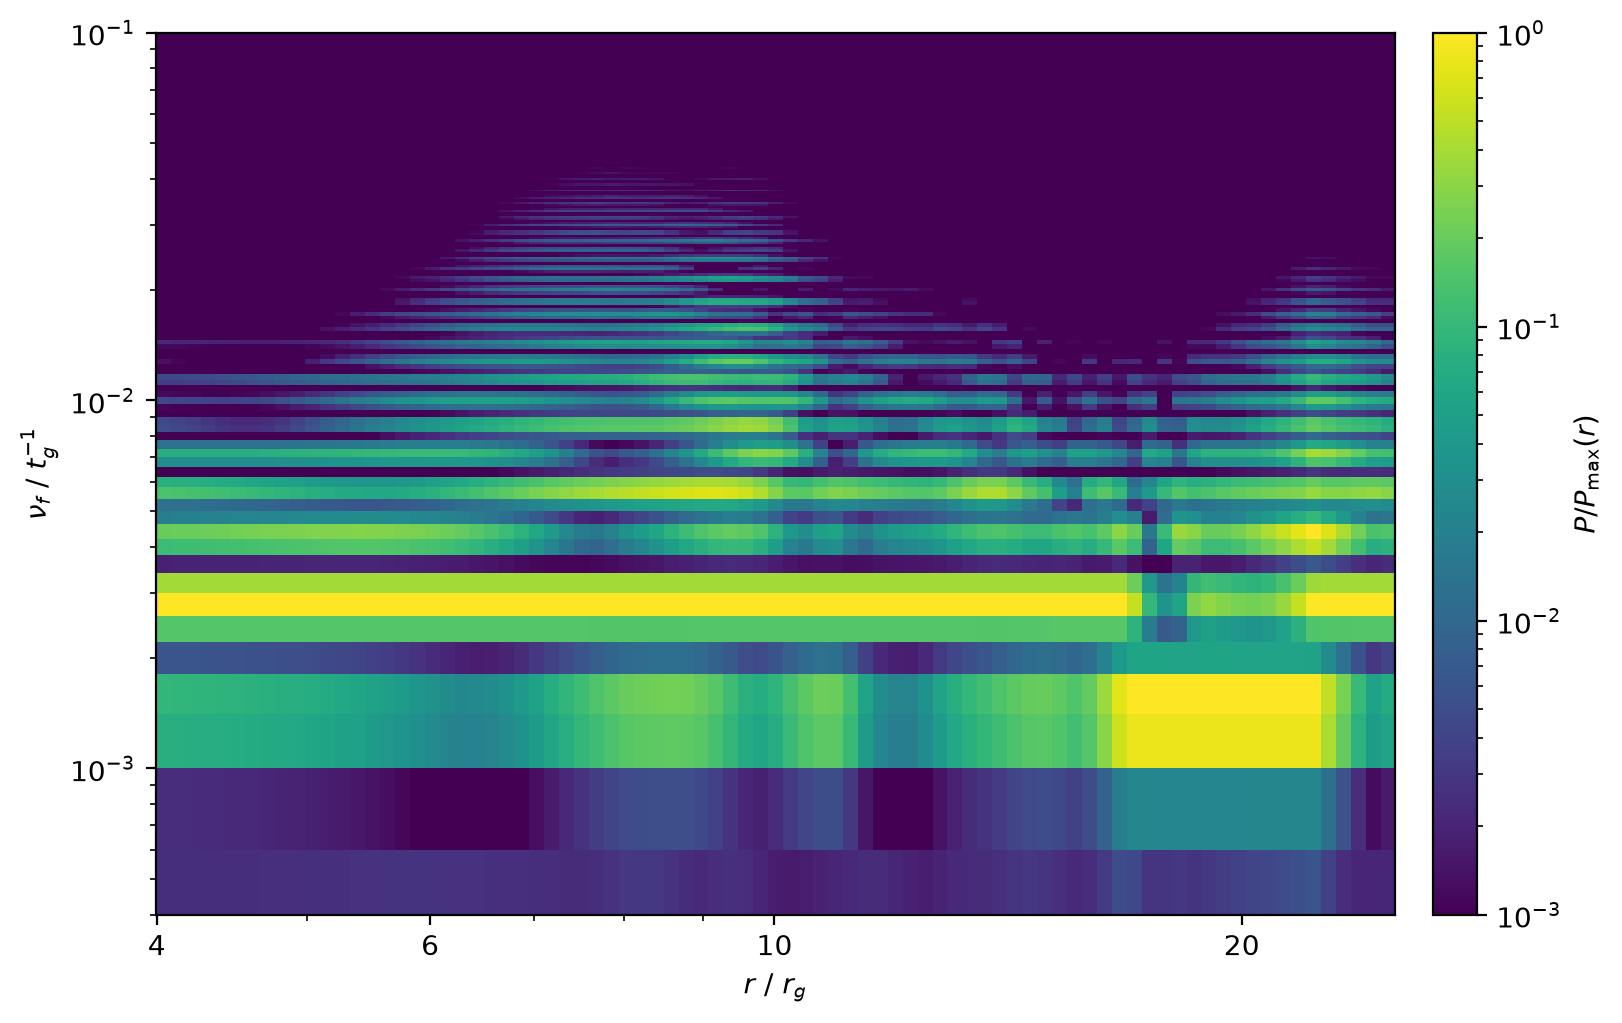

In [23]:
def wave_spectrum(run):
    r = run['r']
    w = (r >= R_WAVE[0]) & (r <= R_WAVE[1])

    f, P = welch(run['delta'][:, w], run['dt_s'])
    glob = np.concatenate([[0.0], (P[1:] / P[1:].sum(axis=0, keepdims=True)).mean(axis=1)])
    f_pk, df = peak_frequency(f, glob)

    return f, P, w, f_pk, df

for run in RUNS:
    run['f_w'], run['P_w'], run['wave'], run['f_peak'], run['df_peak'] = wave_spectrum(run)

F_PEAK = RUN['f_peak']

f_w, P_w, WAVE = RUN['f_w'], RUN['P_w'], RUN['wave']
Rw = R_C[WAVE]

fig, ax = plt.subplots(1, 1, figsize=[8, 5])

im = ax.pcolormesh(Rw, f_w[1:], P_w[1:] / P_w[1:].max(axis=0, keepdims=True), cmap='viridis',
                   norm=LogNorm(vmin=1e-3, vmax=1e0), shading='nearest', rasterized=True)
plt.colorbar(im, ax=ax, label=r'$P / P_\max(r)$', pad=0.03)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(f_w[1], f_w[-1])
plain_log(ax, 'x')

ax.set_xlabel(r'$r\ /\ r_g$')
ax.set_ylabel(r'$\nu_f\ /\ t_g^{-1}$')

plt.show()

#### 4.3. Phase

The phase speed follows from the cross spectral density of $\delta$ at each radius $r$ with $\delta$ at the reference radius $r_0 =$ `R_PHASE_REF` at the dominant frequency $\nu_\mathrm{peak}$ determined before. A wave that reaches $r$ a time $\Delta t(r)$ after $r_0$ has the phase lag

$$\varphi(r) = -\arg P_{0r}(\nu_\mathrm{peak}) = 2\pi\nu_\mathrm{peak}\,\Delta t(r) \qquad P_{0r} = \langle \hat\delta_0^*\, \hat\delta_r \rangle$$

unwrapped from $r_0$ outward and inward, cell by cell. The local phase speed is the inverse slope of $\varphi(r)$

$$v_p(r) = 2\pi\nu_\mathrm{peak}\left(\frac{\mathrm{d}\varphi}{\mathrm{d}r}\right)^{-1}$$

from a straight line fit over $r$ and a mean phase speed from another $r_0 \leq r \leq 15$ fit.

Phases are trusted where the magnitude squared coherence $\gamma^2 = |P_{0r}|^2/(P_{00} P_{rr})$ exceeds its $95\%$ significance level for $n_d$ independent segments, defined by $\gamma^2_\mathrm{crit} = 1 - 0.05^{1/(n_d - 1)}$ and where the fundamental still carries a minimum of the peak power of the local spectrum. Further out, pairs of pulses merge and the spectrum moves to the subharmonic, so the phase at $\nu_\mathrm{peak}$ loses its meaning. Only the contiguous trusted region around $r_0$ is used. The phase error is $\sigma_\varphi = \sqrt{(1 - \gamma^2)/(2 n_d \gamma^2)}$ and the fit error is the larger of the one from $\sigma_\varphi$ and the one from the scatter of the residuals. Note that with a single segment the coherence is identically one, which is why the spectra use a minimum amount of segments.

The phase speed is compared with the sound speeds in the midplane, the adiabatic speed of the gas radiation mixture and the
isothermal case

$$c_\mathrm{ad}^2 = \frac{\gamma\, p + \tfrac{4}{3}\, p_r}{\rho} \qquad c_\mathrm{iso}^2 = \frac{p + p_r}{\rho} \qquad p_r = \frac{E_r}{3}$$

as well as the $c_\mathrm{gas}^2 = \gamma p/\rho$ gas sound speed. Without the $v/c$ terms included, compression does no work on the
radiation, so the effective stiffness on the wave time lies between $c_\mathrm{gas}$ and $c_\mathrm{iso}$ rather than at
$c_\mathrm{ad}$ as otherwise expected. Also shown are the mean radial velocity $\langle v_r\rangle$ and the viscous speed $\nu/R$ curves.

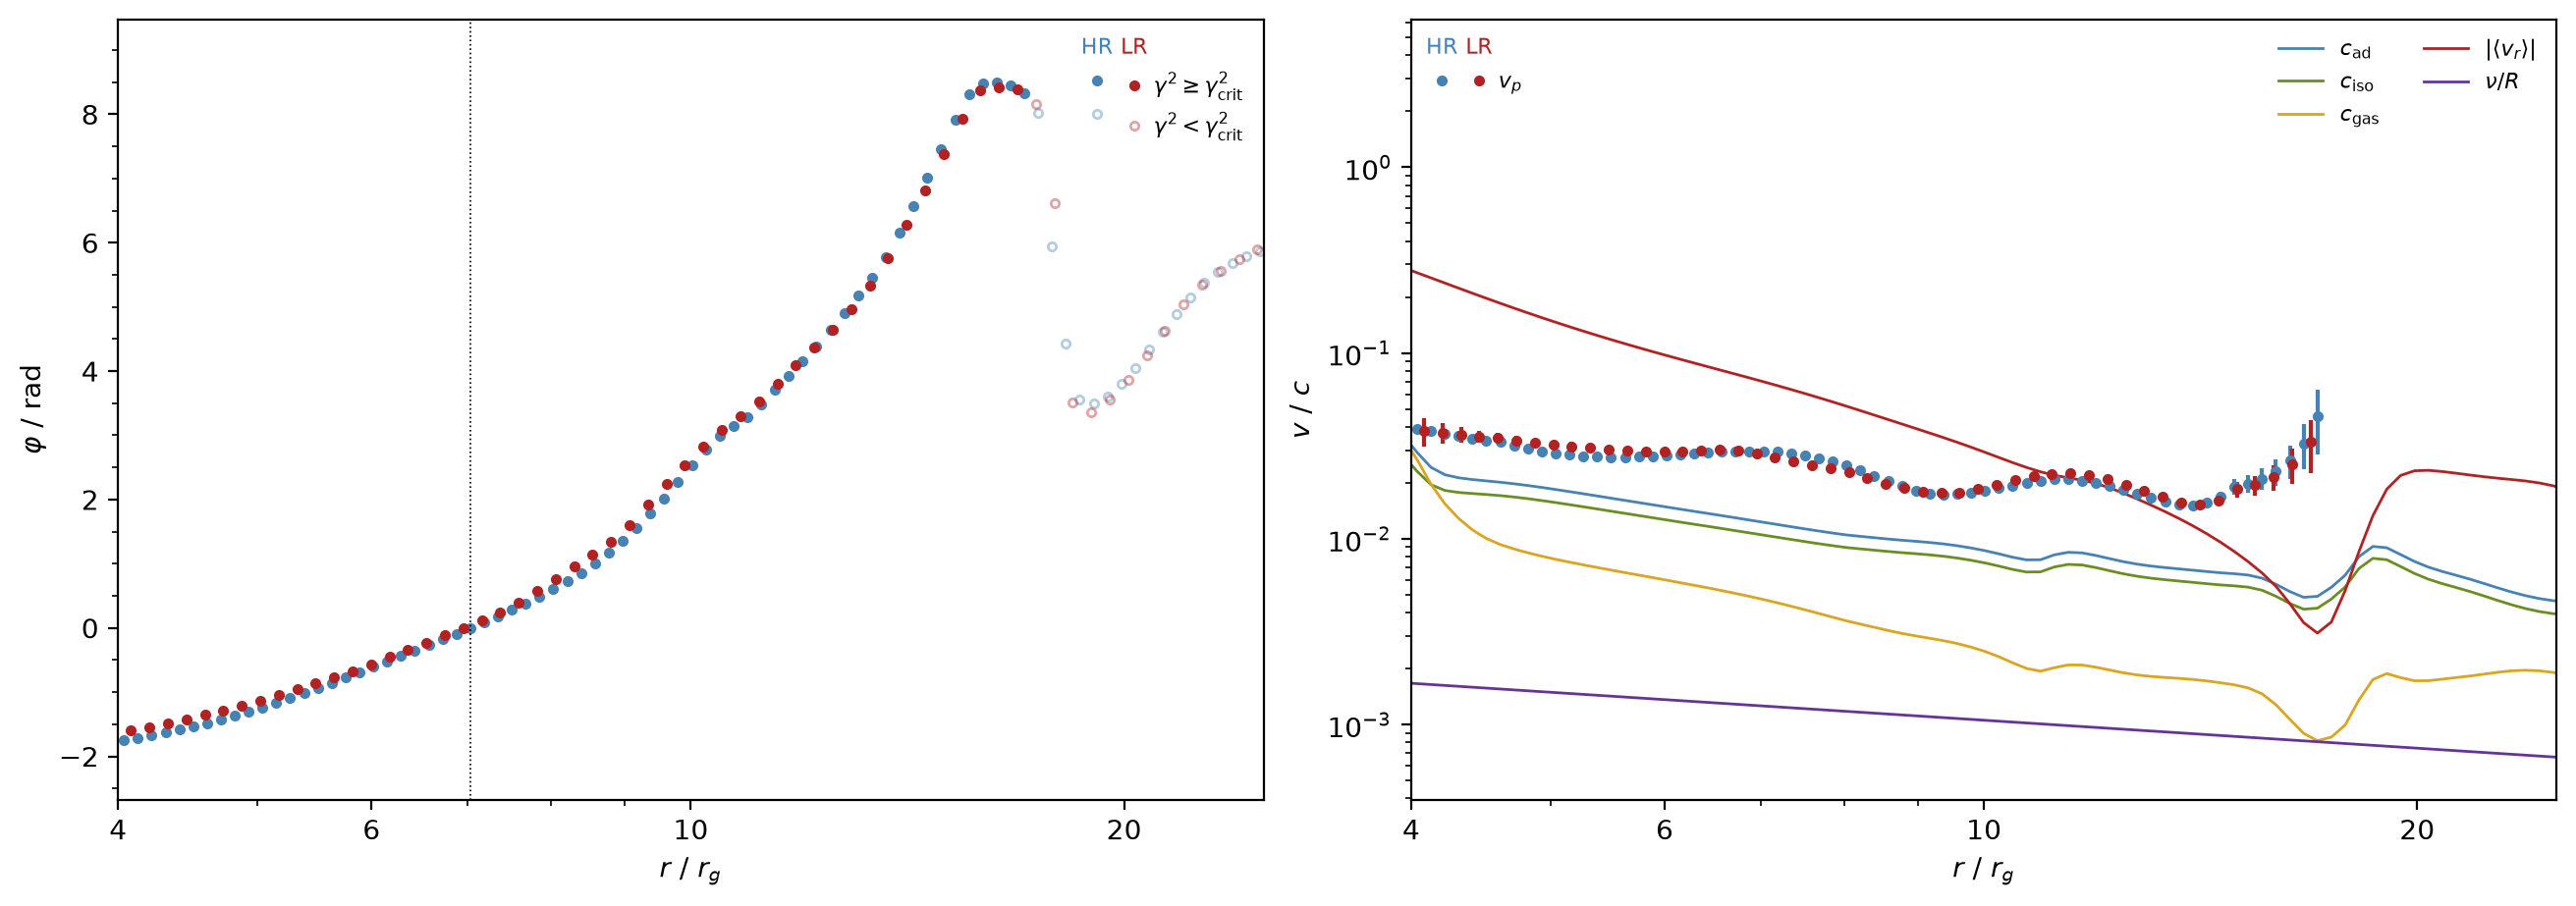

HR: 7 segments (4 independent), gamma^2_crit = 0.63,  trusted r in [4.0, 17.1],  mean phase speed for r in [7, 15] = 0.0190 +- 0.0002 c
LR: 31 segments (16 independent), gamma^2_crit = 0.18,  trusted r in [4.1, 16.9],  mean phase speed for r in [7, 15] = 0.0195 +- 0.0002 c
HR: median ratios over the trusted region  v_p / c_ad = 2.22,  v_p / c_iso = 2.59,  v_p / c_gas = 6.52


In [24]:
def contiguous(good, i0):
    out = np.zeros_like(good)
    if not good[i0]:
        return out

    i = i0
    while i < good.size and good[i]:
        out[i] = True
        i += 1

    i = i0 - 1
    while i >= 0 and good[i]:
        out[i] = True
        i -= 1

    return out

def phase_profile(run):
    d, r, dt, f0 = run['delta'], run['r'], run['dt_s'], run['f_peak']
    _, nseg, nind = welch_len(d.shape[0], dt)
    kw = welch_kw(d.shape[0], dt)

    i0 = int(np.argmin(np.abs(r - R_PHASE_REF)))
    f, P0r = signal.csd(d[:, [i0]], d, **kw)
    _, g2 = signal.coherence(d[:, [i0]], d, **kw)
    _, Prr = signal.welch(d, **kw)
    k = int(np.argmin(np.abs(f - f0)))

    lag = -np.angle(P0r[k])
    ph = np.empty_like(lag)
    ph[i0:] = np.unwrap(lag[i0:])
    ph[:i0 + 1] = np.unwrap(lag[:i0 + 1][::-1])[::-1]

    g2k = np.clip(g2[k], 1e-9, 1.0)
    sig = np.sqrt((1.0 - g2k) / (2.0 * nind * g2k))
    share = Prr[k] / Prr[1:].max(axis=0)
    g2_crit = 1.0 - 0.05**(1.0 / (nind - 1)) if nind > 1 else 1.0
    good = (g2k >= g2_crit) & (share >= P_FUND_MIN) & (r >= R_WAVE[0]) & (r <= R_WAVE[1])

    return dict(ph=ph - ph[i0], sig=sig, g2_crit=g2_crit, valid=contiguous(good, i0), f=f[k], nseg=nseg, nind=nind, i0=i0)

def line_fit(x, y, s):
    xm = x - x.mean()
    slope = np.sum(xm * y) / np.sum(xm**2)
    resid = y - y.mean() - slope * xm
    se_res = np.sqrt(np.sum(resid**2) / max(x.size - 2, 1) / np.sum(xm**2))
    se_w = np.sqrt(1.0 / np.sum(xm**2 / np.maximum(s, 1e-6)**2))
    return slope, max(se_res, se_w)

def phase_speed(r, Ph, rmin=None, rmax=None):
    om = 2.0 * np.pi * Ph['f']

    if rmin is not None:
        m = Ph['valid'] & (r >= rmin) & (r <= rmax)
        if m.sum() < 4:
            return np.nan, np.nan
        b, eb = line_fit(r[m], Ph['ph'][m], Ph['sig'][m])
        return om / b, om / b * eb / abs(b)

    v, ev = np.full(r.size, np.nan), np.full(r.size, np.nan)
    for i in np.nonzero(Ph['valid'])[0]:
        m = Ph['valid'] & (np.abs(np.log(r / r[i])) <= np.log1p(FIT_FRAC))
        if m.sum() >= 4:
            b, eb = line_fit(r[m], Ph['ph'][m], Ph['sig'][m])
            v[i], ev[i] = om / b, abs(om / b) * eb / abs(b)
    return v, ev

for run in RUNS:
    run['Ph'] = phase_profile(run)
    run['v_p'], run['v_p_err'] = phase_speed(run['r'], run['Ph'])
    run['v_mean'], run['v_mean_err'] = phase_speed(run['r'], run['Ph'], R_PHASE_REF, 15.0)

S = RUN['S']
rho_m = S['rho_mid'].mean(axis=0)
prs_m = S['prs_mid'].mean(axis=0)
pr_m = S['enr_mid'].mean(axis=0) / 3.0
vr_m = S['vr_mid'].mean(axis=0)

c_ad = np.sqrt((GAMMA * prs_m + 4.0 / 3.0 * pr_m) / rho_m)
c_iso = np.sqrt((prs_m + pr_m) / rho_m)
c_gas = np.sqrt(GAMMA * prs_m / rho_m)

speeds = [(c_ad, r'$c_\mathrm{ad}$'),
          (c_iso, r'$c_\mathrm{iso}$'),
          (c_gas, r'$c_\mathrm{gas}$'),
          (np.abs(vr_m), r'$|\langle v_r\rangle|$'),
          (nu_kin(R_C) / R_C, r'$\nu/R$')]

fig, axs = plt.subplots(1, 2, figsize=[13, 4.5])

for run in RUNS:
    r, Ph = run['r'], run['Ph']
    v = Ph['valid']

    axs[0].plot(r[v], Ph['ph'][v], 'o', ms=3, color=run['color'])
    axs[0].plot(r[~v], Ph['ph'][~v], 'o', ms=3, mfc='none', color=run['color'], alpha=0.4)

    axs[1].errorbar(r, run['v_p'], yerr=run['v_p_err'], fmt='o', ms=3, color=run['color'], ls='none')

for y, lab in speeds:
    axs[1].plot(R_C, y, lw=1, label=lab)

axs[0].axvline(R_C[RUN['Ph']['i0']], color='k', lw=0.6, ls=':')

for ax in axs:
    ax.set_xscale('log')
    ax.set_xlim(*R_WAVE)
    ax.set_xlabel(r'$r\ /\ r_g$')
    plain_log(ax, 'x')
axs[1].set_yscale('log')

axs[0].set_ylabel(r'$\varphi\ /\ \mathrm{rad}$')
axs[1].set_ylabel(r'$v\ /\ c$')

run_table(axs[0], [(r'$\gamma^2 \geq \gamma^2_\mathrm{crit}$', dict(marker='o', ls='none', ms=3)),
                   (r'$\gamma^2 < \gamma^2_\mathrm{crit}$', dict(marker='o', ls='none', ms=3, mfc='none', alpha=0.4))],
          side='right', fontsize=8)

axs[1].add_artist(axs[1].legend(fontsize=8, ncol=2, loc='upper right'))
run_table(axs[1], [(r'$v_p$', dict(marker='o', ls='none', ms=3))], side='right', fontsize=8, loc='upper left')

plt.show()

for run in RUNS:
    Ph, r = run['Ph'], run['r']
    rv = r[Ph['valid']]

    print(f"{run['label']}: {Ph['nseg']} segments ({Ph['nind']} independent), gamma^2_crit = {Ph['g2_crit']:.2f},"
          f"  trusted r in [{rv.min():.1f}, {rv.max():.1f}],"
          f"  mean phase speed for r in [{R_PHASE_REF:g}, 15] = {run['v_mean']:.4f} +- {run['v_mean_err']:.4f} c")

m = RUN['Ph']['valid'] & np.isfinite(RUN['v_p'])
if m.any():
    print(f"{RUN['label']}: median ratios over the trusted region  v_p / c_ad = {np.median(RUN['v_p'][m] / c_ad[m]):.2f},"
          f"  v_p / c_iso = {np.median(RUN['v_p'][m] / c_iso[m]):.2f},  v_p / c_gas = {np.median(RUN['v_p'][m] / c_gas[m]):.2f}")

#### 4.4. Character

The root mean square amplitude $\delta_\mathrm{rms}(r) = \langle\delta^2\rangle_t^{1/2}$ shows where the waves are launched and whether they grow or decay on the way out. The phase between the midplane density and radial velocity perturbations at $\nu_\mathrm{peak}$ characterizes the wave. For an outward travelling sound wave $\delta v_r / c_s = \delta\rho / \rho$ so that density and velocity are in phase and $\varphi = 0$ holds. A standing wave or an evanescent oscillation shows $\varphi \approx \pm\pi/2$ instead. The same is done for the radiation energy density. An adiabatic wave with radiation work would vary in phase with the density $\delta E_r / E_r = \tfrac{4}{3}\,\delta\rho/\rho$ and without the work term $E_r$ responds only through the heating of the gas and diffusion, so a lag is expected. Only phases above the coherence
threshold are shown.

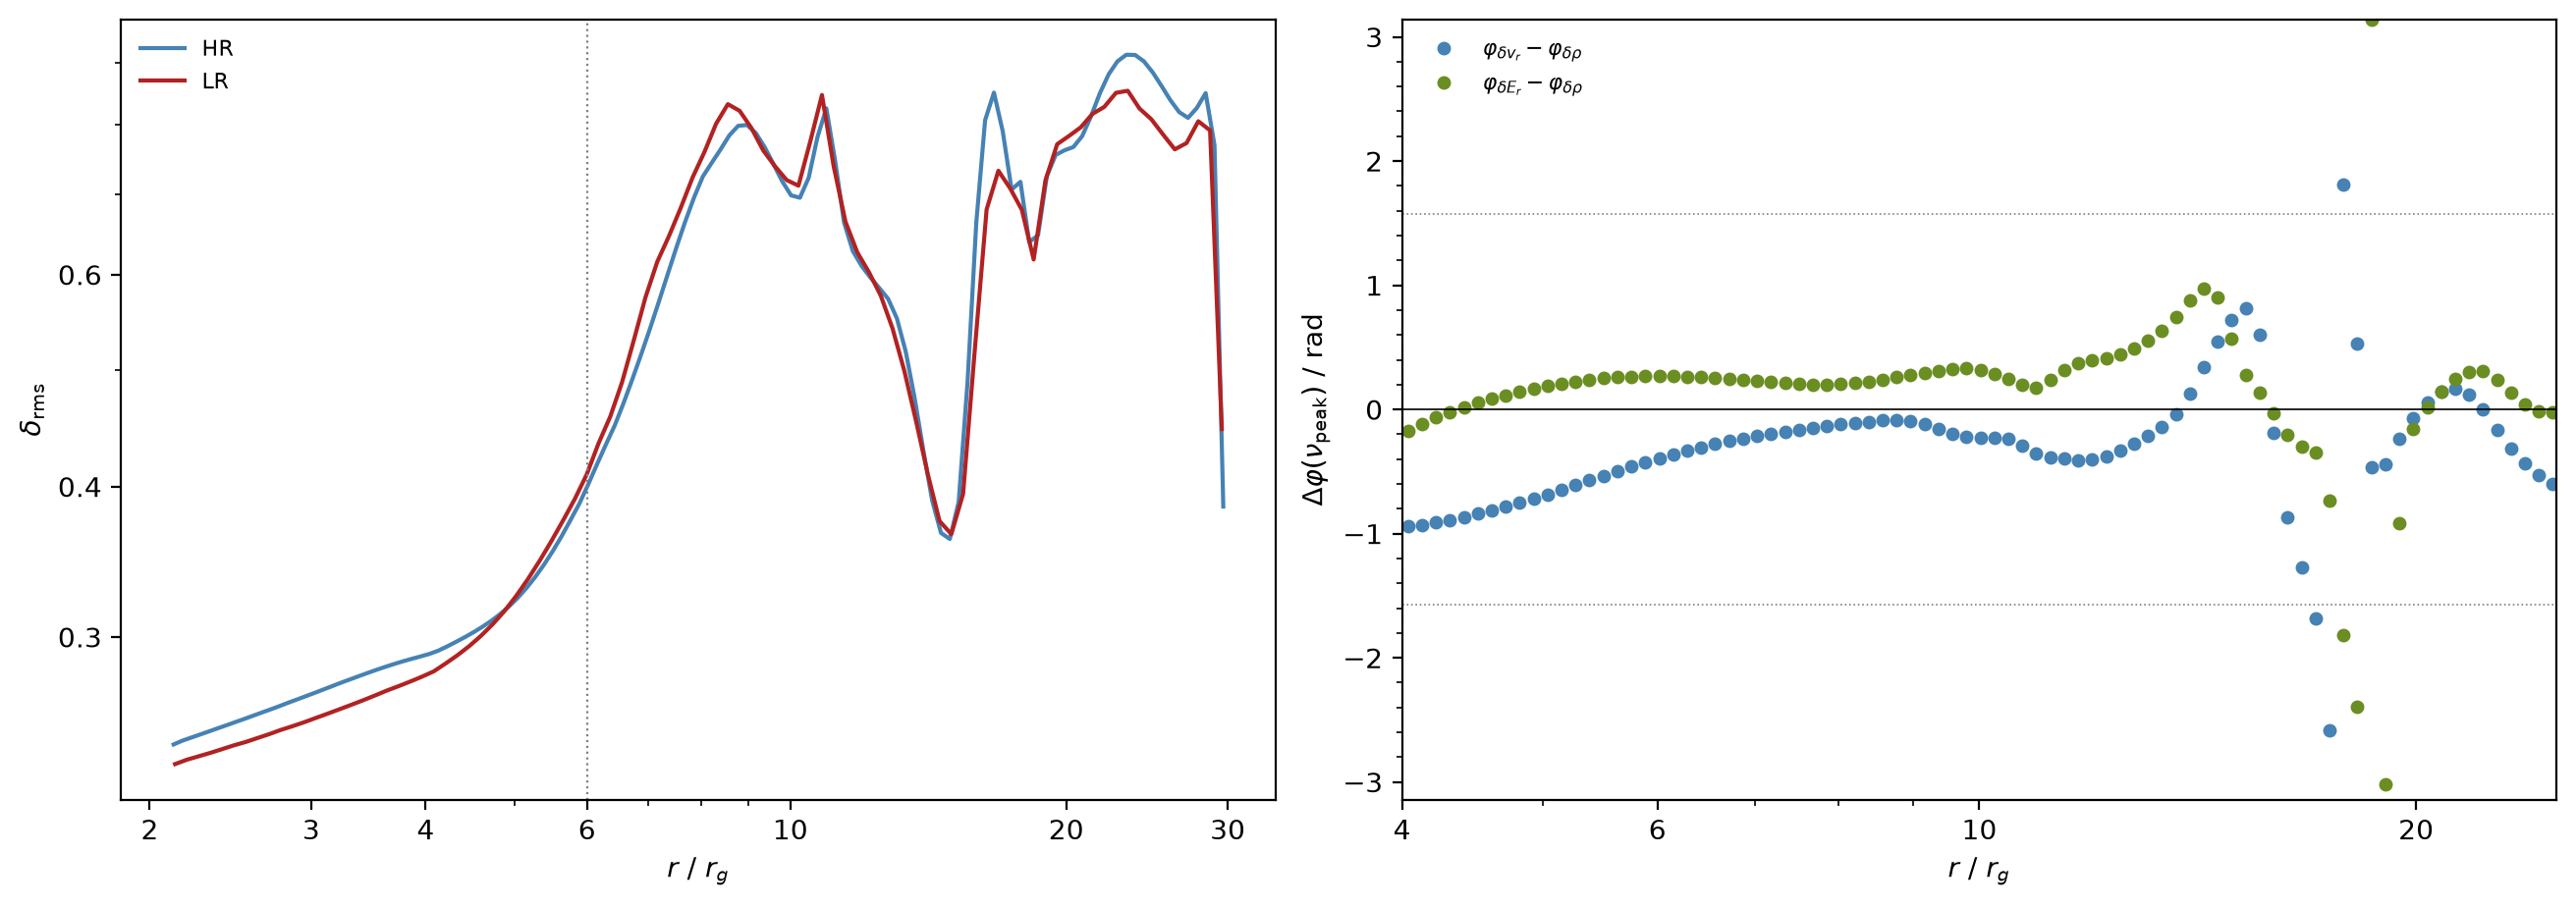

In [25]:
def cross_phase(a, b, dt, f0):
    kw = welch_kw(a.shape[0], dt)
    f_c, P = signal.csd(a, b, **kw)
    _, g2 = signal.coherence(a, b, **kw)
    k = int(np.argmin(np.abs(f_c - f0)))
    return np.angle(P[k]), g2[k]

for run in RUNS:
    run['d_rms'] = np.sqrt(np.mean(run['delta']**2, axis=0))

drho = S['rho_mid'] / rho_m[None, :] - 1.0
dvr = S['vr_mid'] - vr_m[None, :]
dE = S['enr_mid'] / (3.0 * pr_m[None, :]) - 1.0

ph_v, g_v = cross_phase(drho, dvr, RUN['dt_s'], F_PEAK)
ph_E, g_E = cross_phase(drho, dE, RUN['dt_s'], F_PEAK)

fig, axs = plt.subplots(1, 2, figsize=[13, 4.5])

for run in RUNS:
    axs[0].plot(run['r'], run['d_rms'], color=run['color'], ls=run['ls'])

axs[0].axvline(6.0, color='gray', lw=0.8, ls=':')

for ph, g2, lab in [(ph_v, g_v, r'$\varphi_{\delta v_r} - \varphi_{\delta\rho}$'), (ph_E, g_E, r'$\varphi_{\delta E_r} - \varphi_{\delta\rho}$')]:
    m = g2 >= RUN['Ph']['g2_crit']
    axs[1].plot(R_C[m], ph[m], 'o', ms=4, label=lab)

axs[1].axhline(0, color='k', lw=0.6)
for y in [-np.pi / 2, np.pi / 2]:
    axs[1].axhline(y, color='gray', lw=0.6, ls=':')

axs[0].set_xscale('log')
axs[0].set_yscale('log')
plain_log(axs[0], 'x')
plain_log(axs[0], 'y')

axs[1].set_xscale('log')
axs[1].set_xlim(*R_WAVE)
axs[1].set_ylim(-np.pi, np.pi)
plain_log(axs[1], 'x')

axs[0].set_xlabel(r'$r\ /\ r_g$')
axs[0].set_ylabel(r'$\delta_\mathrm{rms}$')
axs[1].set_xlabel(r'$r\ /\ r_g$')
axs[1].set_ylabel(r'$\Delta\varphi(\nu_\mathrm{peak})\ /\ \mathrm{rad}$')

run_legend(axs[0], color=True, fontsize=8)
axs[1].legend(fontsize=8)

plt.show()

### 5. Structure

#### 5.1. Efficiency

The radiative luminosity through a sphere of radius $r$ with the flux in code units $L(r) = 2\,r^2\sum_j F_{r,j}\,\Delta\Omega_j$
is evaluated at the outer boundary and at $r = 20$ distance. The radiative efficiency compares the mean luminosity with the mean rest mass
accretion rate through the inner boundary

$$\eta_\mathrm{rad} = \frac{\langle L\rangle}{\langle\dot M_\mathrm{acc}(r_\mathrm{in})\rangle\, c^2}$$

to be compared with $\eta = 1/16$ for a disk radiating its full binding energy down to $R_\mathrm{isco}$ paths. Radiation that is advected
into the hole or still stored in the disk lowers $\eta_\mathrm{rad}$ and its error combines the relative standard errors of $L$ and
$\dot M_\mathrm{acc}$ in one.

In [26]:
for run in RUNS:
    Cx, s, dt = run['C'], run['sel'], run['dt']

    run['L_out_mean'], run['L_out_se'] = mean_se(Cx['L_out'][s], dt)
    run['L_20_mean'], _ = mean_se(Cx['L_20'][s], dt)
    run['M_d_mean'], run['M_d_se'] = mean_se(Cx['M_d'][s], dt)

    m, em = run['mdot_in_mean'], run['mdot_in_se']
    run['eta'] = run['L_out_mean'] / m if m > 0 else np.nan
    run['eta_se'] = run['eta'] * np.sqrt((run['L_out_se'] / run['L_out_mean'])**2 + (em / m)**2) if m > 0 else np.nan

    print(f"{run['label']}:  <L(r_out)> = {run['L_out_mean'] * L0:.3e} +- {run['L_out_se'] * L0:.1e} erg/s"
          f" = {run['L_out_mean'] * L0 / L_EDD:.4f} L_Edd,   <L(r=20)> = {run['L_20_mean'] * L0 / L_EDD:.4f} L_Edd,"
          f"   eta_rad = {run['eta']:.4f} +- {run['eta_se']:.4f}   (eta_isco = {ETA:.4f})")

HR:  <L(r_out)> = 8.276e+44 +- 3.2e+42 erg/s = 0.0563 L_Edd,   <L(r=20)> = 0.0475 L_Edd,   eta_rad = 0.0481 +- 0.0003   (eta_isco = 0.0625)
LR:  <L(r_out)> = 1.034e+45 +- 2.6e+42 erg/s = 0.0703 L_Edd,   <L(r=20)> = 0.0601 L_Edd,   eta_rad = 0.0486 +- 0.0002   (eta_isco = 0.0625)


#### 5.2. Averages

A second pass reloads frame at a predefined stride of the steady window of the long series and accumulates time averages of the fields, of vertical profiles at fixed cylindrical radii, and of the column heating and cooling rates. 

For vertical force balancing, the radiation force per unit mass $\kappa F$ with $\kappa = \kappa_a + \kappa_s$ in code units, is
compared with the vertical component of gravity in the Paczyński–Wiita potential

$$F_z = F_r\cos\theta - F_\theta\sin\theta \qquad g_z = \frac{\cos\theta}{(r - 2)^2} \qquad \Gamma_z = \frac{\kappa\,F_z}{g_z}$$

so $\Gamma_z = 1$ marks local vertical radiative support, while $\Gamma_z > 1$ means net upward and $\Gamma_z < 1$ net downward acceleration
when gas pressure is negligible. Profiles at fixed $R$ are interpolated linearly in $\log r$ along each ray $\theta_j$ at
$r = R/\sin\theta_j$ distance.

Regarding thermal balance, per unit area of one disk face, the viscous heating integrated over the column and the radiative cooling through the photosphere are

$$Q^+(r) = \sum_j \nu_1\left(r\,\frac{\partial\Omega}{\partial r}\right)^2 r\,\Delta\theta_j, \qquad \Omega = \frac{v_\phi}{r\sin\theta} \qquad Q^-(r) = F_z\big|_{\tau = 1}$$

where $r\,\partial/\partial r$ at fixed $\theta$ equals the $R\,\partial/\partial R$ gradient. In thermal equilibrium $Q^+ = Q^-$ holds. Since Thomson scattering acts in the corona as well, the photosphere can lie above the disk surface where the corona is optically thick, and $Q^-$ is then the flux leaving the corona. Conversely $Q^+$ contains only the explicit viscosity, and if $\alpha_\mathrm{eff} > \alpha$ the
additional transport dissipates energy too, in forms such as shocks of the waves, which $Q^+$ misses. The radiative diffusion time
through the disk is estimated to be

$$t_\mathrm{diff} = \frac{\tau_\mathrm{mid}\, H}{c} \qquad \tau_\mathrm{mid} = \frac{\kappa_\mathrm{es}\,\langle\Sigma\rangle}{2} \qquad H = \left\langle\frac{H}{R}\right\rangle R$$

from the mean surface density and aspect ratio.

In [27]:
def vertical_profile(field, R0):
    r_line = R0 / np.sin(TH_C)
    inside = (r_line >= R_C[0]) & (r_line <= R_C[-1])
    out = np.full(NTH, np.nan)
    lr = np.log(R_C)
    for j in np.nonzero(inside)[0]:
        out[j] = np.interp(np.log(r_line[j]), lr, field[:, j])
    return out

def structure_fields(F):
    Tg, Tr = gas_temperature(F), rad_temperature(F)
    st, ct = np.sin(TH_C)[None, :], np.cos(TH_C)[None, :]

    Fz = F['fr1'] * ct - F['fr2'] * st
    gz = ct / (R_C[:, None] - 2.0)**2
    kap = F['kappa_abs'] + F['kappa_scat']
    gamma_z = np.where(gz > 0, kap * Fz / np.maximum(gz, 1e-300), np.nan)
    vz = F['vx1'] * ct - F['vx2'] * st

    return dict(rho=F['rho'], p_gas=F['prs'], p_rad=F['enr'] / 3.0, T_g=Tg, T_r=Tr, Gamma_z=gamma_z, f=F['diskfrac'], v_z=vz), Fz

def thermal_balance(F, Fz):
    Om = F['vx3'] / (R_C[:, None] * np.sin(TH_C)[None, :])
    shear = R_C[:, None] * np.gradient(Om, R_C, axis=0)
    q_plus = np.sum(F['nu'] * shear**2 * R_C[:, None] * DTH[None, :], axis=1)

    tau = optical_depth_from_pole(F)
    q_minus = np.full(NR, np.nan)
    for i in range(NR):
        j = np.argmax(tau[i] >= 1.0)
        if tau[i, j] >= 1.0:
            q_minus[i] = Fz[i, j]

    return q_plus, q_minus

steady_outs = C['outs'][SEL][::PROFILE_STRIDE]

MEAN2D = {k: np.zeros((NR, NTH)) for k in ['rho', 'T_g', 'T_r', 'f', 'vr', 'vphi']}
PROF = {R0: {} for R0 in R_PROFILES}
QP, QM, NQM = np.zeros(NR), np.zeros(NR), np.zeros(NR)
n_used = 0

for n in steady_outs:
    F = load(n)
    S2, Fz = structure_fields(F)

    for key, val in dict(rho=F['rho'], T_g=S2['T_g'], T_r=S2['T_r'], f=F['diskfrac'], vr=F['vx1'], vphi=F['vx3']).items():
        MEAN2D[key] += val

    for R0 in R_PROFILES:
        for key, field in S2.items():
            PROF[R0][key] = PROF[R0].get(key, 0.0) + vertical_profile(field, R0)

    qp, qm = thermal_balance(F, Fz)
    good_q = np.isfinite(qm)
    QP += qp
    QM[good_q] += qm[good_q]
    NQM[good_q] += 1

    n_used += 1

for key in MEAN2D:
    MEAN2D[key] /= n_used

for R0 in R_PROFILES:
    for key in PROF[R0]:
        PROF[R0][key] = PROF[R0][key] / n_used

QP /= n_used
QM = np.where(NQM > 0, QM / np.maximum(NQM, 1), np.nan)

print(f"averaged {n_used} frames between t = {TS[0]:.0f} and {TS[-1]:.0f}")

averaged 82 frames between t = 23750 and 40000


#### 5.3. Means

Views of different quantities in a zoomed window to better resolve details.

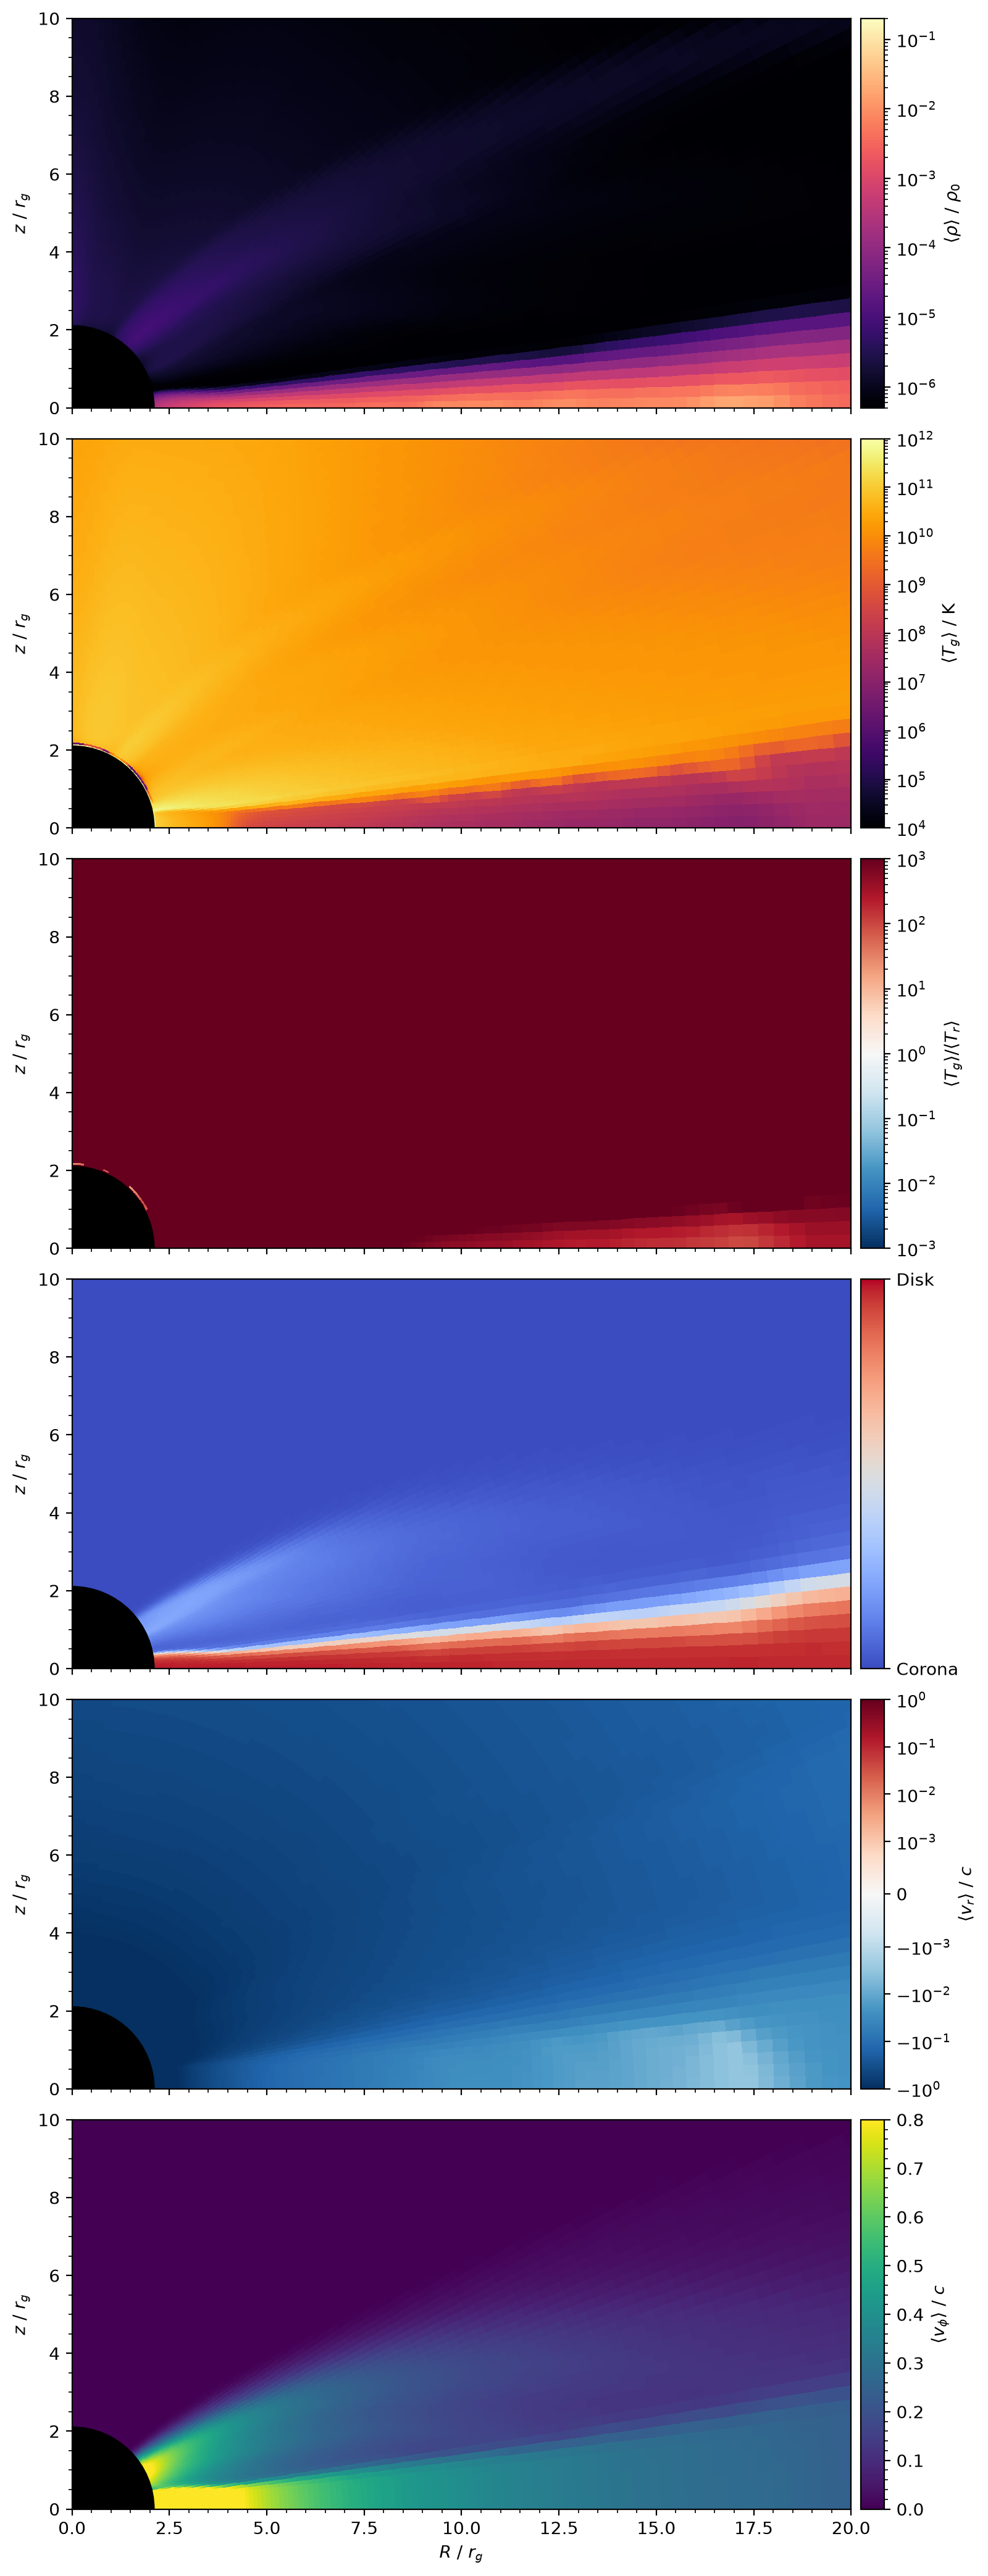

In [28]:
panels = [(MEAN2D['rho'], 'rho', r'$\langle\rho\rangle\ /\ \rho_0$'),
          (MEAN2D['T_g'], 'Tg', r'$\langle T_g\rangle\ /\ \mathrm{K}$'),
          (MEAN2D['T_g'] / np.maximum(MEAN2D['T_r'], 1.0), 'ratio', r'$\langle T_g\rangle / \langle T_r\rangle$'),
          (MEAN2D['f'], 'f', None),
          (MEAN2D['vr'], 'vr', r'$\langle v_r\rangle\ /\ c$'),
          (MEAN2D['vphi'], 'vphi', r'$\langle v_\phi\rangle\ /\ c$')]

fig, grid = map_grid(len(panels), 1, (0, 20), (0, 10), width=8.0, cbar_mode='each')

for ax, cax, (data, key, lab) in zip(grid, grid.cbar_axes, panels):
    im = draw_map(ax, data, FIELDS[key]['norm'], cmap=FIELDS[key]['cmap'])
    add_colorbar(fig, im, cax, lab)

plt.show()

#### 5.4. Vertical

Mean vertical profiles at the select radii against $z/R$ in terms of density, gas and radiation pressure, gas and radiation temperature,
the radiative support $\Gamma_z$ and the velocity $v_z$ in vertical direction. The dotted line marks the $\langle f\rangle = 0.5$ mean disk surface.

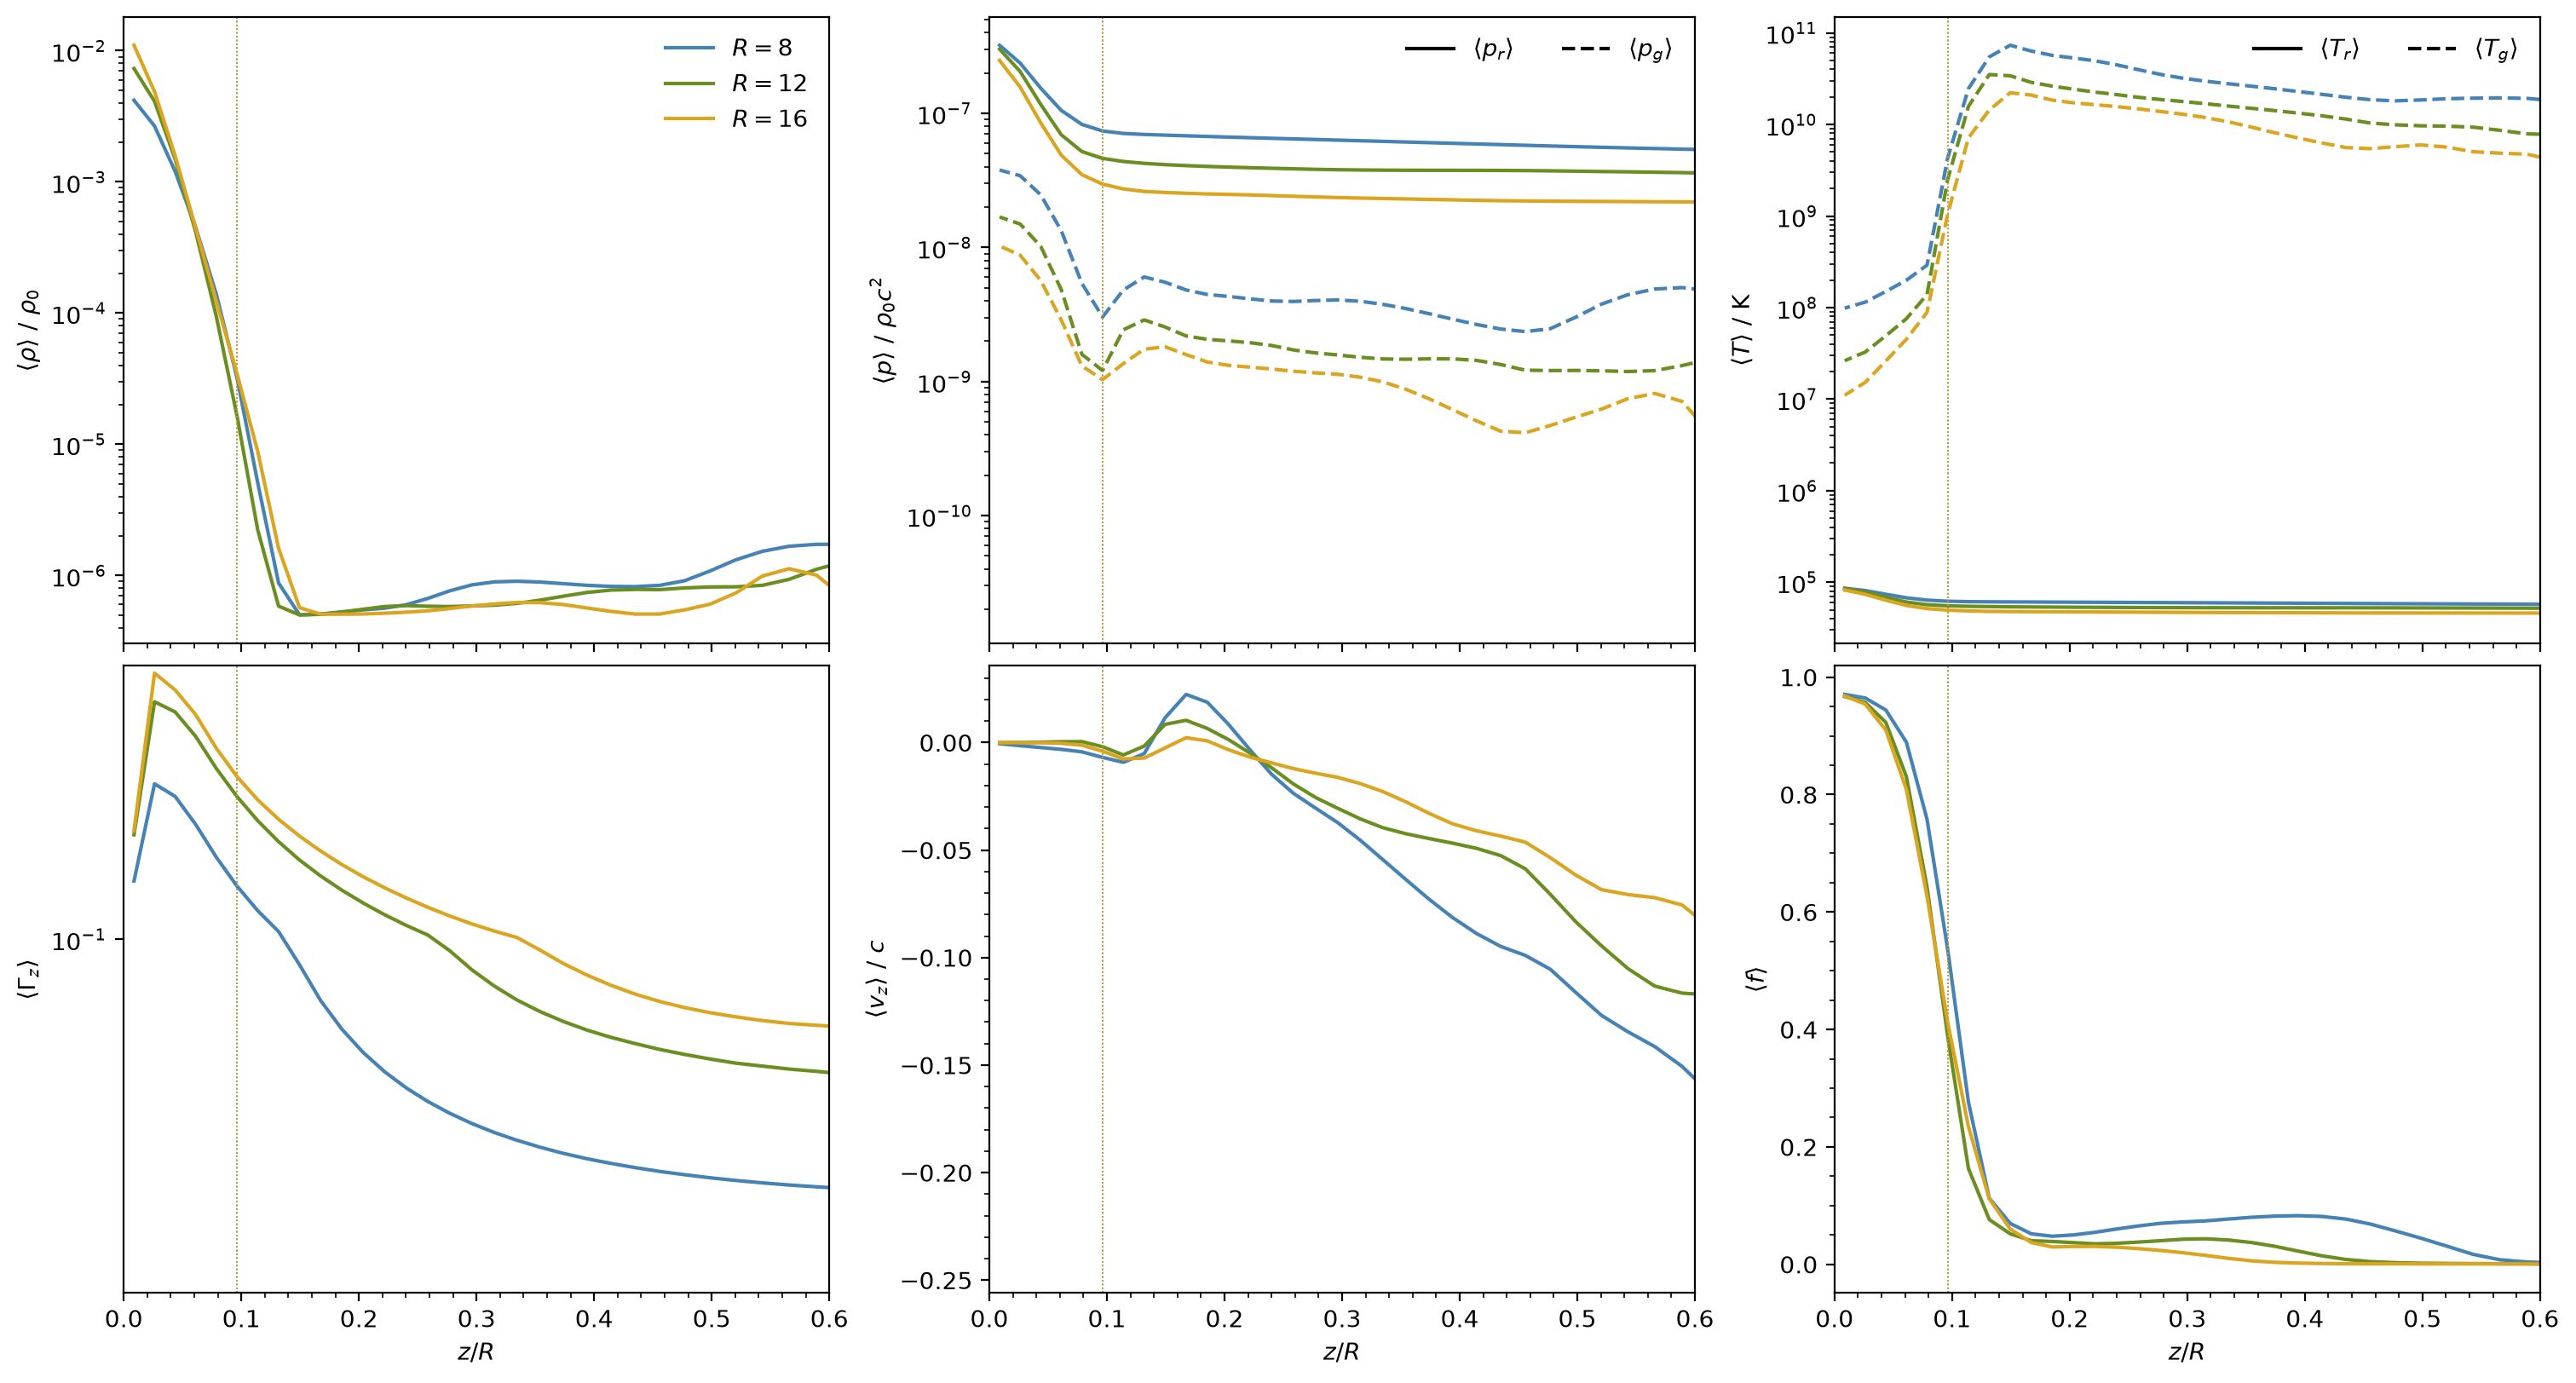

In [29]:
zr = COT

fig, axs = plt.subplots(2, 3, figsize=[15, 8], sharex=True)

for R0 in R_PROFILES:
    P = PROF[R0]

    line, = axs[0, 0].semilogy(zr, P['rho'], label=f"$R = {R0:g}$")
    c = line.get_color()

    axs[0, 1].semilogy(zr, P['p_rad'], color=c)
    axs[0, 1].semilogy(zr, P['p_gas'], color=c, ls='--')
    axs[0, 2].semilogy(zr, P['T_r'], color=c)
    axs[0, 2].semilogy(zr, P['T_g'], color=c, ls='--')
    axs[1, 0].plot(zr, P['Gamma_z'], color=c)
    axs[1, 1].plot(zr, P['v_z'], color=c)
    axs[1, 2].plot(zr, P['f'], color=c)

    surface = zr[np.nanargmin(np.abs(P['f'] - 0.5))]
    for ax in axs.flat:
        ax.axvline(surface, color=c, lw=0.6, ls=':')

axs[1, 0].set_yscale('symlog', linthresh=1e-1)
axs[0, 0].set_xlim(0, 0.6)

axs[0, 0].set_ylabel(r'$\langle\rho\rangle\ /\ \rho_0$')
axs[0, 1].set_ylabel(r'$\langle p\rangle\ /\ \rho_0 c^2$')
axs[0, 2].set_ylabel(r'$\langle T\rangle\ /\ \mathrm{K}$')
axs[1, 0].set_ylabel(r'$\langle\Gamma_z\rangle$')
axs[1, 1].set_ylabel(r'$\langle v_z\rangle\ /\ c$')
axs[1, 2].set_ylabel(r'$\langle f\rangle$')
for ax in axs[1]:
    ax.set_xlabel(r'$z/R$')

axs[0, 0].legend()
axs[0, 1].legend(handles=[Line2D([], [], color='k', label=r'$\langle p_r\rangle$'), Line2D([], [], color='k', ls='--', label=r'$\langle p_g\rangle$')],
                 ncol=2, loc='upper right')
axs[0, 2].legend(handles=[Line2D([], [], color='k', label=r'$\langle T_r\rangle$'), Line2D([], [], color='k', ls='--', label=r'$\langle T_g\rangle$')],
                 ncol=2, loc='upper right')

plt.show()

#### 5.5. Balance

The vertical resolution of the disk is the number of polar cells per scale height $(H/R)/\Delta\theta_\mathrm{mid}$ at the midplane. Below a few cells per scale height the vertical structure, and with it the radiative diffusion out of the disk, is not resolved. 

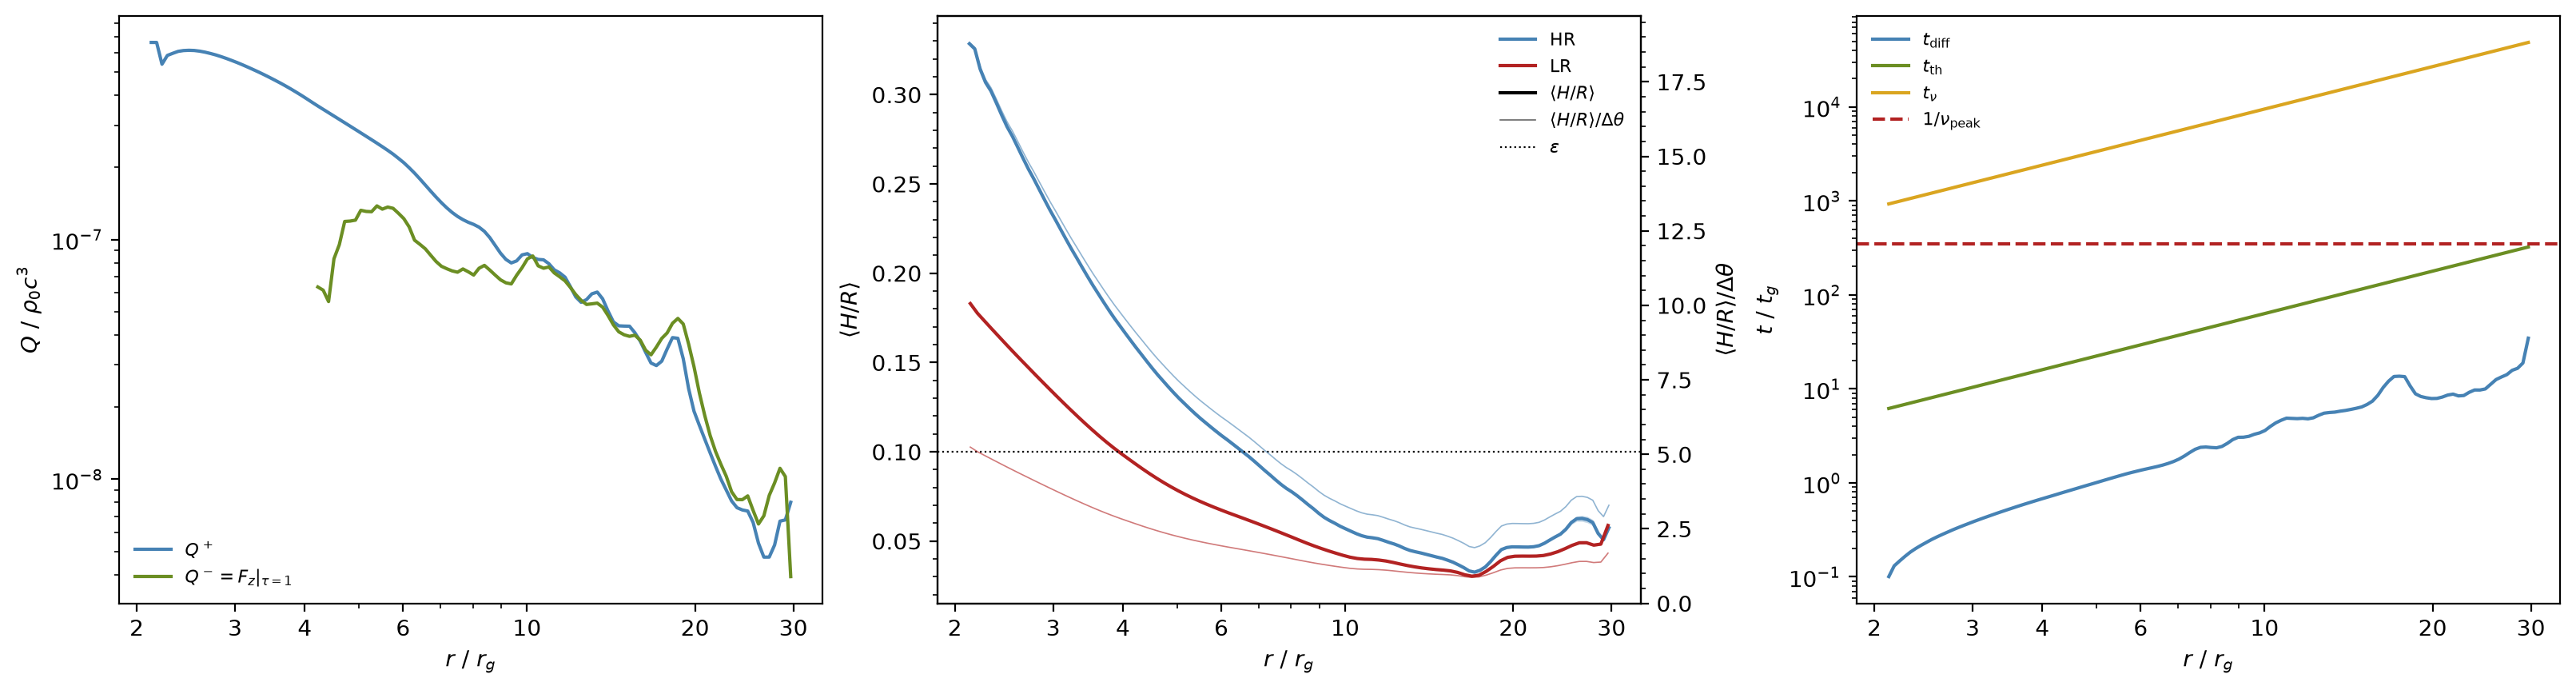

R =  8.0:  HR: H/R = 0.078, 4.5 cells per H,   LR: H/R = 0.052, 1.5 cells per H
R = 12.0:  HR: H/R = 0.049, 2.8 cells per H,   LR: H/R = 0.038, 1.1 cells per H
R = 20.0:  HR: H/R = 0.047, 2.7 cells per H,   LR: H/R = 0.041, 1.2 cells per H


In [30]:
for run in RUNS:
    run['hr_mean'], run['hr_se'] = mean_se(run['C']['hr'][run['sel']], run['dt'])
    run['cells_H'] = run['hr_mean'] / run['dth_mid']

tau_mid = KAPPA_ES * RHO0 * R_G * RUN['sig_mean'] / 2.0
t_diff = tau_mid * RUN['hr_mean'] * R_C

fig, axs = plt.subplots(1, 3, figsize=[16, 4.2])

ax = axs[0]
ax.loglog(R_C, QP, label=r'$Q^+$')
ax.loglog(R_C, np.where(QM > 0, QM, np.nan), label=r'$Q^- = F_z|_{\tau = 1}$')

ax.set_xlabel(r'$r\ /\ r_g$')
ax.set_ylabel(r'$Q\ /\ \rho_0 c^3$')

ax.legend(fontsize=8, loc='lower left')

ax = axs[1]
axr = ax.twinx()
for run in RUNS:
    ax.plot(run['r'], run['hr_mean'], color=run['color'], ls=run['ls'])
    ax.fill_between(run['r'], run['hr_mean'] - run['hr_se'], run['hr_mean'] + run['hr_se'], color=run['color'], alpha=0.3, lw=0)
    axr.plot(run['r'], run['cells_H'], color=run['color'], ls=run['ls'], lw=0.6, alpha=0.6)
ax.axhline(EPS, color='k', ls=':', lw=0.8)

ax.set_xscale('log')
axr.set_ylim(0, None)

ax.set_xlabel(r'$r\ /\ r_g$')
ax.set_ylabel(r'$\langle H/R\rangle$')
axr.set_ylabel(r'$\langle H/R\rangle / \Delta\theta$')

run_legend(ax, color=True, extra=[(r'$\langle H/R\rangle$', dict()),
                                  (r'$\langle H/R\rangle / \Delta\theta$', dict(lw=0.6, alpha=0.6)),
                                  (r'$\epsilon$', dict(ls=':', lw=0.8))], fontsize=8)

ax = axs[2]
ax.loglog(R_C, t_diff, label=r'$t_\mathrm{diff}$')
ax.loglog(R_C, t_thermal(R_C), label=r'$t_\mathrm{th}$')
ax.loglog(R_C, t_viscous(R_C), label=r'$t_\nu$')
ax.axhline(1 / F_PEAK, color='firebrick', ls='--', label=r'$1/\nu_\mathrm{peak}$')

ax.set_xlabel(r'$r\ /\ r_g$')
ax.set_ylabel(r'$t\ /\ t_g$')

ax.legend(fontsize=8)

for ax in axs:
    plain_log(ax, 'x')

plt.show()

for R0 in [8.0, 12.0, 20.0]:
    print(f"R = {R0:4.1f}:  " + ',   '.join(f"{run['label']}: H/R = {np.interp(R0, run['r'], run['hr_mean']):.3f},"
                                          f" {np.interp(R0, run['r'], run['cells_H']):.1f} cells per H" for run in RUNS))

#### 5.6. Heating

The viscous heat is deposited in the gas and leaves it mainly through the Compton exchange with the radiation. In the midplane, per
unit volume, the heating and the two cooling rates are

$$q^+ = \nu_1\left(R\,\frac{\partial\,\Omega}{\partial R}\right)^2 \qquad
\Lambda_C = \rho\,\kappa_C\,c\left(a T_g^4 - E_r\right) = \rho\,\kappa_\mathrm{es}\,c\,E_r\,\frac{4 k_B\,(T_g - T_r)}{m_e c^2} \qquad
\Lambda_\mathrm{ff} = \rho\,\kappa_\mathrm{ff+bf}\,c\left(a T_g^4 - E_r\right)$$

with the opacities defined before including the $f_d$ and $g_v$ gates. The second form of $\Lambda_C$ holds below
$T_\mathrm{max} = 10^9\,\mathrm{K}$ temperature. Relative to the thermal energy $u_g = p/(\gamma - 1)$ of the gas, they define

$$t_\mathrm{heat} = \frac{u_g}{q^+} \qquad t_C = \frac{u_g}{\Lambda_C} \qquad t_\mathrm{ff} = \frac{u_g}{\Lambda_\mathrm{ff}}$$

for the heating and cooling times. In thermal equilibrium of the gas $q^+ = \Lambda_C + \Lambda_\mathrm{ff}$, so $t_\mathrm{heat}$ equals the combined cooling time. Times much shorter than the orbital time $1/\Omega$ mean that the gas temperature follows the heating instantly, and the thermal evolution of the disk is set by the radiation. Here $\nu_1$ is the viscosity output of each run and the shear comes from the midplane $v_\phi$ velocity. Other stress components and compressional heating in the waves are not part of the $q^+$ term. Lines show the median over the steady window of each run, the bands the one $\sigma$ range, for the ratio in both runs. The plunging region inside $r = 4$ is excluded.

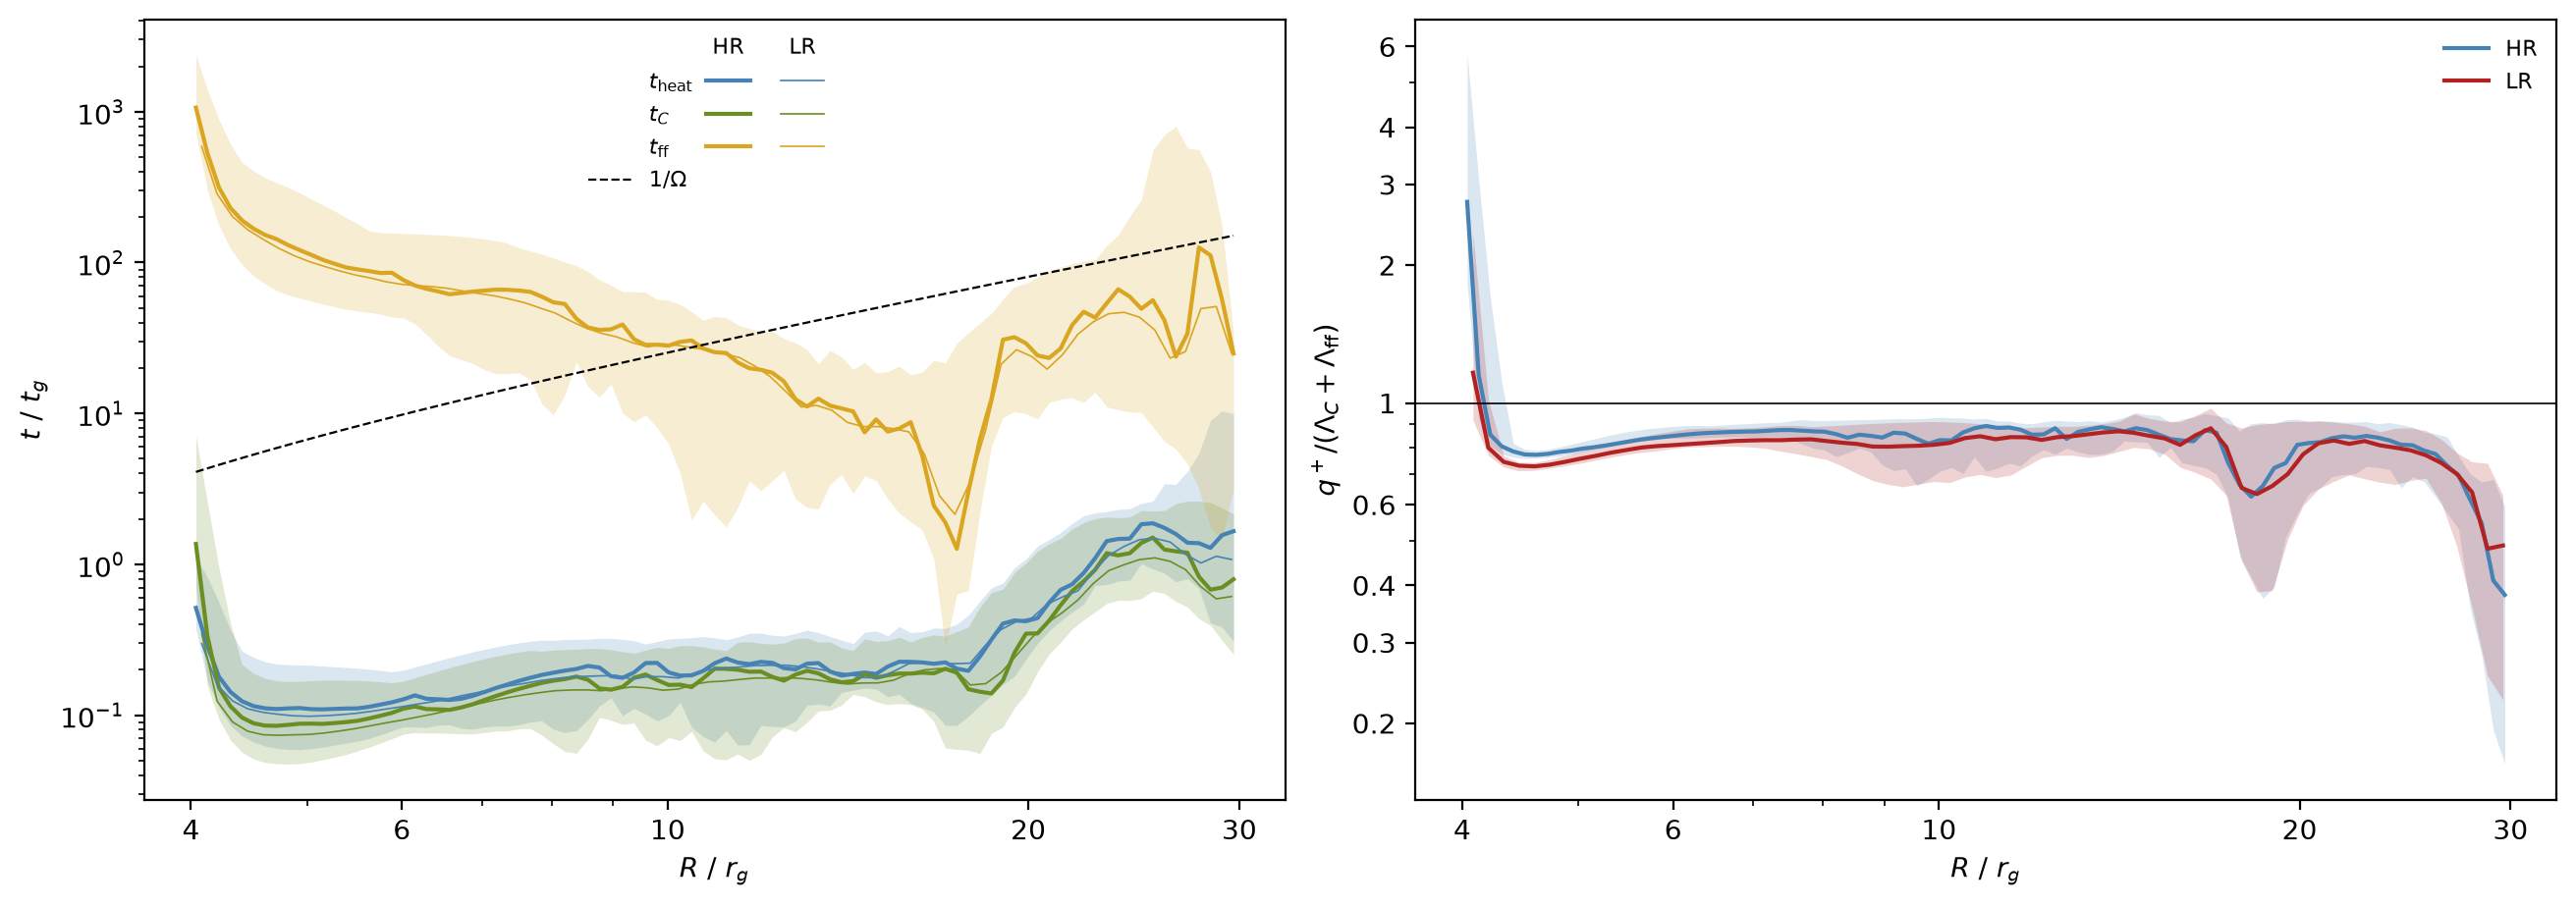

R =  8.0:  HR: t_heat = 0.19, t_C = 0.168, q+/L = 0.87,   LR: t_heat = 0.173, t_C = 0.144, q+/L = 0.83
R = 10.0:  HR: t_heat = 0.194, t_C = 0.159, q+/L = 0.83,   LR: t_heat = 0.179, t_C = 0.147, q+/L = 0.81
R = 12.0:  HR: t_heat = 0.225, t_C = 0.192, q+/L = 0.85,   LR: t_heat = 0.213, t_C = 0.176, q+/L = 0.84
R = 15.0:  HR: t_heat = 0.192, t_C = 0.178, q+/L = 0.87,   LR: t_heat = 0.177, t_C = 0.164, q+/L = 0.85
R = 20.0:  HR: t_heat = 0.423, t_C = 0.347, q+/L = 0.81,   LR: t_heat = 0.435, t_C = 0.308, q+/L = 0.76

times in t_g, medians over the steady window


In [31]:
def compton_opacity(Tg, Tr):
    mc2 = CONST_me * CONST_c**2
    Tr4 = Tr**4
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        low = KAPPA_ES * 4.0 * CONST_kB * Tr4 / (mc2 * (Tg + Tr) * (Tg**2 + Tr**2))
        high = KAPPA_ES * 4.0 * CONST_kB * Tr4 * (T_COMPTON_MAX - Tr) / (mc2 * (Tg**4 - Tr4))
    k = np.where(Tg <= T_COMPTON_MAX, low, np.where(Tr < T_COMPTON_MAX, high, 0.0))
    return np.minimum(np.nan_to_num(k), KAPPA_ES)

def heating_cooling(run):
    Cx, s, r = run['C'], run['sel'], run['r']

    rho, p = Cx['rho_mid'][s], Cx['prs_mid'][s]
    E = np.clip(Cx['enr_mid'][s], 0.0, None)
    Tg = K_T * p / rho
    Tr = (E / A_RAD)**0.25

    fd = np.clip((Cx['f_mid'][s] - 0.05) / 0.95, 0.0, None)
    beta = np.sqrt(Cx['vr_mid'][s]**2 + Cx['vphi_mid'][s]**2)
    gv = 1.0 / (1.0 + np.exp(np.minimum((beta - 0.9) / 0.03, 50.0)))

    shear = r * np.gradient(Cx['vphi_mid'][s] / r, r, axis=1)
    u_g = p / (GAMMA - 1.0)
    excess = A_RAD * Tg**4 - E

    q_plus = Cx['nu_mid'][s] * shear**2
    L_C = rho * gv * fd * compton_opacity(Tg, Tr) * KAPPA_CODE * excess
    L_ff = rho * gv * fd * K_FFBF * rho * RHO0 * np.maximum(Tg, 1e4)**-3.5 * KAPPA_CODE * excess

    with np.errstate(divide='ignore', invalid='ignore'):
        times = dict(t_heat=u_g / q_plus, t_C=u_g / L_C, t_ff=u_g / L_ff, ratio=q_plus / (L_C + L_ff))

    return {key: np.nanpercentile(np.where(np.isfinite(val) & (val > 0), val, np.nan), [16, 50, 84], axis=0)
            for key, val in times.items()}

times = [('t_heat', r'$t_\mathrm{heat}$'), ('t_C', r'$t_C$'), ('t_ff', r'$t_\mathrm{ff}$')]
lws = (1.5, 0.6)

fig, axs = plt.subplots(1, 2, figsize=[13, 4.5])

for run, lw in zip(RUNS, lws):
    run['HC'] = HC = heating_cooling(run)
    r = run['r']
    m = r >= R_MIN_HC

    for k, (key, _) in enumerate(times):
        axs[0].plot(r[m], HC[key][1][m], color=f"C{k}", lw=lw)
        if run is RUN:
            axs[0].fill_between(r[m], HC[key][0][m], HC[key][2][m], color=f"C{k}", alpha=0.2, lw=0)

    axs[1].plot(r[m], HC['ratio'][1][m], color=run['color'], ls=run['ls'])
    axs[1].fill_between(r[m], HC['ratio'][0][m], HC['ratio'][2][m], color=run['color'], alpha=0.2, lw=0)

R_hc = R_C[R_C >= R_MIN_HC]
axs[0].plot(R_hc, 1.0 / omega_pw(R_hc), 'k--', lw=0.8)
axs[1].axhline(1.0, color='k', lw=0.6)

for ax in axs:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$R\ /\ r_g$')
    plain_log(ax, 'x')
plain_log(axs[1], 'y')

axs[0].set_ylabel(r'$t\ /\ t_g$')
axs[1].set_ylabel(r'$q^+ / (\Lambda_C + \Lambda_\mathrm{ff})$')

run_table(axs[0], [(lab, dict(color=f"C{k}")) for k, (_, lab) in enumerate(times)], shared=[(r'$1/\Omega$', dict(ls='--', lw=0.8))],
          columns=[(run['label'], 'k', dict(lw=lw)) for run, lw in zip(RUNS, lws)], sample=False, fontsize=8)
run_legend(axs[1], color=True, fontsize=8)

plt.show()

for R0 in [8.0, 10.0, 12.0, 15.0, 20.0]:
    print(f"R = {R0:4.1f}:  " + ',   '.join(
        f"{run['label']}: t_heat = {np.interp(R0, run['r'], run['HC']['t_heat'][1]):.3g},"
        f" t_C = {np.interp(R0, run['r'], run['HC']['t_C'][1]):.3g},"
        f" q+/L = {np.interp(R0, run['r'], run['HC']['ratio'][1]):.2f}" for run in RUNS))

print("\ntimes in t_g, medians over the steady window")

#### 5.7. Angular

On a sphere of radius $r$ the elevation is $\vartheta = \pi/2 - \theta$ above the midplane. The net accretion rate through the sphere
splits into contributions per elevation, summed over both hemispheres

$$\frac{\mathrm{d}\dot M_\mathrm{acc}}{\mathrm{d}\vartheta} = -2 \cdot 2\pi r^2 \cos\vartheta\,\rho\,v_r \qquad
\Phi_{\dot M}(\vartheta) = \frac{1}{\dot M_\mathrm{acc}(r)}\int_0^{\vartheta} \frac{\mathrm{d}\dot M_\mathrm{acc}}{\mathrm{d}\vartheta'}\,\mathrm{d}\vartheta'$$

normalized by the total through the sphere and given per degree, on a logarithmic scale so that inflow above the disk stands out.
Elevations with net outflow do not appear. Here $\Phi_{\dot M}$ is the fraction of the net accretion within the elevation $\vartheta$ of the
midplane, which the summary uses. Alongside are the mean density and the radial and azimuthal velocity. All radii are
shown together, reaching into the plunging region inside $R_\mathrm{isco}$ so that the angle at which gas falls in can be followed
with radius. Every stride frame of the steady window of each run is reloaded, the bands are block standard errors, and
dotted vertical lines mark the mean disk surface $\langle f\rangle = 0.5$ of the main run at each radius.

HR: 82 frames of the steady window
LR: 204 frames of the steady window


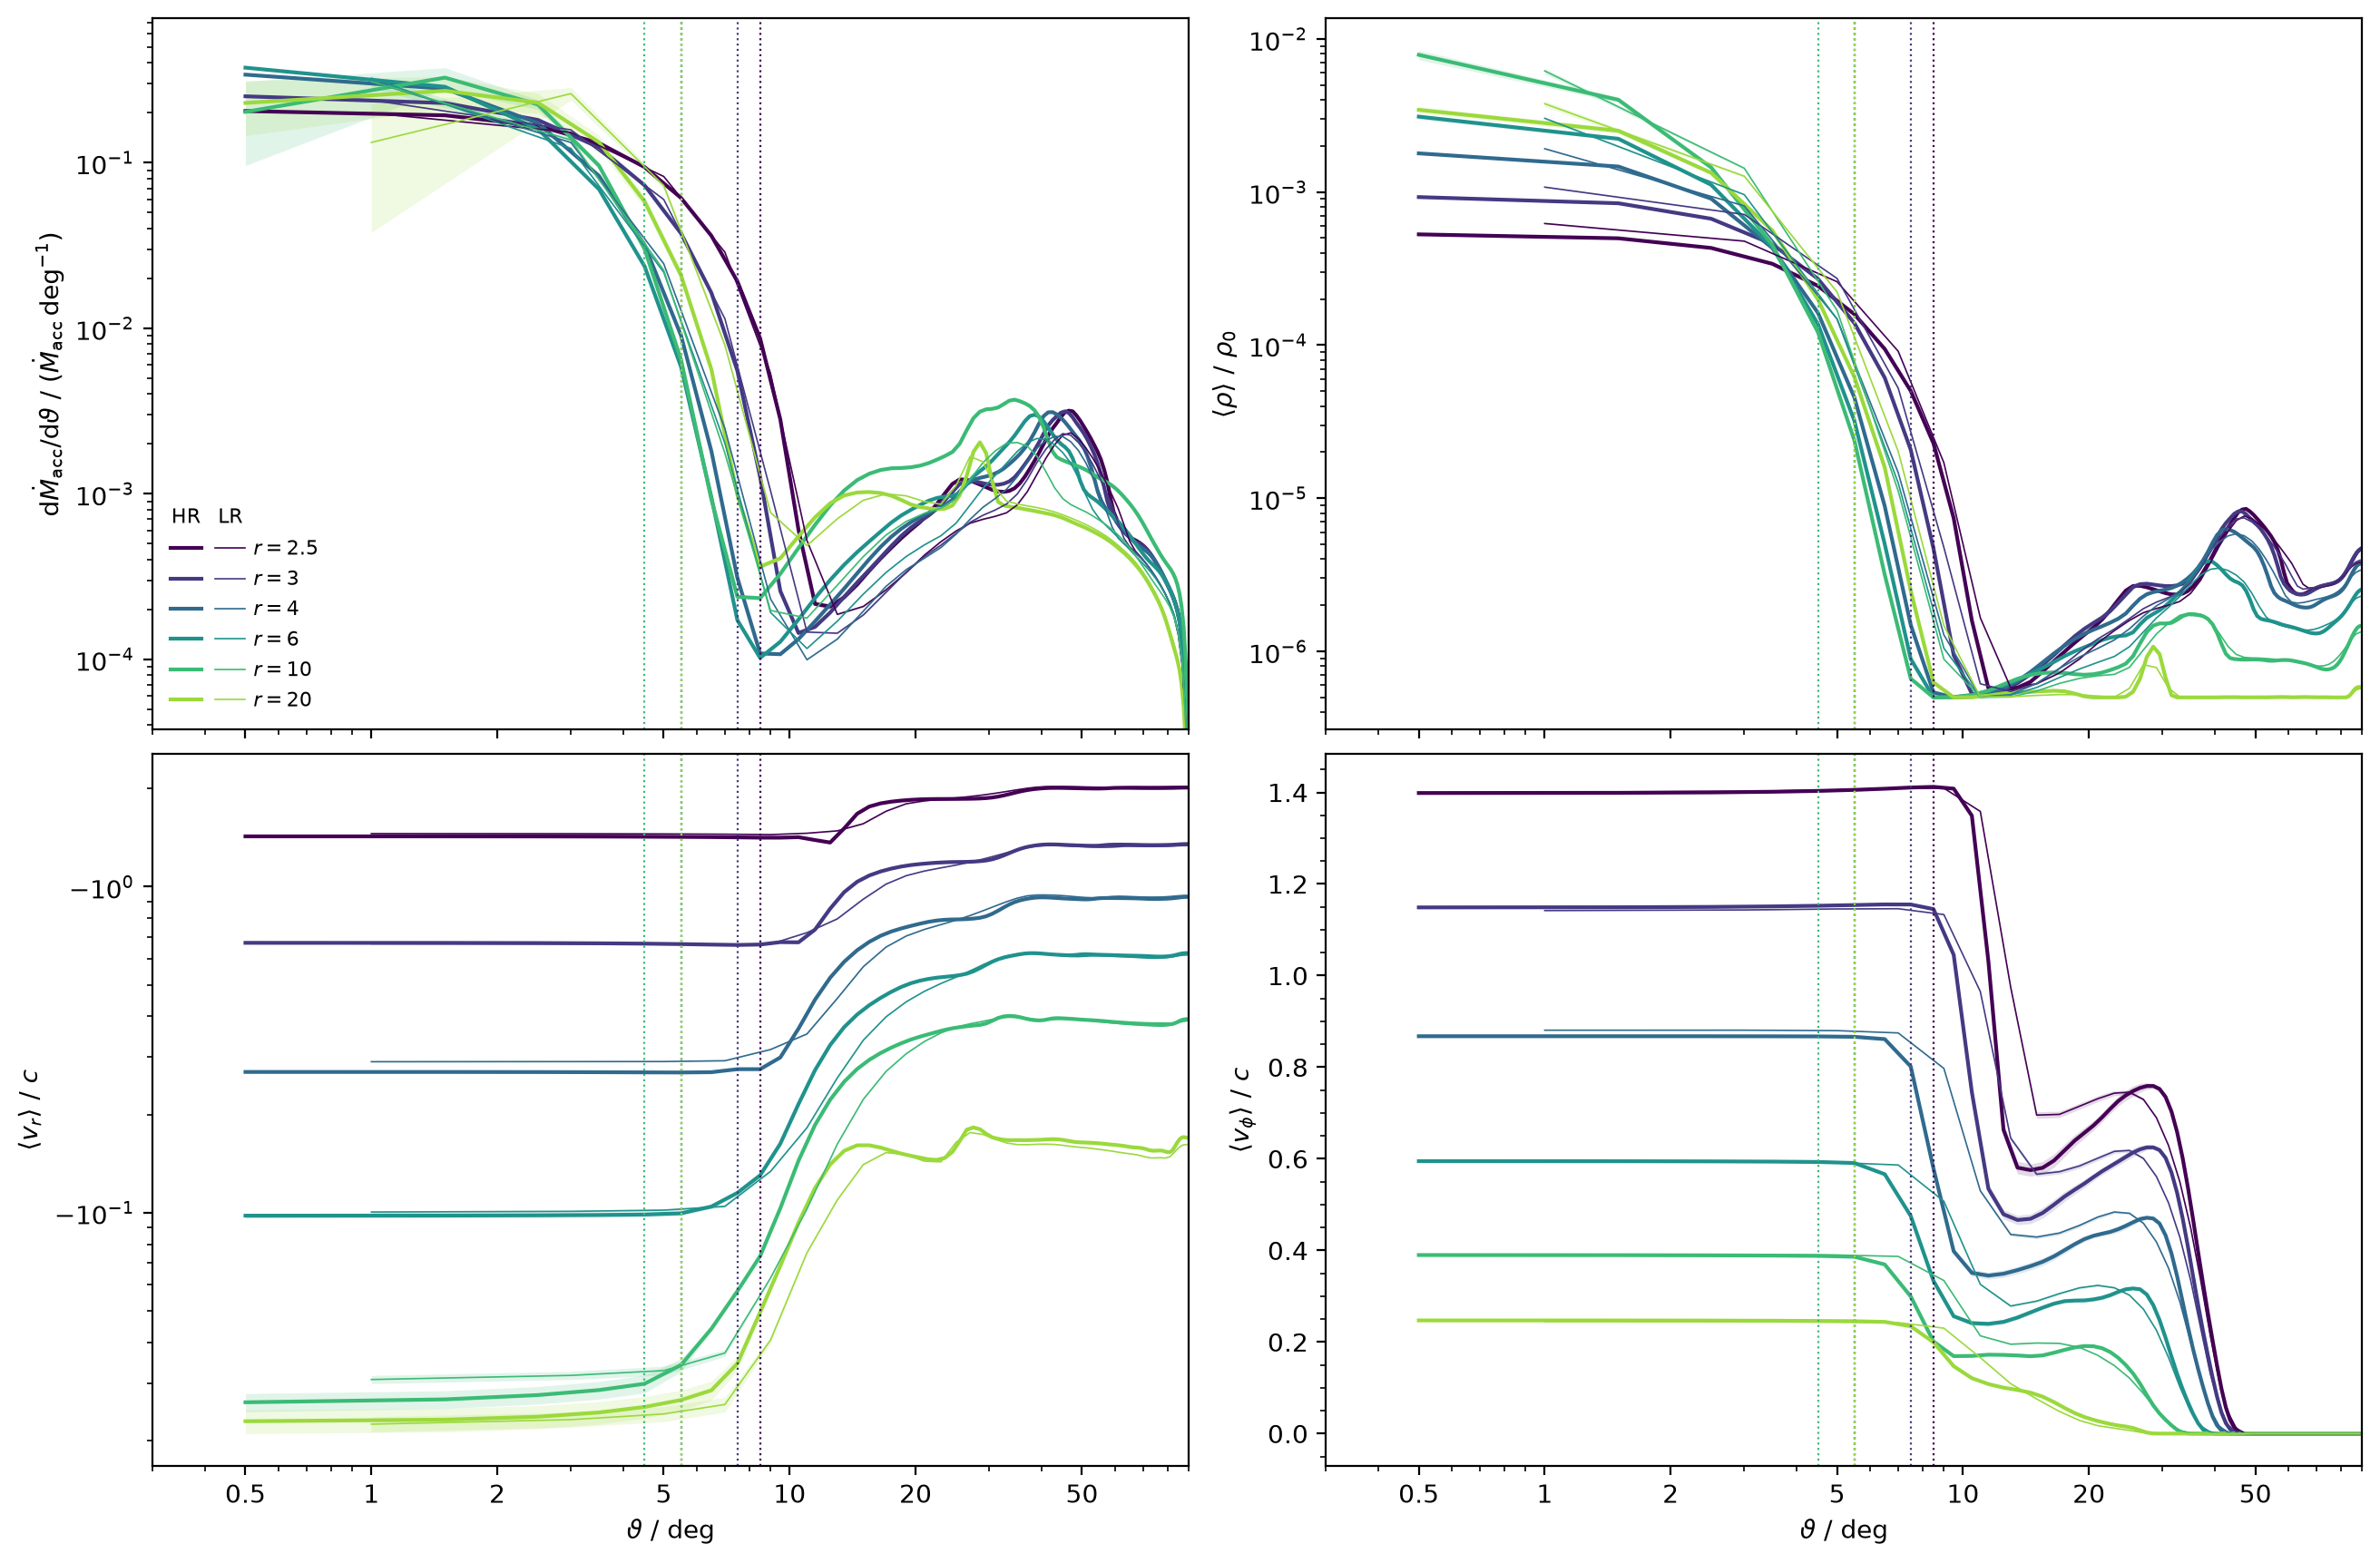

HR, r = 2.5:  50 % of the net accretion within   2.5 deg,  90 % within   7.5 deg,  disk surface at   8.5 deg with 92% of the accretion inside
HR, r = 3:  50 % of the net accretion within   2.5 deg,  90 % within   6.5 deg,  disk surface at   7.5 deg with 92% of the accretion inside
HR, r = 4:  50 % of the net accretion within   1.5 deg,  90 % within   4.5 deg,  disk surface at   5.5 deg with 92% of the accretion inside
HR, r = 6:  50 % of the net accretion within   1.5 deg,  90 % within   4.5 deg,  disk surface at   5.5 deg with 92% of the accretion inside
HR, r = 10:  50 % of the net accretion within   1.5 deg,  90 % within  20.5 deg,  disk surface at   4.5 deg with 88% of the accretion inside
HR, r = 20:  50 % of the net accretion within   1.5 deg,  90 % within   4.5 deg,  disk surface at   5.5 deg with 94% of the accretion inside
LR, r = 2.5:  50 % of the net accretion within   3.0 deg,  90 % within   7.0 deg,  disk surface at   9.0 deg with 94% of the accretion inside
LR, r = 3:  50

In [32]:
def angular_profiles(run, path, geo, radii=R_ANG, stride=PROFILE_STRIDE):
    outs = run['C']['outs'][run['sel']][::stride]
    idx = np.array([int(np.argmin(np.abs(geo['R_C'] - r0))) for r0 in radii])
    r = geo['R_C'][idx][:, None]
    sth = np.sin(geo['TH_C'])[None, :]

    rec = {key: [] for key in ['mdot', 'rho', 'vr', 'vphi', 'f']}
    for n in outs:
        F = {key: val[idx, :] for key, val in load(n, path, geo).items()}
        rec['mdot'].append(-HEMI * 2.0 * np.pi * r**2 * sth * F['rho'] * F['vx1'])
        rec['rho'].append(F['rho'])
        rec['vr'].append(F['vx1'])
        rec['vphi'].append(F['vx3'])
        rec['f'].append(F['diskfrac'])

    out = dict(elev=90.0 - np.degrees(geo['TH_C']), dth=geo['DTH'], n=len(outs))
    for key, val in rec.items():
        out[key], out[key + '_se'] = mean_se(np.array(val), run['dt'] * stride)

    total = np.sum(out['mdot'] * out['dth'][None, :], axis=1, keepdims=True)
    out['mdot_dist'] = out['mdot'] / total * np.pi / 180.0
    out['mdot_dist_se'] = out['mdot_se'] / np.abs(total) * np.pi / 180.0
    out['mdot_cum'] = np.cumsum((out['mdot'] * out['dth'][None, :])[:, ::-1], axis=1)[:, ::-1] / total
    out['surface'] = np.array([out['elev'][np.nonzero(row >= 0.5)[0][0]] if (row >= 0.5).any() else np.nan for row in out['f']])

    return out

for run, path, geo in [(RUN, MAIN_PATH, MAIN_GEO), (REF, REF_PATH, REF_GEO)]:
    if run is not None:
        run['ANG'] = angular_profiles(run, path, geo)
        print(f"{run['label']}: {run['ANG']['n']} frames of the steady window")

class NegativeLog(mpl.ticker.LogFormatterSciNotation):
    def __call__(self, x, pos=None):
        s = super().__call__(x, pos)
        return '$-' + s[1:] if s else s

RCOL = plt.cm.viridis(np.linspace(0.0, 0.85, len(R_ANG)))
ANG_LW = (1.5, 0.6)

panels = [('mdot_dist', r'$\mathrm{d}\dot M_\mathrm{acc}/\mathrm{d}\vartheta\ /\ (\dot M_\mathrm{acc}\,\mathrm{deg}^{-1})$', 1.0),
          ('rho', r'$\langle\rho\rangle\ /\ \rho_0$', 1.0),
          ('vr', r'$\langle v_r\rangle\ /\ c$', -1.0),
          ('vphi', r'$\langle v_\phi\rangle\ /\ c$', None)]

fig, axs = plt.subplots(2, 2, figsize=[13, 8.5], sharex=True)

for ax, (key, lab, sign) in zip(axs.flat, panels):
    for run, lw in zip(RUNS, ANG_LW):
        A = run['ANG']
        for k in range(len(R_ANG)):
            y, e = A[key][k], A[key + '_se'][k]
            lo, hi = y - e, y + e

            if sign is not None:
                y, lo, hi = sign * y, np.minimum(sign * lo, sign * hi), np.maximum(sign * lo, sign * hi)
                y, lo, hi = (np.where(v > 0, v, np.nan) for v in (y, lo, hi))
                lo = np.where(np.isfinite(lo), lo, y)

            ax.plot(A['elev'], y, color=RCOL[k], lw=lw)
            ax.fill_between(A['elev'], lo, hi, color=RCOL[k], alpha=0.15, lw=0)

    for k in range(len(R_ANG)):
        if np.isfinite(RUN['ANG']['surface'][k]):
            ax.axvline(RUN['ANG']['surface'][k], color=RCOL[k], ls=':', lw=0.8)

    if sign is not None:
        ax.set_yscale('log')
    if sign == -1.0:
        ax.yaxis.set_major_formatter(NegativeLog())
        ax.yaxis.set_minor_formatter(NegativeLog(labelOnlyBase=False))

    if key == 'mdot_dist':
        top = max(np.nanmax(run['ANG']['mdot_dist']) for run in RUNS)
        ax.set_ylim(top * 1e-4, top * 2.0)

    ax.set_xscale('log')
    ax.set_xlim(0.3, 90.0)
    plain_log(ax, 'x', mantissas=(1, 2, 5))

    ax.set_ylabel(lab)

for ax in axs[1]:
    ax.set_xlabel(r'$\vartheta\ /\ \mathrm{deg}$')

run_table(axs[0, 0], [(f"$r = {r0:g}$", dict(color=c)) for r0, c in zip(R_ANG, RCOL)], side='right',
          columns=[(run['label'], 'k', dict(lw=lw)) for run, lw in zip(RUNS, ANG_LW)], fontsize=8, loc='lower left', handlelength=1.5)

plt.show()

for run in RUNS:
    A = run['ANG']
    for k, r0 in enumerate(R_ANG):
        cum = A['mdot_cum'][k][::-1]
        el = A['elev'][::-1]
        half = el[np.argmax(cum >= 0.5)] if (cum >= 0.5).any() else np.nan
        most = el[np.argmax(cum >= 0.9)] if (cum >= 0.9).any() else np.nan
        inside = np.interp(A['surface'][k], el, cum) if np.isfinite(A['surface'][k]) else np.nan

        print(f"{run['label']}, r = {r0:g}:  50 % of the net accretion within {half:5.1f} deg,  90 % within {most:5.1f} deg,"
              f"  disk surface at {A['surface'][k]:5.1f} deg with {inside:.0%} of the accretion inside")

### 6. Comparison

Results of both runs, each with its standard error, and the normalized difference

$$z = \frac{X_\mathrm{main} - X_\mathrm{ref}}{\sqrt{\mathrm{SE}_\mathrm{main}^2 + \mathrm{SE}_\mathrm{ref}^2}}$$

so $|z| < 2$ counts as consistent. Each run uses its own steady window and spectral series. With only two resolutions, consistency
means that the quantity is insensitive to the resolution step taken, not that it is converged.

In [33]:
def at(run, key, R0):
    return np.interp(R0, run['r'], run[key])

def comparison_rows(run):
    return [
        ("start of the steady window [t_g]", run['t_steady'], np.nan),
        ("<Mdot_acc(r_in)> [Mdot_Edd]", run['mdot_in_mean'] * scale, run['mdot_in_se'] * scale),
        ("<L(r_out)> [L_Edd]", run['L_out_mean'] * L0 / L_EDD, run['L_out_se'] * L0 / L_EDD),
        ("eta_rad", run['eta'], run['eta_se']),
        ("<M_d> [code]", run['M_d_mean'], run['M_d_se']),
        ("dominant frequency [1e-3 / t_g]", run['f_peak'] * 1e3, 0.5 * run['df_peak'] * 1e3),
        (f"mean phase speed r = {R_PHASE_REF:g}-15 [c]", run['v_mean'], run['v_mean_err']),
        ("alpha_eff / alpha at R = 10", at(run, 'alpha_ratio', 10.0), at(run, 'alpha_ratio', 10.0) * at(run, 'alpha_ratio_rel', 10.0)),
        ("alpha_eff / alpha at R = 15", at(run, 'alpha_ratio', 15.0), at(run, 'alpha_ratio', 15.0) * at(run, 'alpha_ratio_rel', 15.0)),
        ("<H/R> at R = 10", at(run, 'hr_mean', 10.0), at(run, 'hr_se', 10.0)),
        ("cells per H at R = 10", at(run, 'cells_H', 10.0), np.nan),
        ("delta_rms at R = 10", at(run, 'd_rms', 10.0), np.nan),
        ("R_eq median [r_g]", run['R_eq_stats'][1], np.nan),
    ]

def fmt_value(x, ex):
    return f"{x:.4g}" + (f" +- {ex:.2g}" if np.isfinite(ex) else "")

if REF is None:
    print("no reference run")
else:
    print(f"{'':42s}{RUN['label']:>24s}{REF['label']:>24s}{'z':>8s}")

    for (name, a, ea), (_, b, eb) in zip(comparison_rows(RUN), comparison_rows(REF)):
        z = (a - b) / np.sqrt(ea**2 + eb**2) if np.isfinite(ea) and np.isfinite(eb) and (ea > 0 or eb > 0) else np.nan
        zs = f"{z:+8.1f}" if np.isfinite(z) else f"{'':8s}"
        print(f"{name:42s}{fmt_value(a, ea):>24s}{fmt_value(b, eb):>24s}{zs}")

                                                                HR                      LR       z
start of the steady window [t_g]                         2.372e+04                    9225        
<Mdot_acc(r_in)> [Mdot_Edd]                     0.07309 +- 0.00036       0.09049 +- 0.0003   -37.1
<L(r_out)> [L_Edd]                              0.05628 +- 0.00022      0.07031 +- 0.00018   -50.0
eta_rad                                          0.04812 +- 0.0003       0.04856 +- 0.0002    -1.2
<M_d> [code]                                        18.1 +- 0.0084         22.26 +- 0.0062  -398.3
dominant frequency [1e-3 / t_g]                       2.863 +- 0.2            2.869 +- 0.2    -0.0
mean phase speed r = 7-15 [c]                     0.019 +- 0.00022      0.01953 +- 0.00023    -1.6
alpha_eff / alpha at R = 10                         2.647 +- 0.029          2.525 +- 0.024    +3.2
alpha_eff / alpha at R = 15                         2.051 +- 0.021          2.031 +- 0.013    +0.8
<H/R> at R

### Summary

In [34]:
def summary_rows(run):
    period = 1.0 / run['f_peak']
    lo, med, hi = run['R_eq_stats']
    return [
        ("start of the steady window", f"{run['t_steady']:.0f} t_g = {run['t_steady'] * T_G / DAY:.1f} days"),
        ("inflow equilibrium radius", f"{med:.1f} r_g ({lo:.1f} - {hi:.1f}),  viscous estimate {r_viscous(run['t'][-1]):.1f} r_g"),
        ("mean accretion rate through r_in", f"{run['mdot_in_mean'] * MDOT0 * YEAR / CONST_Msun:.3f} Msun/yr = {run['mdot_in_mean'] * scale:.4f} Mdot_Edd"),
        ("mean luminosity through r_out", f"{run['L_out_mean'] * L0:.3e} erg/s = {run['L_out_mean'] * L0 / L_EDD:.4f} L_Edd"),
        ("radiative efficiency", f"{run['eta']:.4f} +- {run['eta_se']:.4f}   (eta_isco = {ETA:.4f})"),
        ("effective viscosity at R = 10", f"alpha_eff / alpha = {at(run, 'alpha_ratio', 10.0):.2f}"),
        ("dominant wave period", f"{period:.0f} t_g = {period * T_G / DAY:.2f} days"),
        ("mean phase speed", f"{run['v_mean']:.4f} +- {run['v_mean_err']:.4f} c  (r = {R_PHASE_REF:g}-15)"),
        ("cells per scale height at R = 10", f"{at(run, 'cells_H', 10.0):.1f}"),
    ]

for run in RUNS:
    rows = summary_rows(run)
    if run is RUN:
        rows.append(("floor residual of the mass budget", f"{FLOOR_FRAC:+.2%} of the mass accreted (z = {FLOOR_Z:+.1f}),"
                                                         f" control volume r = {R_C[IA]:.2f}-{R_C[IB]:.2f}"))

    width = max(len(k) for k, _ in rows)
    print(run['label'])
    for k, v in rows:
        print(f"   {k:<{width}}  {v}")

HR
   start of the steady window         23725 t_g = 135.3 days
   inflow equilibrium radius          17.4 r_g (16.3 - 21.8),  viscous estimate 26.1 r_g
   mean accretion rate through r_in   0.304 Msun/yr = 0.0731 Mdot_Edd
   mean luminosity through r_out      8.276e+44 erg/s = 0.0563 L_Edd
   radiative efficiency               0.0481 +- 0.0003   (eta_isco = 0.0625)
   effective viscosity at R = 10      alpha_eff / alpha = 2.65
   dominant wave period               349 t_g = 1.99 days
   mean phase speed                   0.0190 +- 0.0002 c  (r = 7-15)
   cells per scale height at R = 10   3.3
   floor residual of the mass budget  -3.38% of the mass accreted (z = -369.0), control volume r = 2.48-24.85
LR
   start of the steady window        9225 t_g = 52.6 days
   inflow equilibrium radius         17.9 r_g (16.4 - 21.4),  viscous estimate 30.3 r_g
   mean accretion rate through r_in  0.376 Msun/yr = 0.0905 Mdot_Edd
   mean luminosity through r_out     1.034e+45 erg/s = 0.0703 L_Edd
   